Part A: Cropped-PlantDoc

In [1]:

from pathlib import Path
import subprocess

repo_url = "https://github.com/pratikkayal/PlantDoc-Dataset.git"
repo_path = Path("/content/PlantDoc-Dataset")

if repo_path.exists():
    print("PlantDoc repository already exists.")
else:
    subprocess.run(
        ["git", "clone", repo_url, str(repo_path)],
        check=True
    )

print("Repository location:", repo_path)

Repository location: /content/PlantDoc-Dataset


In [2]:
print("PLANTDOC REPOSITORY STRUCTURE")
print("=" * 50)

for item in sorted(repo_path.iterdir()):
    if item.is_dir():
        print(f"[FOLDER]    {item.name}")
    else:
        print(f"[FILE]      {item.name}")

PLANTDOC REPOSITORY STRUCTURE
[FOLDER]    .git
[FILE]      LICENSE.txt
[FILE]      PlantDoc_Examples.png
[FILE]      README.md
[FOLDER]    test
[FOLDER]    train


In [ ]:
# Cell 3
print("TRAIN FOLDER CONTENTS")
print("=" * 50)

train_path = repo_path / "train"

for item in sorted(train_path.iterdir()):
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        print(f"[FILE]   {item.name}")

print("\nTEST FOLDER CONTENTS")
print("=" * 50)

test_path = repo_path / "test"

for item in sorted(test_path.iterdir()):
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        print(f"[FILE]   {item.name}")

TRAIN FOLDER CONTENTS
[FOLDER] Apple Scab Leaf
[FOLDER] Apple leaf
[FOLDER] Apple rust leaf
[FOLDER] Bell_pepper leaf
[FOLDER] Bell_pepper leaf spot
[FOLDER] Blueberry leaf
[FOLDER] Cherry leaf
[FOLDER] Corn Gray leaf spot
[FOLDER] Corn leaf blight
[FOLDER] Corn rust leaf
[FOLDER] Peach leaf
[FOLDER] Potato leaf early blight
[FOLDER] Potato leaf late blight
[FOLDER] Raspberry leaf
[FOLDER] Soyabean leaf
[FOLDER] Squash Powdery mildew leaf
[FOLDER] Strawberry leaf
[FOLDER] Tomato Early blight leaf
[FOLDER] Tomato Septoria leaf spot
[FOLDER] Tomato leaf
[FOLDER] Tomato leaf bacterial spot
[FOLDER] Tomato leaf late blight
[FOLDER] Tomato leaf mosaic virus
[FOLDER] Tomato leaf yellow virus
[FOLDER] Tomato mold leaf
[FOLDER] Tomato two spotted spider mites leaf
[FOLDER] grape leaf
[FOLDER] grape leaf black rot

TEST FOLDER CONTENTS
[FOLDER] Apple Scab Leaf
[FOLDER] Apple leaf
[FOLDER] Apple rust leaf
[FOLDER] Bell_pepper leaf
[FOLDER] Bell_pepper leaf spot
[FOLDER] Blueberry leaf
[FOLDER] C

In [ ]:
# Cell 4
train_classes = sorted([
    item.name
    for item in train_path.iterdir()
    if item.is_dir()
])

test_classes = sorted([
    item.name
    for item in test_path.iterdir()
    if item.is_dir()
])

print("CLASS LABEL CHECK")
print("=" * 50)

print(f"Number of train classes : {len(train_classes)}")
print(f"Number of test classes  : {len(test_classes)}")

print("\nClasses only in train:")
print(sorted(set(train_classes) - set(test_classes)))

print("\nClasses only in test:")
print(sorted(set(test_classes) - set(train_classes)))

print("\nClasses present in both:")
print(len(set(train_classes) & set(test_classes)))

CLASS LABEL CHECK
Number of train classes : 28
Number of test classes  : 27

Classes only in train:
['Tomato two spotted spider mites leaf']

Classes only in test:
[]

Classes present in both:
27


In [5]:
# Cell 5
import pandas as pd

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

all_classes = sorted(set(train_classes) | set(test_classes))

class_counts = []

for class_name in all_classes:
    train_class_path = train_path / class_name
    test_class_path = test_path / class_name

    train_count = (
        sum(
            1 for file in train_class_path.iterdir()
            if file.is_file() and file.suffix.lower() in image_extensions
        )
        if train_class_path.exists()
        else 0
    )

    test_count = (
        sum(
            1 for file in test_class_path.iterdir()
            if file.is_file() and file.suffix.lower() in image_extensions
        )
        if test_class_path.exists()
        else 0
    )

    class_counts.append({
        "class_name": class_name,
        "train_images": train_count,
        "test_images": test_count,
        "total_images": train_count + test_count
    })

plantdoc_counts_df = pd.DataFrame(class_counts)

display(plantdoc_counts_df)

print("\nDATASET SUMMARY")
print("=" * 50)
print(f"Total train images : {plantdoc_counts_df['train_images'].sum()}")
print(f"Total test images  : {plantdoc_counts_df['test_images'].sum()}")
print(f"Total images       : {plantdoc_counts_df['total_images'].sum()}")

,class_name,train_images,test_images,total_images
0,Apple Scab Leaf,83,10,93
1,Apple leaf,82,9,91
2,Apple rust leaf,79,10,89
3,Bell_pepper leaf,53,8,61
4,Bell_pepper leaf spot,62,9,71
5,Blueberry leaf,106,11,117
6,Cherry leaf,47,10,57
7,Corn Gray leaf spot,64,4,68
8,Corn leaf blight,180,12,192
9,Corn rust leaf,106,10,116



DATASET SUMMARY
Total train images : 2342
Total test images  : 236
Total images       : 2578


In [6]:
# Cell 6
from collections import Counter

train_extensions = Counter()
test_extensions = Counter()

for class_name in train_classes:
    class_path = train_path / class_name
    
    for file in class_path.iterdir():
        if file.is_file():
            train_extensions[file.suffix.lower()] += 1

for class_name in test_classes:
    class_path = test_path / class_name
    
    for file in class_path.iterdir():
        if file.is_file():
            test_extensions[file.suffix.lower()] += 1

print("FILE EXTENSION CHECK")
print("=" * 50)

print("\nTrain:")
for extension, count in sorted(train_extensions.items()):
    print(f"{extension or '[no extension]':<15} {count}")

print("\nTest:")
for extension, count in sorted(test_extensions.items()):
    print(f"{extension or '[no extension]':<15} {count}")

FILE EXTENSION CHECK

Train:
.jpeg           1
.jpg            2340
.png            1

Test:
.jpg            236


In [7]:
# Cell 7
import kagglehub
from pathlib import Path

plantvillage_path = Path(
    kagglehub.dataset_download("aftaabahmedshaik/plantvillage-dataset")
)

print("PlantVillage dataset accessed successfully.")
print("Dataset path:", plantvillage_path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
PlantVillage dataset accessed successfully.
Dataset path: /kaggle/input/plantvillage-dataset


In [8]:
# Cell 8
print("PLANTVILLAGE DATASET STRUCTURE")
print("=" * 50)

for item in sorted(plantvillage_path.iterdir()):
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        print(f"[FILE]   {item.name}")

PLANTVILLAGE DATASET STRUCTURE
[FOLDER] color


In [9]:
# Cell 9
plantvillage_color_path = plantvillage_path / "color"

plantvillage_classes = sorted([
    item.name
    for item in plantvillage_color_path.iterdir()
    if item.is_dir()
])

print("PLANTVILLAGE CLASS LABELS")
print("=" * 50)

print(f"Number of classes: {len(plantvillage_classes)}")

for i, class_name in enumerate(plantvillage_classes, start=1):
    print(f"{i:2}. {class_name}")

PLANTVILLAGE CLASS LABELS
Number of classes: 38
 1. Apple___Apple_scab
 2. Apple___Black_rot
 3. Apple___Cedar_apple_rust
 4. Apple___healthy
 5. Blueberry___healthy
 6. Cherry_(including_sour)___Powdery_mildew
 7. Cherry_(including_sour)___healthy
 8. Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 9. Corn_(maize)___Common_rust_
10. Corn_(maize)___Northern_Leaf_Blight
11. Corn_(maize)___healthy
12. Grape___Black_rot
13. Grape___Esca_(Black_Measles)
14. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15. Grape___healthy
16. Orange___Haunglongbing_(Citrus_greening)
17. Peach___Bacterial_spot
18. Peach___healthy
19. Pepper,_bell___Bacterial_spot
20. Pepper,_bell___healthy
21. Potato___Early_blight
22. Potato___Late_blight
23. Potato___healthy
24. Raspberry___healthy
25. Soybean___healthy
26. Squash___Powdery_mildew
27. Strawberry___Leaf_scorch
28. Strawberry___healthy
29. Tomato___Bacterial_spot
30. Tomato___Early_blight
31. Tomato___Late_blight
32. Tomato___Leaf_Mold
33. Tomato___Septori

In [ ]:
# Cell 10
readme_path = repo_path / "README.md"

with open(readme_path, "r", encoding="utf-8") as file:
    readme_text = file.read()

print(readme_text)

# PlantDoc: A Dataset for Visual Plant Disease Detection

This repository contains the Cropped-PlantDoc dataset used for benchmarking classification models in the paper titled "PlantDoc: A Dataset for Visual Plant Disease Detection" which was accepted in the Research Track at ACM India Joint International Conference on Data Science and Management of Data (CoDS-COMAD 2020).

While the Object-Detection dataset can accessed through the following [link](https://github.com/pratikkayal/PlantDoc-Object-Detection-Dataset).

![Plantdoc Examples](PlantDoc_Examples.png)

## Abstract
India loses 35% of the annual crop yield due to plant diseases. Early detection of plant diseases remains difficult due to the lack of lab infrastructure and expertise. In this paper, we explore the possibility of computer vision approaches for scalable and early plant disease detection. The lack of availability of sufficiently large-scale non-lab data set remains a major challenge for enabling vision based plant dise

In [ ]:
# Cell 11
plantdoc_labels_df = plantdoc_counts_df[
    ["class_name", "train_images", "test_images", "total_images"]
].copy()

plantdoc_labels_df.index = range(1, len(plantdoc_labels_df) + 1)

display(plantdoc_labels_df)

,class_name,train_images,test_images,total_images
1,Apple Scab Leaf,83,10,93
2,Apple leaf,82,9,91
3,Apple rust leaf,79,10,89
4,Bell_pepper leaf,53,8,61
5,Bell_pepper leaf spot,62,9,71
6,Blueberry leaf,106,11,117
7,Cherry leaf,47,10,57
8,Corn Gray leaf spot,64,4,68
9,Corn leaf blight,180,12,192
10,Corn rust leaf,106,10,116


MAPPING (PLANTDOC -> PLANTVILLAGE)

In [12]:
# Cell 12
plantdoc_mapping_df = plantdoc_counts_df.copy()

plantdoc_mapping_df["plantvillage_class"] = None
plantdoc_mapping_df["mapping_category"] = None
plantdoc_mapping_df["justification"] = None

plantdoc_mapping_df = plantdoc_mapping_df[
    [
        "class_name",
        "plantvillage_class",
        "mapping_category",
        "justification",
        "train_images",
        "test_images",
        "total_images"
    ]
]

display(plantdoc_mapping_df)

,class_name,plantvillage_class,mapping_category,justification,train_images,test_images,total_images
0,Apple Scab Leaf,None,None,None,83,10,93
1,Apple leaf,None,None,None,82,9,91
2,Apple rust leaf,None,None,None,79,10,89
3,Bell_pepper leaf,None,None,None,53,8,61
4,Bell_pepper leaf spot,None,None,None,62,9,71
5,Blueberry leaf,None,None,None,106,11,117
6,Cherry leaf,None,None,None,47,10,57
7,Corn Gray leaf spot,None,None,None,64,4,68
8,Corn leaf blight,None,None,None,180,12,192
9,Corn rust leaf,None,None,None,106,10,116


In [13]:
# Cell 13 - Assign the obvious direct matches
direct_mappings = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
    "grape leaf black rot": "Grape___Black_rot"
}

for plantdoc_class, plantvillage_class in direct_mappings.items():
    mask = plantdoc_mapping_df["class_name"] == plantdoc_class

    plantdoc_mapping_df.loc[mask, "plantvillage_class"] = plantvillage_class
    plantdoc_mapping_df.loc[mask, "mapping_category"] = "Direct match"
    plantdoc_mapping_df.loc[mask, "justification"] = (
        "Same crop and explicitly named disease/condition in both datasets."
    )

direct_matches_df = plantdoc_mapping_df[
    plantdoc_mapping_df["mapping_category"] == "Direct match"
][
    ["class_name", "plantvillage_class", "mapping_category"]
]

display(direct_matches_df)

print(f"\nNumber of direct matches assigned: {len(direct_matches_df)}")

,class_name,plantvillage_class,mapping_category
0,Apple Scab Leaf,Apple___Apple_scab,Direct match
7,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Direct match
8,Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight,Direct match
9,Corn rust leaf,Corn_(maize)___Common_rust_,Direct match
11,Potato leaf early blight,Potato___Early_blight,Direct match
12,Potato leaf late blight,Potato___Late_blight,Direct match
15,Squash Powdery mildew leaf,Squash___Powdery_mildew,Direct match
17,Tomato Early blight leaf,Tomato___Early_blight,Direct match
18,Tomato Septoria leaf spot,Tomato___Septoria_leaf_spot,Direct match
20,Tomato leaf bacterial spot,Tomato___Bacterial_spot,Direct match



Number of direct matches assigned: 14


In [14]:
# Cell 14
defensible_mappings = {
    # Healthy classes confirmed by PlantDoc Figure 2
    "Apple leaf": "Apple___healthy",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Peach leaf": "Peach___healthy",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato leaf": "Tomato___healthy",
    "grape leaf": "Grape___healthy",

    # Shortened/different disease terminology
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold"
}

for plantdoc_class, plantvillage_class in defensible_mappings.items():
    mask = plantdoc_mapping_df["class_name"] == plantdoc_class

    plantdoc_mapping_df.loc[mask, "plantvillage_class"] = plantvillage_class
    plantdoc_mapping_df.loc[mask, "mapping_category"] = "Defensible match"
    plantdoc_mapping_df.loc[mask, "justification"] = (
        "Equivalent class supported by the PlantDoc paper, although "
        "the repository folder name uses shortened or different terminology."
    )

defensible_matches_df = plantdoc_mapping_df[
    plantdoc_mapping_df["mapping_category"] == "Defensible match"
][
    ["class_name", "plantvillage_class", "mapping_category"]
]

display(defensible_matches_df)

print(
    f"\nNumber of defensible matches assigned: "
    f"{len(defensible_matches_df)}"
)

,class_name,plantvillage_class,mapping_category
1,Apple leaf,Apple___healthy,Defensible match
2,Apple rust leaf,Apple___Cedar_apple_rust,Defensible match
3,Bell_pepper leaf,"Pepper,_bell___healthy",Defensible match
4,Bell_pepper leaf spot,"Pepper,_bell___Bacterial_spot",Defensible match
5,Blueberry leaf,Blueberry___healthy,Defensible match
6,Cherry leaf,Cherry_(including_sour)___healthy,Defensible match
10,Peach leaf,Peach___healthy,Defensible match
13,Raspberry leaf,Raspberry___healthy,Defensible match
14,Soyabean leaf,Soybean___healthy,Defensible match
16,Strawberry leaf,Strawberry___healthy,Defensible match



Number of defensible matches assigned: 14


In [ ]:
# Cell 15 - validate plantdoc mapping
print("PLANTDOC MAPPING VALIDATION")
print("=" * 50)

# 1. Check for unmapped PlantDoc classes
unmapped = plantdoc_mapping_df[
    plantdoc_mapping_df["plantvillage_class"].isna()
]

print(f"Total PlantDoc classes      : {len(plantdoc_mapping_df)}")
print(f"Mapped PlantDoc classes     : {plantdoc_mapping_df['plantvillage_class'].notna().sum()}")
print(f"Unmapped PlantDoc classes   : {len(unmapped)}")

# 2. Check that every mapped target exists in PlantVillage
invalid_targets = plantdoc_mapping_df[
    ~plantdoc_mapping_df["plantvillage_class"].isin(plantvillage_classes)
]

print(f"Invalid PlantVillage targets: {len(invalid_targets)}")

# 3. Show mapping-category distribution
print("\nMapping categories:")
print(plantdoc_mapping_df["mapping_category"].value_counts(dropna=False))

# 4. Display problems, if any
if len(unmapped) > 0:
    print("\nUnmapped classes:")
    display(unmapped[["class_name"]])

if len(invalid_targets) > 0:
    print("\nInvalid PlantVillage targets:")
    display(
        invalid_targets[
            ["class_name", "plantvillage_class"]
        ]
    )

# 5. Final validation result
if len(unmapped) == 0 and len(invalid_targets) == 0:
    print("\n✓ PlantDoc mapping validation passed.")
else:
    print("\n⚠ PlantDoc mapping requires correction.")

PLANTDOC MAPPING VALIDATION
Total PlantDoc classes      : 28
Mapped PlantDoc classes     : 28
Unmapped PlantDoc classes   : 0
Invalid PlantVillage targets: 0

Mapping categories:
mapping_category
Direct match        14
Defensible match    14
Name: count, dtype: int64

✓ PlantDoc mapping validation passed.


In [ ]:
# Cell 16 - check AgroVision class coverage by Cropped-PlantDoc
mapped_plantvillage_classes = set(
    plantdoc_mapping_df["plantvillage_class"].dropna()
)

covered_classes = [
    class_name
    for class_name in plantvillage_classes
    if class_name in mapped_plantvillage_classes
]

uncovered_classes = [
    class_name
    for class_name in plantvillage_classes
    if class_name not in mapped_plantvillage_classes
]

print("AGROVISION COVERAGE BY CROPPED-PLANTDOC")
print("=" * 50)

print(f"Total AgroVision classes : {len(plantvillage_classes)}")
print(f"Covered by PlantDoc      : {len(covered_classes)}")
print(f"Not covered by PlantDoc  : {len(uncovered_classes)}")

print("\nAGROVISION CLASSES NOT COVERED BY PLANTDOC")
print("-" * 50)

for i, class_name in enumerate(uncovered_classes, start=1):
    print(f"{i:2}. {class_name}")

AGROVISION COVERAGE BY CROPPED-PLANTDOC
Total AgroVision classes : 38
Covered by PlantDoc      : 28
Not covered by PlantDoc  : 10

AGROVISION CLASSES NOT COVERED BY PLANTDOC
--------------------------------------------------
 1. Apple___Black_rot
 2. Cherry_(including_sour)___Powdery_mildew
 3. Corn_(maize)___healthy
 4. Grape___Esca_(Black_Measles)
 5. Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
 6. Orange___Haunglongbing_(Citrus_greening)
 7. Peach___Bacterial_spot
 8. Potato___healthy
 9. Strawberry___Leaf_scorch
10. Tomato___Target_Spot


In [17]:
# Cell 17
plantdoc_final_mapping_df = plantdoc_mapping_df.copy()

plantdoc_final_mapping_df["available_in_test"] = (
    plantdoc_final_mapping_df["test_images"] > 0
)

plantdoc_final_mapping_df.index = range(
    1, len(plantdoc_final_mapping_df) + 1
)

print("FINAL CROPPED-PLANTDOC MAPPING SUMMARY")
print("=" * 50)

display(
    plantdoc_final_mapping_df[
        [
            "class_name",
            "plantvillage_class",
            "mapping_category",
            "train_images",
            "test_images",
            "total_images",
            "available_in_test"
        ]
    ]
)

print("\nSUMMARY")
print("=" * 50)

print(
    f"PlantDoc classes mapped       : "
    f"{len(plantdoc_final_mapping_df)}"
)

print(
    f"Direct matches                : "
    f"{(plantdoc_final_mapping_df['mapping_category'] == 'Direct match').sum()}"
)

print(
    f"Defensible matches            : "
    f"{(plantdoc_final_mapping_df['mapping_category'] == 'Defensible match').sum()}"
)

print(
    f"Classes represented in test   : "
    f"{plantdoc_final_mapping_df['available_in_test'].sum()}"
)

print(
    f"Classes absent from test      : "
    f"{(~plantdoc_final_mapping_df['available_in_test']).sum()}"
)

print(
    f"Total observed images         : "
    f"{plantdoc_final_mapping_df['total_images'].sum()}"
)

print(
    f"Observed test images          : "
    f"{plantdoc_final_mapping_df['test_images'].sum()}"
)

FINAL CROPPED-PLANTDOC MAPPING SUMMARY


,class_name,plantvillage_class,mapping_category,train_images,test_images,total_images,available_in_test
1,Apple Scab Leaf,Apple___Apple_scab,Direct match,83,10,93,True
2,Apple leaf,Apple___healthy,Defensible match,82,9,91,True
3,Apple rust leaf,Apple___Cedar_apple_rust,Defensible match,79,10,89,True
4,Bell_pepper leaf,"Pepper,_bell___healthy",Defensible match,53,8,61,True
5,Bell_pepper leaf spot,"Pepper,_bell___Bacterial_spot",Defensible match,62,9,71,True
6,Blueberry leaf,Blueberry___healthy,Defensible match,106,11,117,True
7,Cherry leaf,Cherry_(including_sour)___healthy,Defensible match,47,10,57,True
8,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Direct match,64,4,68,True
9,Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight,Direct match,180,12,192,True
10,Corn rust leaf,Corn_(maize)___Common_rust_,Direct match,106,10,116,True



SUMMARY
PlantDoc classes mapped       : 28
Direct matches                : 14
Defensible matches            : 14
Classes represented in test   : 27
Classes absent from test      : 1
Total observed images         : 2578
Observed test images          : 236


Part B: Cropped- FieldPlant

In [18]:
# Cell 18
import kagglehub
from pathlib import Path

fieldplant_path = Path(
    kagglehub.dataset_download("nguyentatkien/fieldplant")
)

print("FieldPlant dataset accessed successfully.")
print("Dataset path:", fieldplant_path)

Using Colab cache for faster access to the 'fieldplant' dataset.
FieldPlant dataset accessed successfully.
Dataset path: /kaggle/input/fieldplant


In [19]:
# Cell 19
print("FIELDPLANT DATASET STRUCTURE")
print("=" * 50)

for item in sorted(fieldplant_path.iterdir()):
    if item.is_dir():
        print(f"[FOLDER]    {item.name}")
    else:
        print(f"[FILE]      {item.name}")

FIELDPLANT DATASET STRUCTURE
[FILE]      README.dataset.txt
[FILE]      README.roboflow.txt
[FILE]      data.yaml
[FOLDER]    train


In [20]:
# Cell 20
print("FIELDPLANT METADATA AND TRAIN STRUCTURE")
print("=" * 60)

# Inspect metadata files
for filename in [
    "README.dataset.txt",
    "README.roboflow.txt",
    "data.yaml"
]:
    file_path = fieldplant_path / filename

    print(f"\n--- {filename} ---")

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8", errors="replace")[:5000])
    else:
        print("File not found.")

# Inspect train folder
train_fieldplant_path = fieldplant_path / "train"

print("\n--- TRAIN FOLDER CONTENTS ---")

if train_fieldplant_path.exists():
    for item in sorted(train_fieldplant_path.iterdir()):
        if item.is_dir():
            print(f"[FOLDER] {item.name}")
        else:
            print(f"[FILE]   {item.name}")
else:
    print("Train folder not found.")

FIELDPLANT METADATA AND TRAIN STRUCTURE

--- README.dataset.txt ---
# FieldPlant > fieldplant_dataset
https://universe.roboflow.com/plant-disease-detection/fieldplant

Provided by a Roboflow user
License: CC BY 4.0

**Overview**

The Food and Agriculture Organization of the United Nations suggests increasing the food supply by 70% to feed the world population by 2050, although approximately one third of all food is wasted because of plant diseases or disorders. To achieve this goal, researchers have proposed many deep learning models to help farmers detect diseases in their crops as efficiently as possible to avoid yield declines. These models are usually trained on personal or public plant disease datasets such as PlantVillage or PlantDoc. PlantVillage is composed of laboratory images captured under laboratory conditions, with one leaf each and a uniform background. The models trained on this dataset have very low accuracies when running on field images with complex backgrounds and mu

In [21]:
# Cell 21
from pathlib import Path

fieldplant_images_path = fieldplant_path / "train" / "images"
fieldplant_labels_path = fieldplant_path / "train" / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

fieldplant_image_files = sorted([
    p for p in fieldplant_images_path.iterdir()
    if p.is_file() and p.suffix.lower() in image_extensions
])

fieldplant_label_files = sorted(
    fieldplant_labels_path.glob("*.txt")
)

print("FIELDPLANT FILE VERIFICATION")
print("=" * 50)

print(f"Image files      : {len(fieldplant_image_files)}")
print(f"Annotation files : {len(fieldplant_label_files)}")

image_stems = {p.stem for p in fieldplant_image_files}
label_stems = {p.stem for p in fieldplant_label_files}

print(f"\nImages without annotations : {len(image_stems - label_stems)}")
print(f"Annotations without images : {len(label_stems - image_stems)}")

print("\nSample image filenames:")
for p in fieldplant_image_files[:5]:
    print("-", p.name)

print("\nSample annotation contents:")
if fieldplant_label_files:
    sample_label = fieldplant_label_files[0]
    print("File:", sample_label.name)
    print(sample_label.read_text(encoding="utf-8")[:1000])

FIELDPLANT FILE VERIFICATION
Image files      : 5156
Annotation files : 5156

Images without annotations : 0
Annotations without images : 0

Sample image filenames:
- Charbon_de_mais-1-_jpg.rf.d83e40544e3be2dac4fd66077d50344a.jpg
- Charbon_de_mais-2-_jpg.rf.e2c36854e8f83c0f5cdd4ba854405c87.jpg
- Charbon_de_mais-3-_jpg.rf.7779b177d76937957b4740e3528ad485.jpg
- Charbon_de_mais-4-_jpg.rf.ca11615701c2f1d7dd45cd250e1ded0d.jpg
- Charbon_de_mais-5-_jpg.rf.85b069615e2279858d494c58903bbd0b.jpg

Sample annotation contents:
File: Charbon_de_mais-1-_jpg.rf.d83e40544e3be2dac4fd66077d50344a.txt
13 0.37775 0.40068269230769227 0.2340128205128205 0.4350192307692307


In [22]:
# Cell 22
from collections import Counter
import yaml

# Read the class names from the actual dataset metadata
with open(fieldplant_path / "data.yaml", "r") as f:
    fieldplant_config = yaml.safe_load(f)

fieldplant_classes = fieldplant_config["names"]

# Count annotated objects
annotation_counts = Counter()
invalid_annotations = []

for label_file in fieldplant_label_files:
    with open(label_file, "r") as f:
        for line in f:
            values = line.strip().split()

            if not values:
                continue

            if len(values) != 5:
                invalid_annotations.append(label_file.name)
                continue

            try:
                class_id = int(values[0])
                coordinates = [float(v) for v in values[1:]]

                if (
                    class_id < 0
                    or class_id >= len(fieldplant_classes)
                    or not all(0 <= v <= 1 for v in coordinates)
                    or coordinates[2] <= 0
                    or coordinates[3] <= 0
                ):
                    invalid_annotations.append(label_file.name)
                    continue

                annotation_counts[class_id] += 1

            except ValueError:
                invalid_annotations.append(label_file.name)

print("FIELDPLANT ANNOTATION SUMMARY")
print("=" * 50)

print(f"Total source images       : {len(fieldplant_image_files)}")
print(f"Total annotation files    : {len(fieldplant_label_files)}")
print(f"Defined classes           : {len(fieldplant_classes)}")
print(f"Classes with annotations  : {len(annotation_counts)}")
print(f"Total valid bounding boxes: {sum(annotation_counts.values())}")
print(f"Invalid annotation rows   : {len(invalid_annotations)}")

print("\nANNOTATIONS PER CLASS")
print("-" * 50)

for class_id, class_name in enumerate(fieldplant_classes):
    print(
        f"{class_id:2} | "
        f"{class_name:<30} | "
        f"{annotation_counts[class_id]:5}"
    )

FIELDPLANT ANNOTATION SUMMARY
Total source images       : 5156
Total annotation files    : 5156
Defined classes           : 27
Classes with annotations  : 27
Total valid bounding boxes: 8580
Invalid annotation rows   : 0

ANNOTATIONS PER CLASS
--------------------------------------------------
 0 | Cassava Bacterial Blight       |    25
 1 | Cassava Brown Leaf Spot        |   211
 2 | Cassava Healthy                |   417
 3 | Cassava Mosaic                 |  1897
 4 | Cassava Root Rot               |    77
 5 | Corn Brown Spots               |   220
 6 | Corn Charcoal                  |     1
 7 | Corn Chlorotic Leaf Spot       |    26
 8 | Corn Gray leaf spot            |    54
 9 | Corn Healthy                   |   152
10 | Corn Insects Damages           |    17
11 | Corn Mildew                    |    43
12 | Corn Purple Discoloration      |     8
13 | Corn Smut                      |    13
14 | Corn Streak                    |   252
15 | Corn Stripe                    |   162
1

In [23]:
# Cell 23 - fieldplant mapping workspace
import pandas as pd

fieldplant_mapping_df = pd.DataFrame({
    "class_id": range(len(fieldplant_classes)),
    "class_name": fieldplant_classes,
    "annotated_objects": [
        annotation_counts[i]
        for i in range(len(fieldplant_classes))
    ]
})

fieldplant_mapping_df["plantvillage_class"] = None
fieldplant_mapping_df["mapping_category"] = None
fieldplant_mapping_df["justification"] = None

fieldplant_mapping_df = fieldplant_mapping_df[
    [
        "class_id",
        "class_name",
        "plantvillage_class",
        "mapping_category",
        "justification",
        "annotated_objects"
    ]
]

print("FIELDPLANT CLASS MAPPING WORKSPACE")
print("=" * 50)

display(fieldplant_mapping_df)

print(f"\nTotal FieldPlant classes: {len(fieldplant_mapping_df)}")
print(f"Total annotated objects: {fieldplant_mapping_df['annotated_objects'].sum()}")

FIELDPLANT CLASS MAPPING WORKSPACE


,class_id,class_name,plantvillage_class,mapping_category,justification,annotated_objects
0,0,Cassava Bacterial Blight,None,None,None,25
1,1,Cassava Brown Leaf Spot,None,None,None,211
2,2,Cassava Healthy,None,None,None,417
3,3,Cassava Mosaic,None,None,None,1897
4,4,Cassava Root Rot,None,None,None,77
5,5,Corn Brown Spots,None,None,None,220
6,6,Corn Charcoal,None,None,None,1
7,7,Corn Chlorotic Leaf Spot,None,None,None,26
8,8,Corn Gray leaf spot,None,None,None,54
9,9,Corn Healthy,None,None,None,152



Total FieldPlant classes: 27
Total annotated objects: 8580


In [24]:
# Cell 24
fieldplant_direct_mappings = {
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn Healthy": "Corn_(maize)___healthy",
    "Tomato healthy": "Tomato___healthy",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus"
}

for fieldplant_class, plantvillage_class in fieldplant_direct_mappings.items():

    mask = fieldplant_mapping_df["class_name"] == fieldplant_class

    fieldplant_mapping_df.loc[mask, "plantvillage_class"] = plantvillage_class
    fieldplant_mapping_df.loc[mask, "mapping_category"] = "Direct match"
    fieldplant_mapping_df.loc[mask, "justification"] = (
        "Same crop and explicitly identified disease or healthy condition."
    )

direct_fieldplant_df = fieldplant_mapping_df[
    fieldplant_mapping_df["mapping_category"] == "Direct match"
]

print("FIELDPLANT DIRECT MATCHES")
print("=" * 50)

display(
    direct_fieldplant_df[
        [
            "class_name",
            "plantvillage_class",
            "mapping_category",
            "annotated_objects"
        ]
    ]
)

print(f"\nNumber of direct matches: {len(direct_fieldplant_df)}")
print(
    f"Annotated objects in direct matches: "
    f"{direct_fieldplant_df['annotated_objects'].sum()}"
)

FIELDPLANT DIRECT MATCHES


,class_name,plantvillage_class,mapping_category,annotated_objects
8,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Direct match,54
9,Corn Healthy,Corn_(maize)___healthy,Direct match,152
24,Tomato healthy,Tomato___healthy,Direct match,279
25,Tomato leaf mosaic virus,Tomato___Tomato_mosaic_virus,Direct match,19



Number of direct matches: 4
Annotated objects in direct matches: 504


In [25]:
# Cell 25
fieldplant_candidates = {
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus"
}

candidate_rows = []

for fieldplant_class, candidate_target in fieldplant_candidates.items():

    row = fieldplant_mapping_df[
        fieldplant_mapping_df["class_name"] == fieldplant_class
    ].iloc[0]

    candidate_rows.append({
        "fieldplant_class": fieldplant_class,
        "candidate_plantvillage_class": candidate_target,
        "annotated_objects": row["annotated_objects"],
        "verification_status": "Requires further evidence"
    })

fieldplant_candidates_df = pd.DataFrame(candidate_rows)

print("FIELDPLANT CANDIDATE MAPPINGS")
print("=" * 50)

display(fieldplant_candidates_df)

print(
    "\nTotal candidate objects:",
    fieldplant_candidates_df["annotated_objects"].sum()
)

FIELDPLANT CANDIDATE MAPPINGS


,fieldplant_class,candidate_plantvillage_class,annotated_objects,verification_status
0,Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight,1652,Requires further evidence
1,Corn rust leaf,Corn_(maize)___Common_rust_,49,Requires further evidence
2,Tomato leaf yellow virus,Tomato___Tomato_Yellow_Leaf_Curl_Virus,115,Requires further evidence



Total candidate objects: 1816


In [26]:
# Cell 26
unsupported_fieldplant_classes = [
    "Cassava Bacterial Blight",
    "Cassava Brown Leaf Spot",
    "Cassava Healthy",
    "Cassava Mosaic",
    "Cassava Root Rot",
    "Corn Charcoal",
    "Corn Insects Damages",
    "Corn Mildew",
    "Corn Purple Discoloration",
    "Corn Smut",
    "Corn Streak",
    "Corn Stripe",
    "Corn Violet Decoloration",
    "Tomato bacterial wilt"
]

mask = fieldplant_mapping_df["class_name"].isin(
    unsupported_fieldplant_classes
)

fieldplant_mapping_df.loc[mask, "mapping_category"] = "Unsupported"

fieldplant_mapping_df.loc[mask, "justification"] = (
    "No corresponding crop-condition class in the "
    "38-class PlantVillage label space."
)

unsupported_df = fieldplant_mapping_df[
    fieldplant_mapping_df["mapping_category"] == "Unsupported"
]

print("FIELDPLANT UNSUPPORTED CLASSES")
print("=" * 50)

display(
    unsupported_df[
        ["class_name", "mapping_category", "annotated_objects"]
    ]
)

print(f"\nUnsupported classes: {len(unsupported_df)}")
print(
    "Annotated objects in unsupported classes:",
    unsupported_df["annotated_objects"].sum()
)

print("\nClasses still awaiting classification:")
remaining_df = fieldplant_mapping_df[
    fieldplant_mapping_df["mapping_category"].isna()
]

display(
    remaining_df[
        ["class_name", "annotated_objects"]
    ]
)

FIELDPLANT UNSUPPORTED CLASSES


,class_name,mapping_category,annotated_objects
0,Cassava Bacterial Blight,Unsupported,25
1,Cassava Brown Leaf Spot,Unsupported,211
2,Cassava Healthy,Unsupported,417
3,Cassava Mosaic,Unsupported,1897
4,Cassava Root Rot,Unsupported,77
6,Corn Charcoal,Unsupported,1
10,Corn Insects Damages,Unsupported,17
11,Corn Mildew,Unsupported,43
12,Corn Purple Discoloration,Unsupported,8
13,Corn Smut,Unsupported,13



Unsupported classes: 14
Annotated objects in unsupported classes: 3132

Classes still awaiting classification:


,class_name,annotated_objects
5,Corn Brown Spots,220
7,Corn Chlorotic Leaf Spot,26
17,Corn Yellow Spots,16
18,Corn Yellowing,495
19,Corn leaf blight,1652
20,Corn rust leaf,49
21,Tomato Brown Spots,1967
23,Tomato blight leaf,404
26,Tomato leaf yellow virus,115


In [27]:
# Cell 27
print("FIELDPLANT UNCERTAIN CLASS ASSIGNMENT")
print("=" * 50)

# Identify classes without an assigned mapping category
uncertain_mask = fieldplant_mapping_df["mapping_category"].isna()

# Assign provisional uncertain status
fieldplant_mapping_df.loc[
    uncertain_mask, "mapping_category"
] = "Uncertain"

fieldplant_mapping_df.loc[
    uncertain_mask, "justification"
] = (
    "Disease terminology is ambiguous or requires further "
    "verification before mapping to a PlantVillage class."
)

# Display uncertain classes
uncertain_fieldplant_df = fieldplant_mapping_df[
    fieldplant_mapping_df["mapping_category"] == "Uncertain"
]

display(
    uncertain_fieldplant_df[
        ["class_name", "mapping_category", "annotated_objects"]
    ]
)

print("\nSUMMARY")
print("-" * 50)

print(
    f"Uncertain classes: {len(uncertain_fieldplant_df)}"
)

print(
    "Annotated objects in uncertain classes:",
    uncertain_fieldplant_df["annotated_objects"].sum()
)

print("\nCURRENT MAPPING DISTRIBUTION")
print("-" * 50)

print(
    fieldplant_mapping_df["mapping_category"].value_counts()
)

FIELDPLANT UNCERTAIN CLASS ASSIGNMENT


,class_name,mapping_category,annotated_objects
5,Corn Brown Spots,Uncertain,220
7,Corn Chlorotic Leaf Spot,Uncertain,26
17,Corn Yellow Spots,Uncertain,16
18,Corn Yellowing,Uncertain,495
19,Corn leaf blight,Uncertain,1652
20,Corn rust leaf,Uncertain,49
21,Tomato Brown Spots,Uncertain,1967
23,Tomato blight leaf,Uncertain,404
26,Tomato leaf yellow virus,Uncertain,115



SUMMARY
--------------------------------------------------
Uncertain classes: 9
Annotated objects in uncertain classes: 4944

CURRENT MAPPING DISTRIBUTION
--------------------------------------------------
mapping_category
Unsupported     14
Uncertain        9
Direct match     4
Name: count, dtype: int64


In [28]:
# Cell 28
candidate_lookup = dict(fieldplant_candidates)

fieldplant_review_df = fieldplant_mapping_df[
    fieldplant_mapping_df["mapping_category"] == "Uncertain"
][
    ["class_id", "class_name", "annotated_objects"]
].copy()

fieldplant_review_df["candidate_plantvillage_class"] = (
    fieldplant_review_df["class_name"].map(candidate_lookup)
)

fieldplant_review_df["review_status"] = (
    fieldplant_review_df["candidate_plantvillage_class"]
    .apply(
        lambda x: (
            "Specific candidate requires verification"
            if pd.notna(x)
            else "No reliable candidate identified"
        )
    )
)

print("FIELDPLANT UNCERTAIN CLASS EVIDENCE REVIEW")
print("=" * 60)

display(fieldplant_review_df)

print("\nSUMMARY")
print("-" * 60)

print(
    "Classes requiring review:",
    len(fieldplant_review_df)
)

print(
    "Classes with provisional candidates:",
    fieldplant_review_df[
        "candidate_plantvillage_class"
    ].notna().sum()
)

print(
    "Classes without reliable candidates:",
    fieldplant_review_df[
        "candidate_plantvillage_class"
    ].isna().sum()
)

FIELDPLANT UNCERTAIN CLASS EVIDENCE REVIEW


,class_id,class_name,annotated_objects,candidate_plantvillage_class,review_status
5,5,Corn Brown Spots,220,NaN,No reliable candidate identified
7,7,Corn Chlorotic Leaf Spot,26,NaN,No reliable candidate identified
17,17,Corn Yellow Spots,16,NaN,No reliable candidate identified
18,18,Corn Yellowing,495,NaN,No reliable candidate identified
19,19,Corn leaf blight,1652,Corn_(maize)___Northern_Leaf_Blight,Specific candidate requires verification
20,20,Corn rust leaf,49,Corn_(maize)___Common_rust_,Specific candidate requires verification
21,21,Tomato Brown Spots,1967,NaN,No reliable candidate identified
23,23,Tomato blight leaf,404,NaN,No reliable candidate identified
26,26,Tomato leaf yellow virus,115,Tomato___Tomato_Yellow_Leaf_Curl_Virus,Specific candidate requires verification



SUMMARY
------------------------------------------------------------
Classes requiring review: 9
Classes with provisional candidates: 3
Classes without reliable candidates: 6


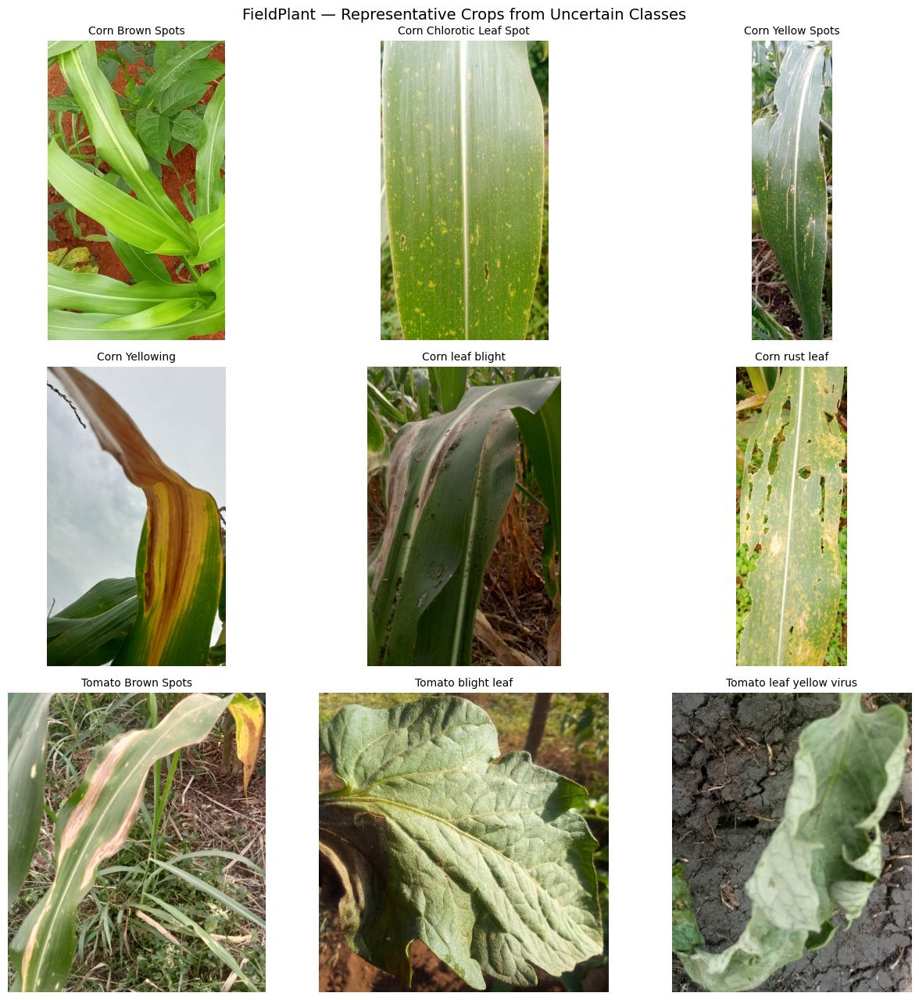

Representative crops found: 9 / 9


In [29]:
# Cell 29
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

uncertain_class_ids = set(
    fieldplant_review_df["class_id"].tolist()
)

representative_crops = {}

for label_file in fieldplant_label_files:

    if len(representative_crops) == len(uncertain_class_ids):
        break

    image_file = next(
        (
            fieldplant_images_path / f"{label_file.stem}{ext}"
            for ext in [".jpg", ".jpeg", ".png", ".bmp"]
            if (fieldplant_images_path / f"{label_file.stem}{ext}").exists()
        ),
        None
    )

    if image_file is None:
        continue

    with open(label_file, "r") as f:
        annotations = f.readlines()

    for annotation in annotations:
        values = annotation.strip().split()

        if len(values) != 5:
            continue

        class_id = int(values[0])

        if (
            class_id not in uncertain_class_ids
            or class_id in representative_crops
        ):
            continue

        xc, yc, bw, bh = map(float, values[1:])

        with Image.open(image_file) as img:
            img = img.convert("RGB")
            width, height = img.size

            left = max(0, int((xc - bw / 2) * width))
            top = max(0, int((yc - bh / 2) * height))
            right = min(width, int((xc + bw / 2) * width))
            bottom = min(height, int((yc + bh / 2) * height))

            if right <= left or bottom <= top:
                continue

            crop = img.crop((left, top, right, bottom))

            representative_crops[class_id] = np.array(crop)

fig, axes = plt.subplots(3, 3, figsize=(13, 13))

for ax, class_id in zip(axes.flat, sorted(uncertain_class_ids)):

    if class_id in representative_crops:
        ax.imshow(representative_crops[class_id])
    else:
        ax.text(
            0.5, 0.5, "No crop found",
            ha="center", va="center"
        )

    ax.set_title(
        fieldplant_classes[class_id],
        fontsize=10
    )
    ax.axis("off")

plt.suptitle(
    "FieldPlant — Representative Crops from Uncertain Classes",
    fontsize=14
)

plt.tight_layout()
plt.show()

print(
    f"Representative crops found: "
    f"{len(representative_crops)} / {len(uncertain_class_ids)}"
)

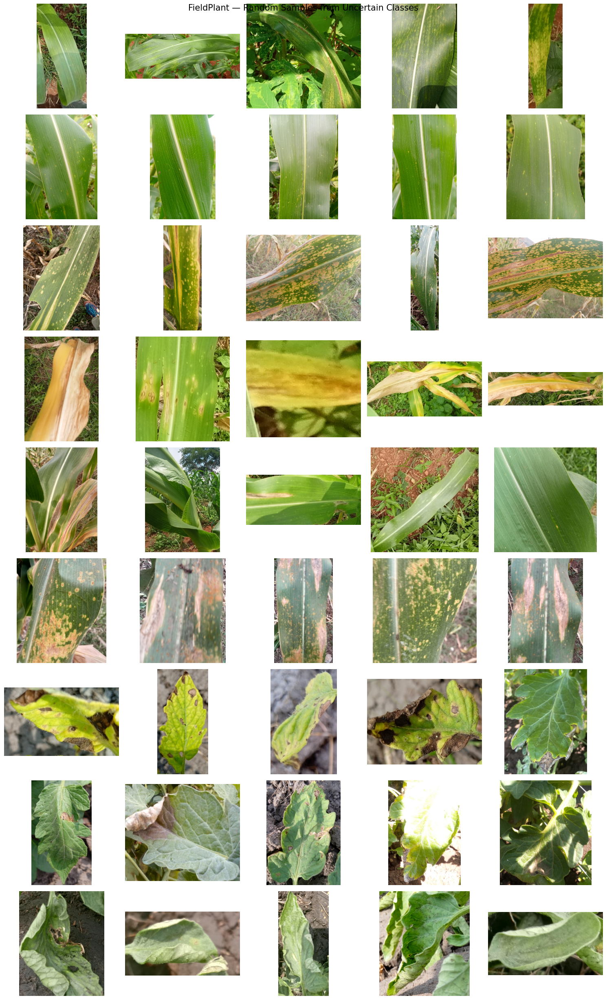

In [30]:
# Cell 30:
from collections import defaultdict
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

# Collect annotation references for uncertain classes
uncertain_samples = defaultdict(list)

for label_file in fieldplant_label_files:

    for image_ext in [".jpg", ".jpeg", ".png", ".bmp"]:
        image_file = fieldplant_images_path / (
            label_file.stem + image_ext
        )

        if image_file.exists():
            break
    else:
        continue

    with open(label_file, "r") as f:
        for line in f:

            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            if class_id in uncertain_class_ids:
                uncertain_samples[class_id].append(
                    (image_file, values[1:])
                )

# Display up to 5 random crops per class
fig, axes = plt.subplots(
    len(uncertain_class_ids),
    5,
    figsize=(15, 25)
)

for row_idx, class_id in enumerate(
    sorted(uncertain_class_ids)
):

    samples = random.sample(
        uncertain_samples[class_id],
        min(5, len(uncertain_samples[class_id]))
    )

    for col_idx, ax in enumerate(axes[row_idx]):

        ax.axis("off")

        if col_idx >= len(samples):
            continue

        image_file, coords = samples[col_idx]

        with Image.open(image_file) as img:

            img = img.convert("RGB")
            width, height = img.size

            xc, yc, bw, bh = map(float, coords)

            left = max(0, int((xc - bw / 2) * width))
            top = max(0, int((yc - bh / 2) * height))
            right = min(width, int((xc + bw / 2) * width))
            bottom = min(height, int((yc + bh / 2) * height))

            if right <= left or bottom <= top:
                continue

            crop = img.crop(
                (left, top, right, bottom)
            )

            ax.imshow(crop)

        if col_idx == 0:
            ax.set_ylabel(
                fieldplant_classes[class_id],
                rotation=0,
                ha="right",
                va="center",
                fontsize=10,
                labelpad=15
            )

plt.suptitle(
    "FieldPlant — Random Samples from Uncertain Classes",
    fontsize=15
)

plt.tight_layout()
plt.show()

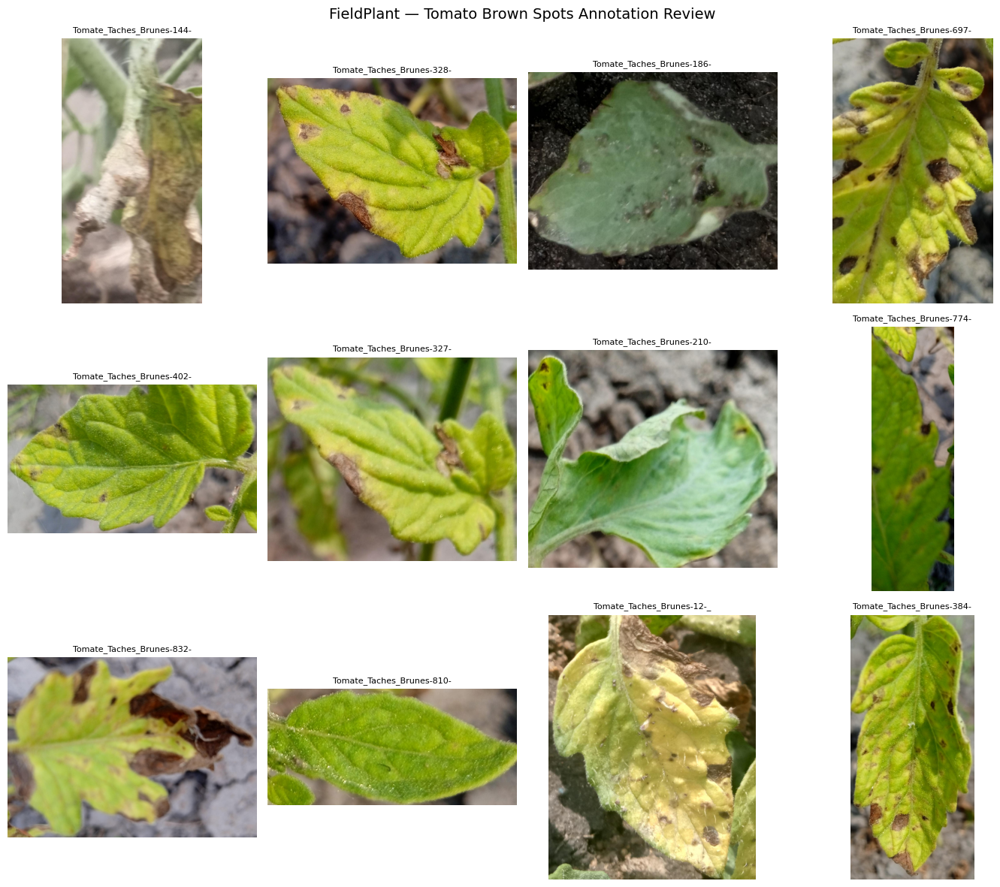

Total Tomato Brown Spots annotations: 1967
Samples inspected in this cell: 12


In [31]:
# Cell 31 - review tomato brown spots samples
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(123)

target_class_id = fieldplant_classes.index(
    "Tomato Brown Spots"
)

samples = uncertain_samples[target_class_id]

selected_samples = random.sample(
    samples,
    min(12, len(samples))
)

fig, axes = plt.subplots(3, 4, figsize=(14, 12))

for ax, (image_file, coords) in zip(
    axes.flat, selected_samples
):

    with Image.open(image_file) as img:

        img = img.convert("RGB")
        width, height = img.size

        xc, yc, bw, bh = map(float, coords)

        left = max(0, int((xc - bw / 2) * width))
        top = max(0, int((yc - bh / 2) * height))
        right = min(width, int((xc + bw / 2) * width))
        bottom = min(height, int((yc + bh / 2) * height))

        if right > left and bottom > top:
            crop = img.crop(
                (left, top, right, bottom)
            )

            ax.imshow(crop)

    ax.set_title(
        image_file.stem[:25],
        fontsize=8
    )

    ax.axis("off")

plt.suptitle(
    "FieldPlant — Tomato Brown Spots Annotation Review",
    fontsize=14
)

plt.tight_layout()
plt.show()

print(
    f"Total Tomato Brown Spots annotations: "
    f"{len(samples)}"
)

print(
    f"Samples inspected in this cell: "
    f"{len(selected_samples)}"
)

In [32]:
# Cell 32
fieldplant_summary = (
    fieldplant_mapping_df
    .groupby("mapping_category", dropna=False)
    .agg(
        number_of_classes=("class_name", "count"),
        annotated_objects=("annotated_objects", "sum")
    )
    .reset_index()
)

fieldplant_summary["percentage_of_objects"] = (
    fieldplant_summary["annotated_objects"]
    / fieldplant_mapping_df["annotated_objects"].sum()
    * 100
).round(2)

print("FIELDPLANT MAPPING SUMMARY")
print("=" * 60)

display(fieldplant_summary)

print("\nVALIDATION")
print("-" * 60)

print(
    "Total classes:",
    fieldplant_summary["number_of_classes"].sum()
)

print(
    "Total annotated objects:",
    fieldplant_summary["annotated_objects"].sum()
)

print(
    "Classes without mapping category:",
    fieldplant_mapping_df["mapping_category"].isna().sum()
)

print(
    "Confirmed mapped classes:",
    fieldplant_mapping_df["mapping_category"]
    .isin(["Direct match", "Defensible match"])
    .sum()
)

print(
    "Confirmed mapped objects:",
    fieldplant_mapping_df.loc[
        fieldplant_mapping_df["mapping_category"]
        .isin(["Direct match", "Defensible match"]),
        "annotated_objects"
    ].sum()
)

FIELDPLANT MAPPING SUMMARY


,mapping_category,number_of_classes,annotated_objects,percentage_of_objects
0,Direct match,4,504,5.87
1,Uncertain,9,4944,57.62
2,Unsupported,14,3132,36.50



VALIDATION
------------------------------------------------------------
Total classes: 27
Total annotated objects: 8580
Classes without mapping category: 0
Confirmed mapped classes: 4
Confirmed mapped objects: 504


In [33]:
# Cell 33
print("FIELDPLANT FINAL MAPPING VALIDATION")
print("=" * 60)

valid_categories = {
    "Direct match",
    "Defensible match",
    "Uncertain",
    "Unsupported"
}

# Check mapping categories
invalid_categories = fieldplant_mapping_df[
    ~fieldplant_mapping_df["mapping_category"].isin(valid_categories)
]

# Identify approved mappings
approved_mask = fieldplant_mapping_df[
    "mapping_category"
].isin(["Direct match", "Defensible match"])

approved_mappings = fieldplant_mapping_df[approved_mask]

# Verify that approved targets exist in PlantVillage
invalid_targets = approved_mappings[
    ~approved_mappings["plantvillage_class"].isin(
        plantvillage_classes
    )
]

# Verify that excluded classes have no assigned target
excluded_mappings = fieldplant_mapping_df[
    ~approved_mask
]

unexpected_targets = excluded_mappings[
    excluded_mappings["plantvillage_class"].notna()
]

print("Invalid mapping categories:", len(invalid_categories))
print("Invalid approved targets:", len(invalid_targets))
print(
    "Unexpected targets in excluded classes:",
    len(unexpected_targets)
)

print("\nFINAL STATUS")
print("-" * 60)

if (
    len(invalid_categories) == 0
    and len(invalid_targets) == 0
    and len(unexpected_targets) == 0
):
    print("PASS: All mapping validation checks passed.")
else:
    print("REVIEW REQUIRED: Mapping inconsistencies detected.")

print("\nAPPROVED FIELDPLANT CLASSES")

display(
    approved_mappings[
        [
            "class_name",
            "plantvillage_class",
            "mapping_category",
            "annotated_objects"
        ]
    ]
)

FIELDPLANT FINAL MAPPING VALIDATION
Invalid mapping categories: 0
Invalid approved targets: 0
Unexpected targets in excluded classes: 0

FINAL STATUS
------------------------------------------------------------
PASS: All mapping validation checks passed.

APPROVED FIELDPLANT CLASSES


,class_name,plantvillage_class,mapping_category,annotated_objects
8,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Direct match,54
9,Corn Healthy,Corn_(maize)___healthy,Direct match,152
24,Tomato healthy,Tomato___healthy,Direct match,279
25,Tomato leaf mosaic virus,Tomato___Tomato_mosaic_virus,Direct match,19


In [34]:
# Cell 34 — Save FieldPlant mapping results

from pathlib import Path

mapping_output_dir = Path("mapping_results")
mapping_output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save all FieldPlant mapping decisions
fieldplant_mapping_df.to_csv(
    mapping_output_dir / "fieldplant_full_mapping.csv",
    index=False
)

# 2. Save approved mappings only
approved_mappings.to_csv(
    mapping_output_dir / "fieldplant_approved_mapping.csv",
    index=False
)

# 3. Save unresolved candidate mappings
fieldplant_candidates_df.to_csv(
    mapping_output_dir / "fieldplant_candidate_mapping.csv",
    index=False
)

print("FIELDPLANT MAPPING FILES SAVED")
print("=" * 60)

for file_path in sorted(mapping_output_dir.glob("*.csv")):
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")

print("\nOutput directory:")
print(mapping_output_dir.resolve())

FIELDPLANT MAPPING FILES SAVED
fieldplant_approved_mapping.csv: 621 bytes
fieldplant_candidate_mapping.csv: 334 bytes
fieldplant_full_mapping.csv: 3,537 bytes

Output directory:
/content/mapping_results


In [35]:
# Cell 35 — Download FieldPlant mapping files

import shutil
from google.colab import files

# Create ZIP archive
archive_path = shutil.make_archive(
    "/content/fieldplant_mapping_results",
    "zip",
    root_dir="/content",
    base_dir="mapping_results"
)

print("ZIP archive created:", archive_path)

# Trigger download
files.download(archive_path)

ZIP archive created: /content/fieldplant_mapping_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
# Cell 36 — Connect Google Drive

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [38]:
# Cell 37 — Save FieldPlant mapping results to Google Drive

from pathlib import Path
import shutil

# Source: Colab runtime
source_dir = Path("/content/mapping_results")

# Destination: Google Drive
drive_output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/mapping_results"
)

drive_output_dir.mkdir(parents=True, exist_ok=True)

# Files to preserve
mapping_files = [
    "fieldplant_full_mapping.csv",
    "fieldplant_approved_mapping.csv",
    "fieldplant_candidate_mapping.csv"
]

print("SAVING FIELDPLANT MAPPING RESULTS")
print("=" * 60)

for filename in mapping_files:

    source_file = source_dir / filename
    destination_file = drive_output_dir / filename

    if not source_file.exists():
        print(f"MISSING: {filename}")
        continue

    shutil.copy2(source_file, destination_file)

    print(f"SAVED: {filename}")

print("\nGOOGLE DRIVE DESTINATION")
print("-" * 60)
print(drive_output_dir)

print("\nVERIFICATION")
print("-" * 60)

for filename in mapping_files:

    saved_file = drive_output_dir / filename

    if saved_file.exists():
        print(
            f"PASS: {filename} "
            f"({saved_file.stat().st_size:,} bytes)"
        )
    else:
        print(f"FAILED: {filename}")

SAVING FIELDPLANT MAPPING RESULTS
SAVED: fieldplant_full_mapping.csv
SAVED: fieldplant_approved_mapping.csv
SAVED: fieldplant_candidate_mapping.csv

GOOGLE DRIVE DESTINATION
------------------------------------------------------------
/content/drive/MyDrive/AgroVision_FYP2/mapping_results

VERIFICATION
------------------------------------------------------------
PASS: fieldplant_full_mapping.csv (3,537 bytes)
PASS: fieldplant_approved_mapping.csv (621 bytes)
PASS: fieldplant_candidate_mapping.csv (334 bytes)


In [39]:
# Cell 38 — Save PlantDoc mapping results to Google Drive

from pathlib import Path
import pandas as pd

# Destination folder (already created in Cell 37)
drive_output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/mapping_results"
)

# Verify that the final PlantDoc mapping exists
assert "plantdoc_final_mapping_df" in globals(), (
    "PlantDoc final mapping not found. "
    "Please rerun the relevant earlier cells."
)

# Save the completed PlantDoc mapping
plantdoc_file = drive_output_dir / "plantdoc_final_mapping.csv"

plantdoc_final_mapping_df.to_csv(
    plantdoc_file,
    index=False
)

print("PLANTDOC MAPPING EXPORT")
print("=" * 60)

print("File saved:", plantdoc_file.name)
print("File size:", f"{plantdoc_file.stat().st_size:,} bytes")

print("\nVERIFICATION")
print("-" * 60)

# Reload the saved file to verify its contents
saved_plantdoc_df = pd.read_csv(plantdoc_file)

print("Original rows:", len(plantdoc_final_mapping_df))
print("Saved rows:", len(saved_plantdoc_df))

if (
    len(saved_plantdoc_df) == len(plantdoc_final_mapping_df)
    and plantdoc_file.stat().st_size > 0
):
    print("PASS: PlantDoc mapping successfully saved.")
else:
    print("REVIEW REQUIRED: Saved mapping does not match.")

PLANTDOC MAPPING EXPORT
File saved: plantdoc_final_mapping.csv
File size: 4,925 bytes

VERIFICATION
------------------------------------------------------------
Original rows: 28
Saved rows: 28
PASS: PlantDoc mapping successfully saved.


In [40]:
# Cell 39 — Compare PlantDoc and FieldPlant class coverage

# Retrieve approved PlantVillage targets
plantdoc_covered_classes = set(
    plantdoc_final_mapping_df["plantvillage_class"].dropna()
)

fieldplant_covered_classes = set(
    fieldplant_mapping_df.loc[
        fieldplant_mapping_df["mapping_category"].isin(
            ["Direct match", "Defensible match"]
        ),
        "plantvillage_class"
    ].dropna()
)

# Compare coverage
shared_classes = plantdoc_covered_classes & fieldplant_covered_classes

plantdoc_only_classes = (
    plantdoc_covered_classes - fieldplant_covered_classes
)

fieldplant_only_classes = (
    fieldplant_covered_classes - plantdoc_covered_classes
)

combined_covered_classes = (
    plantdoc_covered_classes | fieldplant_covered_classes
)

uncovered_classes = (
    set(plantvillage_classes) - combined_covered_classes
)

print("COMBINED EXTERNAL DATASET CLASS COVERAGE")
print("=" * 60)

print("Total PlantVillage classes:", len(plantvillage_classes))
print("PlantDoc covered classes:", len(plantdoc_covered_classes))
print("FieldPlant covered classes:", len(fieldplant_covered_classes))
print("Shared classes:", len(shared_classes))
print("PlantDoc-only classes:", len(plantdoc_only_classes))
print("FieldPlant-only classes:", len(fieldplant_only_classes))
print("Combined covered classes:", len(combined_covered_classes))
print("Uncovered PlantVillage classes:", len(uncovered_classes))

print("\nFIELDPLANT-ONLY CLASSES")
print("-" * 60)

for class_name in sorted(fieldplant_only_classes):
    print("-", class_name)

print("\nUNCOVERED PLANTVILLAGE CLASSES")
print("-" * 60)

for class_name in sorted(uncovered_classes):
    print("-", class_name)

COMBINED EXTERNAL DATASET CLASS COVERAGE
Total PlantVillage classes: 38
PlantDoc covered classes: 28
FieldPlant covered classes: 4
Shared classes: 3
PlantDoc-only classes: 25
FieldPlant-only classes: 1
Combined covered classes: 29
Uncovered PlantVillage classes: 9

FIELDPLANT-ONLY CLASSES
------------------------------------------------------------
- Corn_(maize)___healthy

UNCOVERED PLANTVILLAGE CLASSES
------------------------------------------------------------
- Apple___Black_rot
- Cherry_(including_sour)___Powdery_mildew
- Grape___Esca_(Black_Measles)
- Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
- Orange___Haunglongbing_(Citrus_greening)
- Peach___Bacterial_spot
- Potato___healthy
- Strawberry___Leaf_scorch
- Tomato___Target_Spot


In [41]:
# Cell 40 — Build combined external dataset coverage table

import pandas as pd

coverage_records = []

for class_name in sorted(plantvillage_classes):

    in_plantdoc = class_name in plantdoc_covered_classes
    in_fieldplant = class_name in fieldplant_covered_classes

    if in_plantdoc and in_fieldplant:
        coverage_status = "Both datasets"
    elif in_plantdoc:
        coverage_status = "PlantDoc only"
    elif in_fieldplant:
        coverage_status = "FieldPlant only"
    else:
        coverage_status = "Not covered"

    coverage_records.append({
        "plantvillage_class": class_name,
        "plantdoc_covered": in_plantdoc,
        "fieldplant_covered": in_fieldplant,
        "coverage_status": coverage_status
    })

combined_coverage_df = pd.DataFrame(coverage_records)

print("COMBINED CLASS COVERAGE TABLE")
print("=" * 60)

display(combined_coverage_df)

print("\nCOVERAGE STATUS SUMMARY")
print("-" * 60)

print(
    combined_coverage_df["coverage_status"]
    .value_counts()
    .to_string()
)

print("\nVALIDATION")
print("-" * 60)

assert len(combined_coverage_df) == 38
assert combined_coverage_df["plantvillage_class"].is_unique
assert combined_coverage_df["coverage_status"].value_counts().to_dict() == {
    "PlantDoc only": 25,
    "Not covered": 9,
    "Both datasets": 3,
    "FieldPlant only": 1
}

print("PASS: All 38 PlantVillage classes accounted for.")

COMBINED CLASS COVERAGE TABLE


,plantvillage_class,plantdoc_covered,fieldplant_covered,coverage_status
0,Apple___Apple_scab,True,False,PlantDoc only
1,Apple___Black_rot,False,False,Not covered
2,Apple___Cedar_apple_rust,True,False,PlantDoc only
3,Apple___healthy,True,False,PlantDoc only
4,Blueberry___healthy,True,False,PlantDoc only
5,Cherry_(including_sour)___Powdery_mildew,False,False,Not covered
6,Cherry_(including_sour)___healthy,True,False,PlantDoc only
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,True,True,Both datasets
8,Corn_(maize)___Common_rust_,True,False,PlantDoc only
9,Corn_(maize)___Northern_Leaf_Blight,True,False,PlantDoc only



COVERAGE STATUS SUMMARY
------------------------------------------------------------
coverage_status
PlantDoc only      25
Not covered         9
Both datasets       3
FieldPlant only     1

VALIDATION
------------------------------------------------------------
PASS: All 38 PlantVillage classes accounted for.


In [42]:
# Cell 41 — Save combined external dataset coverage

from pathlib import Path
import pandas as pd

output_file = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "mapping_results/combined_external_coverage.csv"
)

# Save coverage table
combined_coverage_df.to_csv(output_file, index=False)

# Verify saved contents
saved_df = pd.read_csv(output_file)

print("COMBINED COVERAGE EXPORT")
print("=" * 60)

print("File:", output_file.name)
print("Rows:", len(saved_df))
print("File size:", f"{output_file.stat().st_size:,} bytes")

print("\nVALIDATION")
print("-" * 60)

pd.testing.assert_frame_equal(
    combined_coverage_df.reset_index(drop=True),
    saved_df.reset_index(drop=True)
)

assert len(saved_df) == len(plantvillage_classes)

print("PASS: Combined coverage table saved and verified.")
print("\nLocation:", output_file.parent)

COMBINED COVERAGE EXPORT
File: combined_external_coverage.csv
Rows: 38
File size: 1,999 bytes

VALIDATION
------------------------------------------------------------
PASS: Combined coverage table saved and verified.

Location: /content/drive/MyDrive/AgroVision_FYP2/mapping_results


In [43]:
# Cell 42 — Inspect PlantDoc mapping columns and available test variables

print("PLANTDOC MAPPING COLUMNS")
print("=" * 60)
print(plantdoc_final_mapping_df.columns.tolist())

print("\nPOTENTIAL PLANTDOC TEST VARIABLES")
print("=" * 60)

for name, value in list(globals().items()):
    if "plantdoc" in name.lower() and (
        "test" in name.lower() or "split" in name.lower()
    ):
        print(f"{name}: {type(value).__name__}")

PLANTDOC MAPPING COLUMNS
['class_name', 'plantvillage_class', 'mapping_category', 'justification', 'train_images', 'test_images', 'total_images', 'available_in_test']

POTENTIAL PLANTDOC TEST VARIABLES


In [44]:
# Cell 43 — Verify PlantDoc test-set coverage

print("PLANTDOC EXTERNAL TEST-SET COVERAGE")
print("=" * 60)

# Select classes with at least one test image
plantdoc_test_df = plantdoc_final_mapping_df[
    plantdoc_final_mapping_df["test_images"] > 0
].copy()

# Calculate test-set statistics
total_mapped_classes = len(plantdoc_final_mapping_df)
test_classes = len(plantdoc_test_df)
test_images = int(plantdoc_test_df["test_images"].sum())

test_plantvillage_classes = set(
    plantdoc_test_df["plantvillage_class"].dropna()
)

print("Total mapped PlantDoc classes:", total_mapped_classes)
print("Classes available in test split:", test_classes)
print("Total test images:", test_images)
print("Unique PlantVillage targets:", len(test_plantvillage_classes))

print("\nCLASSES WITHOUT TEST IMAGES")
print("-" * 60)

missing_test_classes = plantdoc_final_mapping_df[
    plantdoc_final_mapping_df["test_images"] == 0
]

display(
    missing_test_classes[
        ["class_name", "plantvillage_class", "test_images"]
    ]
)

print("\nVALIDATION")
print("-" * 60)

assert total_mapped_classes == 28
assert test_classes == 27
assert test_images == 236
assert len(test_plantvillage_classes) == 27

assert (
    plantdoc_test_df["plantvillage_class"].isin(
        plantvillage_classes
    )
).all()

print("PASS: PlantDoc test-set coverage verified.")

PLANTDOC EXTERNAL TEST-SET COVERAGE
Total mapped PlantDoc classes: 28
Classes available in test split: 27
Total test images: 236
Unique PlantVillage targets: 27

CLASSES WITHOUT TEST IMAGES
------------------------------------------------------------


,class_name,plantvillage_class,test_images
26,Tomato two spotted spider mites leaf,Tomato___Spider_mites Two-spotted_spider_mite,0



VALIDATION
------------------------------------------------------------
PASS: PlantDoc test-set coverage verified.


PLANTDOC TEST-SET CLASS DISTRIBUTION


,class_name,plantvillage_class,test_images
0,Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight,12
1,grape leaf,Grape___healthy,12
2,Blueberry leaf,Blueberry___healthy,11
3,Tomato Septoria leaf spot,Tomato___Septoria_leaf_spot,11
4,Apple rust leaf,Apple___Cedar_apple_rust,10
5,Corn rust leaf,Corn_(maize)___Common_rust_,10
6,Apple Scab Leaf,Apple___Apple_scab,10
7,Tomato leaf late blight,Tomato___Late_blight,10
8,Tomato leaf mosaic virus,Tomato___Tomato_mosaic_virus,10
9,Cherry leaf,Cherry_(including_sour)___healthy,10



DISTRIBUTION STATISTICS
------------------------------------------------------------
Total test images: 236
Number of classes: 27
Minimum images per class: 4
Maximum images per class: 12
Mean images per class: 8.74
Median images per class: 9.0


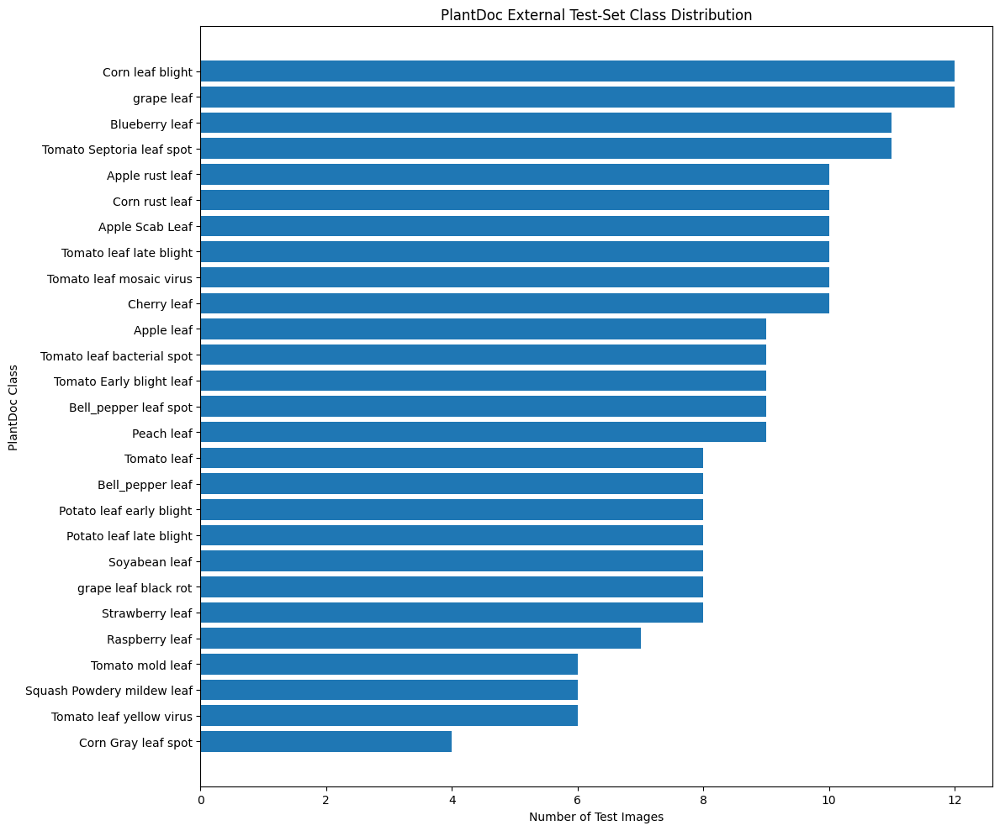

In [45]:
# Cell 44 — Analyse PlantDoc test-set class distribution

import matplotlib.pyplot as plt

# Sort classes by test image count
plantdoc_test_distribution = (
    plantdoc_test_df[
        ["class_name", "plantvillage_class", "test_images"]
    ]
    .sort_values("test_images", ascending=False)
    .reset_index(drop=True)
)

print("PLANTDOC TEST-SET CLASS DISTRIBUTION")
print("=" * 60)

display(plantdoc_test_distribution)

print("\nDISTRIBUTION STATISTICS")
print("-" * 60)

print("Total test images:", plantdoc_test_distribution["test_images"].sum())
print("Number of classes:", len(plantdoc_test_distribution))
print("Minimum images per class:", plantdoc_test_distribution["test_images"].min())
print("Maximum images per class:", plantdoc_test_distribution["test_images"].max())
print("Mean images per class:", round(plantdoc_test_distribution["test_images"].mean(), 2))
print("Median images per class:", plantdoc_test_distribution["test_images"].median())

# Visualise class distribution
plt.figure(figsize=(12, 10))

plt.barh(
    plantdoc_test_distribution["class_name"],
    plantdoc_test_distribution["test_images"]
)

plt.xlabel("Number of Test Images")
plt.ylabel("PlantDoc Class")
plt.title("PlantDoc External Test-Set Class Distribution")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [46]:
# Cell 45 — Validate PlantDoc external test-set distribution

print("PLANTDOC TEST-SET VALIDATION")
print("=" * 60)

# Check for missing values
print("\nMISSING VALUES")
print("-" * 60)

print(
    plantdoc_test_distribution[
        ["class_name", "plantvillage_class", "test_images"]
    ].isna().sum()
)

# Check for duplicate target classes
duplicate_targets = (
    plantdoc_test_distribution["plantvillage_class"]
    .duplicated()
    .sum()
)

print("\nCLASS MAPPING VALIDATION")
print("-" * 60)

print("Duplicate PlantVillage targets:", duplicate_targets)

# Verify test image counts
assert (plantdoc_test_distribution["test_images"] > 0).all()
assert duplicate_targets == 0
assert plantdoc_test_distribution["test_images"].sum() == 236
assert len(plantdoc_test_distribution) == 27

# Verify mappings belong to the 38 PlantVillage classes
assert set(
    plantdoc_test_distribution["plantvillage_class"]
).issubset(set(plantvillage_classes))

# Verify test availability flags agree with image counts
assert (
    plantdoc_final_mapping_df["available_in_test"].astype(bool)
    == (plantdoc_final_mapping_df["test_images"] > 0)
).all()

print("\nPASS: PlantDoc test-set distribution is internally consistent.")

PLANTDOC TEST-SET VALIDATION

MISSING VALUES
------------------------------------------------------------
class_name            0
plantvillage_class    0
test_images           0
dtype: int64

CLASS MAPPING VALIDATION
------------------------------------------------------------
Duplicate PlantVillage targets: 0

PASS: PlantDoc test-set distribution is internally consistent.


In [47]:
# Cell 46 — Locate PlantDoc test image directories

from pathlib import Path

print("PLANTDOC DATASET PATH VARIABLES")
print("=" * 60)

for name, value in list(globals().items()):
    if (
        "plantdoc" in name.lower()
        and "path" in name.lower()
        and isinstance(value, (str, Path))
    ):
        print(f"{name}: {value}")

print("\nPLANTDOC TEST DIRECTORY CANDIDATES")
print("=" * 60)

for name, value in list(globals().items()):
    if (
        "plantdoc" in name.lower()
        and isinstance(value, (str, Path))
    ):
        candidate = Path(value)

        if candidate.is_dir():
            print(f"\n{name}: {candidate}")

            for item in sorted(candidate.iterdir())[:15]:
                print(
                    f"  {'[DIR]' if item.is_dir() else '[FILE]'} "
                    f"{item.name}"
                )

PLANTDOC DATASET PATH VARIABLES

PLANTDOC TEST DIRECTORY CANDIDATES


In [48]:
# Cell 47 — Locate PlantDoc dataset directories

from pathlib import Path

print("SEARCHING FOR PLANTDOC DATASET")
print("=" * 60)

search_locations = [
    Path("/content"),
    Path("/root/.cache/kagglehub/datasets")
]

for location in search_locations:

    print(f"\nSearching: {location}")

    if not location.exists():
        print("Directory not found.")
        continue

    matches = [
        path for path in location.rglob("*")
        if path.is_dir() and "plantdoc" in path.name.lower()
    ]

    if matches:
        for path in matches[:20]:
            print("FOUND:", path)
    else:
        print("No PlantDoc-named directories found.")

SEARCHING FOR PLANTDOC DATASET

Searching: /content
FOUND: /content/PlantDoc-Dataset
FOUND: /content/drive/.Encrypted/MyDrive/AgroVision_FYP2/plantdoc_preparation
FOUND: /content/drive/MyDrive/AgroVision_FYP2/plantdoc_preparation

Searching: /root/.cache/kagglehub/datasets
Directory not found.


In [49]:
# Cell 48 — Inspect PlantDoc directory structure

from pathlib import Path

plantdoc_root = Path("/content/PlantDoc-Dataset")

print("PLANTDOC DATASET STRUCTURE")
print("=" * 60)

assert plantdoc_root.is_dir(), "PlantDoc directory not found."

print("Dataset root:", plantdoc_root)

print("\nTOP-LEVEL CONTENTS")
print("-" * 60)

for item in sorted(plantdoc_root.iterdir()):
    print(
        f"{'[DIR]' if item.is_dir() else '[FILE]'} "
        f"{item.name}"
    )

print("\nDIRECTORY STRUCTURE (FIRST 3 LEVELS)")
print("-" * 60)

def show_directory_structure(directory, level=0, max_depth=3):

    if level >= max_depth:
        return

    items = sorted(directory.iterdir())

    for item in items[:15]:
        indent = "    " * level

        print(
            f"{indent}{'[DIR]' if item.is_dir() else '[FILE]'} "
            f"{item.name}"
        )

        if item.is_dir():
            show_directory_structure(
                item,
                level + 1,
                max_depth
            )

        if len(items) > 15 and item == items[14]:
            print(f"{indent}... and {len(items) - 15} more items")

show_directory_structure(plantdoc_root)

PLANTDOC DATASET STRUCTURE
Dataset root: /content/PlantDoc-Dataset

TOP-LEVEL CONTENTS
------------------------------------------------------------
[DIR] .git
[FILE] LICENSE.txt
[FILE] PlantDoc_Examples.png
[FILE] README.md
[DIR] test
[DIR] train

DIRECTORY STRUCTURE (FIRST 3 LEVELS)
------------------------------------------------------------
[DIR] .git
    [FILE] HEAD
    [DIR] branches
    [FILE] config
    [FILE] description
    [DIR] hooks
        [FILE] applypatch-msg.sample
        [FILE] commit-msg.sample
        [FILE] fsmonitor-watchman.sample
        [FILE] post-update.sample
        [FILE] pre-applypatch.sample
        [FILE] pre-commit.sample
        [FILE] pre-merge-commit.sample
        [FILE] pre-push.sample
        [FILE] pre-rebase.sample
        [FILE] pre-receive.sample
        [FILE] prepare-commit-msg.sample
        [FILE] push-to-checkout.sample
        [FILE] sendemail-validate.sample
        [FILE] update.sample
    [FILE] index
    [DIR] info
        [FILE] ex

In [50]:
# Cell 49 — Build PlantDoc test image inventory

from pathlib import Path
import pandas as pd

plantdoc_test_dir = plantdoc_root / "test"

# Create mapping dictionary from approved mapping table
plantdoc_class_mapping = dict(
    zip(
        plantdoc_test_df["class_name"],
        plantdoc_test_df["plantvillage_class"]
    )
)

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_records = []

for class_dir in sorted(plantdoc_test_dir.iterdir()):

    if not class_dir.is_dir():
        continue

    class_name = class_dir.name

    # Only include approved mapped classes
    if class_name not in plantdoc_class_mapping:
        continue

    for image_path in sorted(class_dir.iterdir()):

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        image_records.append({
            "filepath": str(image_path),
            "filename": image_path.name,
            "plantdoc_class": class_name,
            "plantvillage_class": plantdoc_class_mapping[class_name]
        })

plantdoc_test_inventory_df = pd.DataFrame(
    image_records,
    columns=[
        "filepath",
        "filename",
        "plantdoc_class",
        "plantvillage_class"
    ]
)

print("PLANTDOC TEST IMAGE INVENTORY")
print("=" * 60)

display(plantdoc_test_inventory_df.head(10))

print("\nINVENTORY SUMMARY")
print("-" * 60)

print("Total images:", len(plantdoc_test_inventory_df))
print(
    "PlantDoc classes:",
    plantdoc_test_inventory_df["plantdoc_class"].nunique()
)
print(
    "PlantVillage target classes:",
    plantdoc_test_inventory_df["plantvillage_class"].nunique()
)

print("\nVALIDATION")
print("-" * 60)

assert len(plantdoc_test_inventory_df) == 236
assert plantdoc_test_inventory_df["plantdoc_class"].nunique() == 27
assert plantdoc_test_inventory_df["plantvillage_class"].nunique() == 27
assert plantdoc_test_inventory_df["filepath"].is_unique

# Verify image counts for every class
actual_counts = (
    plantdoc_test_inventory_df["plantdoc_class"]
    .value_counts()
    .sort_index()
)

expected_counts = (
    plantdoc_test_df
    .set_index("class_name")["test_images"]
    .sort_index()
)

pd.testing.assert_series_equal(
    actual_counts,
    expected_counts,
    check_names=False
)

print("PASS: All PlantDoc test images accounted for.")

PLANTDOC TEST IMAGE INVENTORY


,filepath,filename,plantdoc_class,plantvillage_class
0,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,052609%20Hartman%20Crabapple%20scab%20single%2...,Apple Scab Leaf,Apple___Apple_scab
1,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,1b321015-6e33-4f18-aade-888f4383fe92.jpeg.jpg,Apple Scab Leaf,Apple___Apple_scab
2,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,28-500x375.jpg,Apple Scab Leaf,Apple___Apple_scab
3,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,816.jpg,Apple Scab Leaf,Apple___Apple_scab
4,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,apple%20scab%20leaf.jpg,Apple Scab Leaf,Apple___Apple_scab
5,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,apple%20scabnew.jpg,Apple Scab Leaf,Apple___Apple_scab
6,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,apple-scab-5366820.jpg,Apple Scab Leaf,Apple___Apple_scab
7,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,apples_apple-scab_01_zoom.jpg,Apple Scab Leaf,Apple___Apple_scab
8,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,apples_apple-scab_02_thm.jpg,Apple Scab Leaf,Apple___Apple_scab
9,/content/PlantDoc-Dataset/test/Apple Scab Leaf...,apples_apple-scab_10_zoom.jpg,Apple Scab Leaf,Apple___Apple_scab



INVENTORY SUMMARY
------------------------------------------------------------
Total images: 236
PlantDoc classes: 27
PlantVillage target classes: 27

VALIDATION
------------------------------------------------------------
PASS: All PlantDoc test images accounted for.


In [51]:
# Cell 50 — Verify PlantDoc test image integrity

from PIL import Image
import pandas as pd

image_checks = []

for _, row in plantdoc_test_inventory_df.iterrows():

    image_path = row["filepath"]

    try:
        # Check image file integrity
        with Image.open(image_path) as img:
            img.verify()

        # Reopen to inspect image properties
        with Image.open(image_path) as img:
            width, height = img.size
            colour_mode = img.mode
            img.load()

        status = "Valid"
        error = None

    except Exception as e:
        width = None
        height = None
        colour_mode = None
        status = "Invalid"
        error = str(e)

    image_checks.append({
        "filepath": image_path,
        "plantdoc_class": row["plantdoc_class"],
        "width": width,
        "height": height,
        "colour_mode": colour_mode,
        "status": status,
        "error": error
    })

plantdoc_image_integrity_df = pd.DataFrame(image_checks)

print("PLANTDOC IMAGE INTEGRITY CHECK")
print("=" * 60)

print("Total images:", len(plantdoc_image_integrity_df))

print("\nIMAGE STATUS")
print("-" * 60)
print(plantdoc_image_integrity_df["status"].value_counts())

print("\nCOLOUR MODES")
print("-" * 60)
print(plantdoc_image_integrity_df["colour_mode"].value_counts())

print("\nIMAGE DIMENSIONS")
print("-" * 60)

display(
    plantdoc_image_integrity_df[
        ["width", "height"]
    ].describe()
)

print("\nINVALID IMAGES")
print("-" * 60)

invalid_images = plantdoc_image_integrity_df[
    plantdoc_image_integrity_df["status"] == "Invalid"
]

if invalid_images.empty:
    print("No invalid images detected.")
else:
    display(invalid_images[["filepath", "error"]])

print("\nVALIDATION")
print("-" * 60)

assert len(plantdoc_image_integrity_df) == 236

if invalid_images.empty:
    print("PASS: All PlantDoc test images are readable.")
else:
    print(
        f"REVIEW REQUIRED: {len(invalid_images)} "
        "images could not be read."
    )

PLANTDOC IMAGE INTEGRITY CHECK
Total images: 236

IMAGE STATUS
------------------------------------------------------------
status
Valid    236
Name: count, dtype: int64

COLOUR MODES
------------------------------------------------------------
colour_mode
RGB    236
Name: count, dtype: int64

IMAGE DIMENSIONS
------------------------------------------------------------


,width,height
count,236.000000,236.000000
mean,1054.605932,949.661017
std,906.690377,892.512049
min,115.000000,69.000000
25%,463.750000,392.750000
50%,800.000000,678.500000
75%,1300.000000,1200.000000
max,6000.000000,5312.000000



INVALID IMAGES
------------------------------------------------------------
No invalid images detected.

VALIDATION
------------------------------------------------------------
PASS: All PlantDoc test images are readable.


In [52]:
# Cell 51 — Locate saved AgroVision model files

from pathlib import Path

print("SEARCHING FOR SAVED AGROVISION MODELS")
print("=" * 60)

search_dirs = [
    Path("/content"),
    Path("/content/drive/MyDrive/AgroVision_FYP2")
]

model_extensions = {".keras", ".h5", ".hdf5"}

found_models = []

for directory in search_dirs:

    if not directory.exists():
        continue

    for path in directory.rglob("*"):

        if path.is_file() and path.suffix.lower() in model_extensions:
            found_models.append(path)

# Remove duplicate paths
found_models = sorted(set(found_models))

print("\nMODEL FILES FOUND")
print("-" * 60)

if found_models:
    for path in found_models:
        print(path)
else:
    print("No saved Keras model files found.")

print("\nTOTAL MODEL FILES:", len(found_models))

SEARCHING FOR SAVED AGROVISION MODELS

MODEL FILES FOUND
------------------------------------------------------------
No saved Keras model files found.

TOTAL MODEL FILES: 0


In [53]:
# Cell 52 — Inspect existing model-related variables

print("MODEL-RELATED VARIABLES")
print("=" * 60)

keywords = [
    "model",
    "resnet",
    "checkpoint",
    "weights"
]

matches = []

for name, value in list(globals().items()):

    if name.startswith("_"):
        continue

    if any(keyword in name.lower() for keyword in keywords):
        matches.append((name, type(value).__name__))

if matches:
    for name, type_name in matches:
        print(f"{name}: {type_name}")
else:
    print("No model-related variables found.")

MODEL-RELATED VARIABLES
model_extensions: set
found_models: list


In [54]:
# Cell 53 — Check original FYP1 model directory

from pathlib import Path

fyp1_model_dir = Path("/content/agrovision_fyp1/saved_models")

print("FYP1 MODEL CHECK")
print("=" * 60)

print("Original model directory:", fyp1_model_dir)
print("Directory exists:", fyp1_model_dir.exists())

print("\nRESNET50 CHECKPOINTS")
print("-" * 60)

for filename in ["ResNet50_best.keras", "ResNet50_final.keras"]:
    model_file = fyp1_model_dir / filename

    print(f"\n{filename}")
    print("Exists:", model_file.is_file())

    if model_file.is_file():
        print("Size:", f"{model_file.stat().st_size / (1024**2):.2f} MB")

FYP1 MODEL CHECK
Original model directory: /content/agrovision_fyp1/saved_models
Directory exists: False

RESNET50 CHECKPOINTS
------------------------------------------------------------

ResNet50_best.keras
Exists: False

ResNet50_final.keras
Exists: False


In [55]:
# Cell 54 — Save PlantDoc preparation results

from pathlib import Path
import pandas as pd

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/plantdoc_preparation"
)

output_dir.mkdir(parents=True, exist_ok=True)

files_to_save = {
    "plantdoc_test_inventory.csv": plantdoc_test_inventory_df,
    "plantdoc_image_integrity.csv": plantdoc_image_integrity_df
}

print("SAVING PLANTDOC PREPARATION RESULTS")
print("=" * 60)

for filename, dataframe in files_to_save.items():

    output_path = output_dir / filename

    # Save the original DataFrame
    dataframe.to_csv(output_path, index=False)

    # Reload to verify saved contents
    saved_df = pd.read_csv(output_path)

    pd.testing.assert_frame_equal(
        dataframe.reset_index(drop=True),
        saved_df.reset_index(drop=True),
        check_dtype=False
    )

    print(f"PASS: {filename}")
    print(f"      Rows: {len(saved_df)}")
    print(f"      Size: {output_path.stat().st_size:,} bytes")

print("\nFINAL PLANTDOC SUMMARY")
print("-" * 60)

print("Test images:", len(plantdoc_test_inventory_df))
print(
    "Test classes:",
    plantdoc_test_inventory_df["plantvillage_class"].nunique()
)
print(
    "Valid images:",
    (plantdoc_image_integrity_df["status"] == "Valid").sum()
)

print("\nGoogle Drive location:", output_dir)
print("\nPASS: PlantDoc preparation reports saved successfully.")

SAVING PLANTDOC PREPARATION RESULTS
PASS: plantdoc_test_inventory.csv
      Rows: 236
      Size: 37,110 bytes
PASS: plantdoc_image_integrity.csv
      Rows: 236
      Size: 28,435 bytes

FINAL PLANTDOC SUMMARY
------------------------------------------------------------
Test images: 236
Test classes: 27
Valid images: 236

Google Drive location: /content/drive/MyDrive/AgroVision_FYP2/plantdoc_preparation

PASS: PlantDoc preparation reports saved successfully.


/tmp/ipykernel_749/2847294134.py:30: FutureWarning: Mismatched null-like values None and nan found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(


In [58]:
# Cell 55 — Verify FieldPlant approved classes

print("FIELDPLANT APPROVED CLASS SUMMARY")
print("=" * 60)

fieldplant_approved_df = (
    fieldplant_mapping_df[
        fieldplant_mapping_df["mapping_category"] == "Direct match"
    ]
    .copy()
    .sort_values("class_id")
)

display(
    fieldplant_approved_df[
        [
            "class_id",
            "class_name",
            "plantvillage_class",
            "annotated_objects"
        ]
    ]
)

print("\nSUMMARY")
print("-" * 60)

print("Approved classes:", len(fieldplant_approved_df))
print(
    "Total approved annotations:",
    fieldplant_approved_df["annotated_objects"].sum()
)

print("\nVALIDATION")
print("-" * 60)

assert len(fieldplant_approved_df) == 4
assert fieldplant_approved_df["annotated_objects"].sum() == 504

print("PASS: FieldPlant approved classes verified.")

FIELDPLANT APPROVED CLASS SUMMARY


,class_id,class_name,plantvillage_class,annotated_objects
8,8,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,54
9,9,Corn Healthy,Corn_(maize)___healthy,152
24,24,Tomato healthy,Tomato___healthy,279
25,25,Tomato leaf mosaic virus,Tomato___Tomato_mosaic_virus,19



SUMMARY
------------------------------------------------------------
Approved classes: 4
Total approved annotations: 504

VALIDATION
------------------------------------------------------------
PASS: FieldPlant approved classes verified.


In [60]:
# Cell 56 — Extract approved FieldPlant leaf crops

from pathlib import Path
from PIL import Image
import pandas as pd

fieldplant_root = Path(
    "/root/.cache/kagglehub/datasets/nguyentatkien/fieldplant/versions/1"
)

images_dir = fieldplant_root / "train" / "images"
labels_dir = fieldplant_root / "train" / "labels"

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/fieldplant_preparation"
)
crops_dir = output_dir / "approved_crops"

assert images_dir.is_dir(), f"Image directory not found: {images_dir}"
assert labels_dir.is_dir(), f"Label directory not found: {labels_dir}"

approved_lookup = {
    int(row["class_id"]): row["plantvillage_class"]
    for _, row in fieldplant_approved_df.iterrows()
}

records = []
skipped = []

image_paths = sorted(
    p for p in images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

print("EXTRACTING FIELDPLANT APPROVED CROPS")
print("=" * 60)

for image_path in image_paths:

    label_path = labels_dir / f"{image_path.stem}.txt"

    if not label_path.is_file():
        continue

    with Image.open(image_path) as original:
        image = original.convert("RGB")
        width, height = image.size

        lines = label_path.read_text().splitlines()

        for annotation_index, line in enumerate(lines):

            parts = line.strip().split()

            if len(parts) != 5:
                skipped.append((image_path.name, annotation_index, "Invalid format"))
                continue

            try:
                class_id = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:])
            except ValueError:
                skipped.append((image_path.name, annotation_index, "Invalid values"))
                continue

            if class_id not in approved_lookup:
                continue

            left = max(0, round((xc - bw / 2) * width))
            top = max(0, round((yc - bh / 2) * height))
            right = min(width, round((xc + bw / 2) * width))
            bottom = min(height, round((yc + bh / 2) * height))

            if right <= left or bottom <= top:
                skipped.append((image_path.name, annotation_index, "Invalid bounding box"))
                continue

            target_class = approved_lookup[class_id]
            class_dir = crops_dir / target_class
            class_dir.mkdir(parents=True, exist_ok=True)

            crop_filename = (
                f"{image_path.stem}_box{annotation_index:03d}.png"
            )

            crop_path = class_dir / crop_filename

            image.crop((left, top, right, bottom)).save(crop_path)

            records.append({
                "crop_filepath": str(crop_path),
                "crop_filename": crop_filename,
                "source_image": image_path.name,
                "source_image_filepath": str(image_path),
                "annotation_index": annotation_index,
                "fieldplant_class_id": class_id,
                "plantvillage_class": target_class,
                "left": left,
                "top": top,
                "right": right,
                "bottom": bottom,
                "crop_width": right - left,
                "crop_height": bottom - top
            })

fieldplant_crop_inventory_df = pd.DataFrame(records)

print("Source images scanned:", len(image_paths))
print("Crops extracted:", len(fieldplant_crop_inventory_df))
print("Skipped annotations:", len(skipped))

print("\nCROPS BY CLASS")
print("-" * 60)

if not fieldplant_crop_inventory_df.empty:
    display(
        fieldplant_crop_inventory_df.groupby(
            "plantvillage_class"
        ).size().reset_index(name="crop_count")
    )

print("\nEXPECTED APPROVED ANNOTATIONS: 504")

if len(fieldplant_crop_inventory_df) == 504:
    print("PASS: All 504 approved annotations extracted.")
else:
    print("CHECK: Crop count differs from expected annotations.")

print("\nCrop directory:", crops_dir)

AssertionError: Image directory not found: /root/.cache/kagglehub/datasets/nguyentatkien/fieldplant/versions/1/train/images

In [61]:
# Runtime recovery — Check available datasets and saved results

from pathlib import Path

paths = {
    "Google Drive": Path("/content/drive/MyDrive"),

    "PlantVillage": Path(
        "/root/.cache/kagglehub/datasets/"
        "aftaabahmedshaik/plantvillage-dataset/versions/1/color"
    ),

    "PlantDoc": Path("/content/PlantDoc-Dataset"),

    "FieldPlant original": Path(
        "/root/.cache/kagglehub/datasets/"
        "nguyentatkien/fieldplant/versions/1/train/images"
    ),

    "FieldPlant saved crops": Path(
        "/content/drive/MyDrive/AgroVision_FYP2/"
        "fieldplant_preparation/approved_crops"
    ),

    "FieldPlant saved inventory": Path(
        "/content/drive/MyDrive/AgroVision_FYP2/"
        "fieldplant_preparation/fieldplant_crop_inventory.csv"
    ),

    "External audit results": Path(
        "/content/drive/MyDrive/AgroVision_FYP2/"
        "external_dataset_audit"
    )
}

print("CURRENT RUNTIME — DATA AVAILABILITY")
print("=" * 60)

for name, path in paths.items():
    status = "AVAILABLE" if path.exists() else "NOT FOUND"
    print(f"{name:<28}: {status}")

CURRENT RUNTIME — DATA AVAILABILITY
Google Drive                : AVAILABLE
PlantVillage                : NOT FOUND
PlantDoc                    : AVAILABLE
FieldPlant original         : NOT FOUND
FieldPlant saved crops      : AVAILABLE
FieldPlant saved inventory  : AVAILABLE
External audit results      : AVAILABLE


In [62]:
# Recovery Cell 1 — Restore PlantVillage dataset

import kagglehub
from pathlib import Path

print("RESTORING PLANTVILLAGE DATASET")
print("=" * 60)

plantvillage_path = Path(
    kagglehub.dataset_download(
        "aftaabahmedshaik/plantvillage-dataset"
    )
)

plantvillage_color_path = plantvillage_path / "color"

print("Dataset root:", plantvillage_path)
print("Colour dataset:", plantvillage_color_path)

assert plantvillage_color_path.is_dir(), (
    "PlantVillage colour directory not found."
)

plantvillage_classes = sorted(
    p.name
    for p in plantvillage_color_path.iterdir()
    if p.is_dir()
)

print("\nClasses found:", len(plantvillage_classes))

assert len(plantvillage_classes) == 38

print("\nPASS: PlantVillage restored successfully.")

RESTORING PLANTVILLAGE DATASET
Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Dataset root: /kaggle/input/plantvillage-dataset
Colour dataset: /kaggle/input/plantvillage-dataset/color

Classes found: 38

PASS: PlantVillage restored successfully.


In [ ]:
# Cell 57 — FieldPlant crop integrity and dimension checks

from pathlib import Path
from PIL import Image
import pandas as pd

integrity_records = []

print("FIELDPLANT CROP INTEGRITY CHECK")
print("=" * 60)

for _, row in fieldplant_crop_inventory_df.iterrows():

    crop_path = Path(row["crop_filepath"])

    record = {
        "crop_filepath": str(crop_path),
        "source_image": row["source_image"],
        "plantvillage_class": row["plantvillage_class"],
        "width": None,
        "height": None,
        "colour_mode": None,
        "status": "Invalid",
        "error": None
    }

    try:
        with Image.open(crop_path) as img:
            img.load()

            record["width"], record["height"] = img.size
            record["colour_mode"] = img.mode

            if img.width > 0 and img.height > 0:
                record["status"] = "Valid"
            else:
                record["error"] = "Invalid dimensions"

    except Exception as e:
        record["error"] = str(e)

    integrity_records.append(record)

fieldplant_crop_integrity_df = pd.DataFrame(integrity_records)

print("Total crops:", len(fieldplant_crop_integrity_df))
print(
    "Valid crops:",
    (fieldplant_crop_integrity_df["status"] == "Valid").sum()
)
print(
    "Invalid crops:",
    (fieldplant_crop_integrity_df["status"] == "Invalid").sum()
)

print("\nDIMENSION SUMMARY")
print("-" * 60)

display(
    fieldplant_crop_integrity_df[
        ["width", "height"]
    ].describe()
)

print("\nCOLOUR MODES")
print("-" * 60)

print(
    fieldplant_crop_integrity_df[
        "colour_mode"
    ].value_counts(dropna=False)
)

print("\nSMALL CROPS (BELOW 64 PIXELS IN EITHER DIMENSION)")
print("-" * 60)

small_crops_df = fieldplant_crop_integrity_df[
    (fieldplant_crop_integrity_df["width"] < 64) |
    (fieldplant_crop_integrity_df["height"] < 64)
]

print("Small crops:", len(small_crops_df))

if not small_crops_df.empty:
    display(
        small_crops_df[
            ["source_image", "plantvillage_class", "width", "height"]
        ].head(10)
    )

print("\nVALIDATION")
print("-" * 60)

assert len(fieldplant_crop_integrity_df) == 504
assert (fieldplant_crop_integrity_df["status"] == "Valid").all()
assert (fieldplant_crop_integrity_df["colour_mode"] == "RGB").all()

print("PASS: All 504 FieldPlant crops are readable RGB images.")

FIELDPLANT CROP INTEGRITY CHECK
Total crops: 504
Valid crops: 504
Invalid crops: 0

DIMENSION SUMMARY
------------------------------------------------------------


,width,height
count,504.000000,504.000000
mean,1168.815476,1544.049603
std,790.017057,1377.861308
min,176.000000,201.000000
25%,559.000000,595.500000
50%,899.000000,897.000000
75%,1663.000000,1914.500000
max,4596.000000,4608.000000



COLOUR MODES
------------------------------------------------------------
colour_mode
RGB    504
Name: count, dtype: int64

SMALL CROPS (BELOW 64 PIXELS IN EITHER DIMENSION)
------------------------------------------------------------
Small crops: 0

VALIDATION
------------------------------------------------------------
PASS: All 504 FieldPlant crops are readable RGB images.


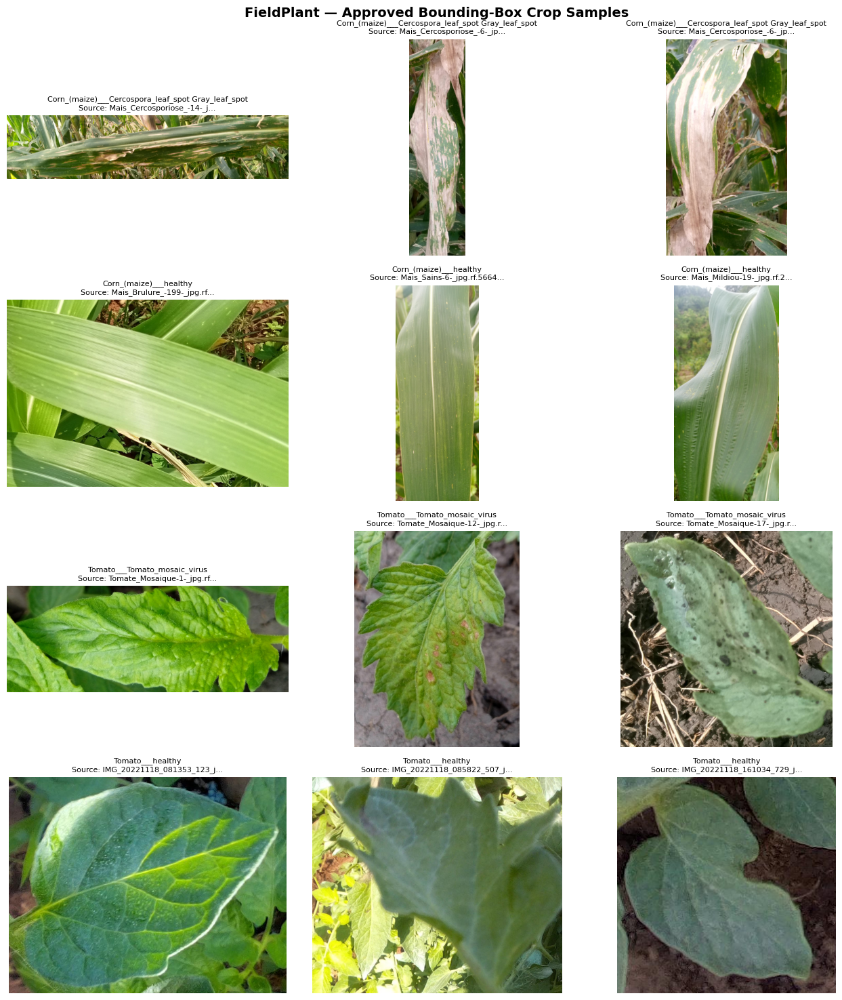

In [ ]:
# Cell 58 — Visual inspection of approved FieldPlant crops

import matplotlib.pyplot as plt
from PIL import Image

samples_per_class = 3

classes = sorted(
    fieldplant_crop_inventory_df["plantvillage_class"].unique()
)

fig, axes = plt.subplots(
    len(classes),
    samples_per_class,
    figsize=(13, 15)
)

for row_idx, class_name in enumerate(classes):

    class_samples = (
        fieldplant_crop_inventory_df[
            fieldplant_crop_inventory_df["plantvillage_class"] == class_name
        ]
        .sample(n=samples_per_class, random_state=42)
    )

    for col_idx, (_, sample) in enumerate(class_samples.iterrows()):

        ax = axes[row_idx, col_idx]

        with Image.open(sample["crop_filepath"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{class_name}\n"
            f"Source: {sample['source_image'][:25]}...",
            fontsize=8
        )

        ax.axis("off")

plt.suptitle(
    "FieldPlant — Approved Bounding-Box Crop Samples",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Cell 59 — Save FieldPlant preparation reports

from pathlib import Path
import pandas as pd

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/fieldplant_preparation"
)

output_dir.mkdir(parents=True, exist_ok=True)

files_to_save = {
    "fieldplant_crop_inventory.csv": fieldplant_crop_inventory_df,
    "fieldplant_crop_integrity.csv": fieldplant_crop_integrity_df
}

print("SAVING FIELDPLANT PREPARATION RESULTS")
print("=" * 60)

for filename, dataframe in files_to_save.items():

    output_path = output_dir / filename

    dataframe.to_csv(output_path, index=False)

    saved_df = pd.read_csv(output_path)

    assert len(saved_df) == len(dataframe)
    assert list(saved_df.columns) == list(dataframe.columns)

    print(f"PASS: {filename}")
    print(f"      Rows: {len(saved_df)}")
    print(f"      Size: {output_path.stat().st_size:,} bytes")

print("\nFINAL FIELDPLANT VALIDATION")
print("-" * 60)

missing_crops = sum(
    not Path(path).is_file()
    for path in fieldplant_crop_inventory_df["crop_filepath"]
)

print("Total crops:", len(fieldplant_crop_inventory_df))
print("Missing crop files:", missing_crops)
print(
    "Valid RGB crops:",
    (
        (fieldplant_crop_integrity_df["status"] == "Valid") &
        (fieldplant_crop_integrity_df["colour_mode"] == "RGB")
    ).sum()
)

assert len(fieldplant_crop_inventory_df) == 504
assert missing_crops == 0
assert (fieldplant_crop_integrity_df["status"] == "Valid").all()

print("\nPASS: FieldPlant preparation files verified.")
print("Google Drive location:", output_dir)

SAVING FIELDPLANT PREPARATION RESULTS
PASS: fieldplant_crop_inventory.csv
      Rows: 504
      Size: 256,450 bytes
PASS: fieldplant_crop_integrity.csv
      Rows: 504
      Size: 140,922 bytes

FINAL FIELDPLANT VALIDATION
------------------------------------------------------------
Total crops: 504
Missing crop files: 0
Valid RGB crops: 504

PASS: FieldPlant preparation files verified.
Google Drive location: /content/drive/MyDrive/AgroVision_FYP2/fieldplant_preparation


In [ ]:
# Cell 60 — FieldPlant exact duplicate check

import hashlib
from pathlib import Path
import pandas as pd

def calculate_sha256(filepath):
    sha256 = hashlib.sha256()

    with open(filepath, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

print("FIELDPLANT EXACT DUPLICATE CHECK")
print("=" * 60)

fieldplant_hash_df = fieldplant_crop_inventory_df[
    ["crop_filepath", "source_image", "plantvillage_class"]
].copy()

fieldplant_hash_df["sha256"] = (
    fieldplant_hash_df["crop_filepath"].apply(calculate_sha256)
)

duplicate_mask = fieldplant_hash_df.duplicated(
    subset="sha256",
    keep=False
)

fieldplant_duplicate_df = fieldplant_hash_df[
    duplicate_mask
].sort_values("sha256")

print("Total crops:", len(fieldplant_hash_df))
print("Unique file hashes:", fieldplant_hash_df["sha256"].nunique())
print("Images in duplicate groups:", len(fieldplant_duplicate_df))
print(
    "Duplicate groups:",
    fieldplant_duplicate_df["sha256"].nunique()
)

if fieldplant_duplicate_df.empty:
    print("\nPASS: No byte-identical crops detected.")
else:
    print("\nDuplicate crop details:")
    display(fieldplant_duplicate_df)

print("\nNote: This check does not detect visually similar images.")

FIELDPLANT EXACT DUPLICATE CHECK
Total crops: 504
Unique file hashes: 504
Images in duplicate groups: 0
Duplicate groups: 0

PASS: No byte-identical crops detected.

Note: This check does not detect visually similar images.


In [ ]:
# Cell 61 — PlantDoc exact duplicate check

print("PLANTDOC EXACT DUPLICATE CHECK")
print("=" * 60)

plantdoc_hash_df = plantdoc_test_inventory_df[
    ["filepath", "plantdoc_class", "plantvillage_class"]
].copy()

# Reuse the SHA-256 function from Cell 60
plantdoc_hash_df["sha256"] = (
    plantdoc_hash_df["filepath"].apply(calculate_sha256)
)

duplicate_mask = plantdoc_hash_df.duplicated(
    subset="sha256",
    keep=False
)

plantdoc_duplicate_df = plantdoc_hash_df[
    duplicate_mask
].sort_values("sha256")

print("Total test images:", len(plantdoc_hash_df))
print("Unique file hashes:", plantdoc_hash_df["sha256"].nunique())
print("Images in duplicate groups:", len(plantdoc_duplicate_df))
print(
    "Duplicate groups:",
    plantdoc_duplicate_df["sha256"].nunique()
)

# Check whether identical files have different mapped labels
cross_class_groups = (
    plantdoc_duplicate_df.groupby("sha256")["plantvillage_class"]
    .nunique()
)

cross_class_count = (cross_class_groups > 1).sum()

print("Cross-class duplicate groups:", cross_class_count)

if plantdoc_duplicate_df.empty:
    print("\nPASS: No byte-identical PlantDoc test images detected.")
else:
    print("\nDuplicate image details:")
    display(plantdoc_duplicate_df)

print("\nNote: This does not detect visually similar images or")
print("overlap with the PlantVillage training dataset.")

PLANTDOC EXACT DUPLICATE CHECK
Total test images: 236
Unique file hashes: 236
Images in duplicate groups: 0
Duplicate groups: 0
Cross-class duplicate groups: 0

PASS: No byte-identical PlantDoc test images detected.

Note: This does not detect visually similar images or
overlap with the PlantVillage training dataset.


In [ ]:
# Cell 62 — Verify PlantVillage dataset availability

from pathlib import Path

print("PLANTVILLAGE DATASET AVAILABILITY")
print("=" * 60)

pv_dir = Path(plantvillage_color_path)

print("Dataset path:", pv_dir)
print("Directory exists:", pv_dir.is_dir())

if pv_dir.is_dir():

    class_dirs = [
        p for p in pv_dir.iterdir()
        if p.is_dir()
    ]

    image_extensions = {".jpg", ".jpeg", ".png"}

    image_count = sum(
        1
        for class_dir in class_dirs
        for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    )

    print("Class folders:", len(class_dirs))
    print("Total images:", image_count)

    assert len(class_dirs) == 38

    print("\nPASS: PlantVillage is available for overlap checking.")

else:
    print("\nCHECK: PlantVillage directory is unavailable.")

PLANTVILLAGE DATASET AVAILABILITY
Dataset path: /root/.cache/kagglehub/datasets/aftaabahmedshaik/plantvillage-dataset/versions/1/color
Directory exists: True
Class folders: 38
Total images: 54305

PASS: PlantVillage is available for overlap checking.


In [ ]:
# Cell 63 — Exact overlap between PlantVillage and external datasets

from pathlib import Path
import pandas as pd
import time

print("CROSS-DATASET EXACT OVERLAP CHECK")
print("=" * 60)

start_time = time.time()

image_extensions = {".jpg", ".jpeg", ".png"}

pv_image_paths = sorted(
    p
    for p in Path(plantvillage_color_path).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
)

print("PlantVillage images to check:", len(pv_image_paths))
print("PlantDoc test images:", len(plantdoc_hash_df))
print("FieldPlant crops:", len(fieldplant_hash_df))

# Build PlantVillage hash inventory
pv_hash_records = []

for index, image_path in enumerate(pv_image_paths, start=1):

    pv_hash_records.append({
        "filepath": str(image_path),
        "plantvillage_class": image_path.parent.name,
        "sha256": calculate_sha256(image_path)
    })

    if index % 10000 == 0:
        print(f"Processed {index:,}/{len(pv_image_paths):,} PlantVillage images")

pv_hash_df = pd.DataFrame(pv_hash_records)

# Compare against external datasets
plantdoc_overlap_df = plantdoc_hash_df.merge(
    pv_hash_df,
    on="sha256",
    how="inner",
    suffixes=("_external", "_plantvillage")
)

fieldplant_overlap_df = fieldplant_hash_df.merge(
    pv_hash_df,
    on="sha256",
    how="inner",
    suffixes=("_external", "_plantvillage")
)

print("\nOVERLAP RESULTS")
print("-" * 60)

print("PlantVillage unique hashes:", pv_hash_df["sha256"].nunique())
print("PlantDoc exact overlap matches:", len(plantdoc_overlap_df))
print("FieldPlant exact overlap matches:", len(fieldplant_overlap_df))

if not plantdoc_overlap_df.empty:
    print("\nPlantDoc overlapping images:")
    display(plantdoc_overlap_df.head(20))

if not fieldplant_overlap_df.empty:
    print("\nFieldPlant overlapping crops:")
    display(fieldplant_overlap_df.head(20))

print("\nElapsed time:", round(time.time() - start_time, 2), "seconds")

print("\nNote: SHA-256 detects byte-identical files only.")
print("Recompressed, resized or visually similar images may not match.")

CROSS-DATASET EXACT OVERLAP CHECK
PlantVillage images to check: 54305
PlantDoc test images: 236
FieldPlant crops: 504
Processed 10,000/54,305 PlantVillage images
Processed 20,000/54,305 PlantVillage images
Processed 30,000/54,305 PlantVillage images
Processed 40,000/54,305 PlantVillage images
Processed 50,000/54,305 PlantVillage images

OVERLAP RESULTS
------------------------------------------------------------
PlantVillage unique hashes: 54284
PlantDoc exact overlap matches: 0
FieldPlant exact overlap matches: 0

Elapsed time: 19.59 seconds

Note: SHA-256 detects byte-identical files only.
Recompressed, resized or visually similar images may not match.


In [ ]:
# Cell 64 — Save cross-dataset overlap audit results

from pathlib import Path
import pandas as pd

audit_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/external_dataset_audit"
)
audit_dir.mkdir(parents=True, exist_ok=True)

audit_files = {
    "plantvillage_hash_inventory.csv": pv_hash_df,
    "plantdoc_hash_inventory.csv": plantdoc_hash_df,
    "fieldplant_hash_inventory.csv": fieldplant_hash_df,
    "plantdoc_exact_overlap.csv": plantdoc_overlap_df,
    "fieldplant_exact_overlap.csv": fieldplant_overlap_df
}

print("SAVING EXTERNAL DATASET AUDIT")
print("=" * 60)

for filename, dataframe in audit_files.items():
    output_path = audit_dir / filename

    dataframe.to_csv(output_path, index=False)
    reloaded_df = pd.read_csv(output_path)

    assert len(reloaded_df) == len(dataframe)
    assert list(reloaded_df.columns) == list(dataframe.columns)

    print(f"PASS: {filename} ({len(dataframe):,} rows)")

print("\nFINAL EXACT-OVERLAP SUMMARY")
print("-" * 60)

print("PlantVillage images:", len(pv_hash_df))
print("PlantVillage unique hashes:", pv_hash_df["sha256"].nunique())
print("PlantDoc exact overlaps:", len(plantdoc_overlap_df))
print("FieldPlant exact overlaps:", len(fieldplant_overlap_df))

print("\nPASS: Audit results saved successfully.")
print("Google Drive location:", audit_dir)

SAVING EXTERNAL DATASET AUDIT
PASS: plantvillage_hash_inventory.csv (54,305 rows)
PASS: plantdoc_hash_inventory.csv (236 rows)
PASS: fieldplant_hash_inventory.csv (504 rows)
PASS: plantdoc_exact_overlap.csv (0 rows)
PASS: fieldplant_exact_overlap.csv (0 rows)

FINAL EXACT-OVERLAP SUMMARY
------------------------------------------------------------
PlantVillage images: 54305
PlantVillage unique hashes: 54284
PlantDoc exact overlaps: 0
FieldPlant exact overlaps: 0

PASS: Audit results saved successfully.
Google Drive location: /content/drive/MyDrive/AgroVision_FYP2/external_dataset_audit


In [ ]:
# Cell 65 — Generate perceptual hashes for similarity screening

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from scipy.fft import dctn
import time

def calculate_phash(filepath, hash_size=8, highfreq_factor=4):
    """Calculate a 64-bit perceptual hash using DCT."""
    size = hash_size * highfreq_factor

    with Image.open(filepath) as img:
        img = img.convert("L").resize(
            (size, size),
            Image.Resampling.LANCZOS
        )
        pixels = np.asarray(img, dtype=np.float32)

    dct_values = dctn(pixels, type=2, norm="ortho")
    low_freq = dct_values[:hash_size, :hash_size]

    # Exclude the DC coefficient when calculating the median
    median = np.median(low_freq.flatten()[1:])
    bits = low_freq > median

    return f"{int(''.join(bits.flatten().astype(int).astype(str)), 2):016x}"

print("GENERATING PERCEPTUAL HASHES")
print("=" * 60)

start_time = time.time()

datasets = {
    "PlantVillage": (pv_hash_df, "filepath"),
    "PlantDoc": (plantdoc_hash_df, "filepath"),
    "FieldPlant": (fieldplant_hash_df, "crop_filepath")
}

phash_results = {}

for dataset_name, (dataframe, path_column) in datasets.items():

    print(f"\nProcessing {dataset_name}: {len(dataframe):,} images")

    result_df = dataframe.copy()

    result_df["phash"] = [
        calculate_phash(filepath)
        for filepath in result_df[path_column]
    ]

    phash_results[dataset_name] = result_df

    print(f"PASS: {len(result_df):,} perceptual hashes generated")

pv_phash_df = phash_results["PlantVillage"]
plantdoc_phash_df = phash_results["PlantDoc"]
fieldplant_phash_df = phash_results["FieldPlant"]

print("\nSUMMARY")
print("-" * 60)
print("PlantVillage:", len(pv_phash_df))
print("PlantDoc:", len(plantdoc_phash_df))
print("FieldPlant:", len(fieldplant_phash_df))
print("Elapsed time:", round(time.time() - start_time, 2), "seconds")

print("\nPASS: Perceptual hash generation completed.")

GENERATING PERCEPTUAL HASHES

Processing PlantVillage: 54,305 images
PASS: 54,305 perceptual hashes generated

Processing PlantDoc: 236 images
PASS: 236 perceptual hashes generated

Processing FieldPlant: 504 images
PASS: 504 perceptual hashes generated

SUMMARY
------------------------------------------------------------
PlantVillage: 54305
PlantDoc: 236
FieldPlant: 504
Elapsed time: 180.39 seconds

PASS: Perceptual hash generation completed.


In [ ]:
# Cell 66 — Cross-dataset perceptual similarity screening

import numpy as np
import pandas as pd
import time

print("CROSS-DATASET PERCEPTUAL SIMILARITY SCREENING")
print("=" * 60)

start_time = time.time()

# Convert hexadecimal hashes into integers
pv_hashes = [
    int(value, 16)
    for value in pv_phash_df["phash"]
]

# Group PlantVillage paths by hash.
# This avoids repeatedly comparing identical hash values.
pv_hash_lookup = {}

for idx, hash_value in enumerate(pv_hashes):
    pv_hash_lookup.setdefault(hash_value, []).append(idx)

unique_pv_hashes = list(pv_hash_lookup.keys())

print("PlantVillage images:", len(pv_hashes))
print("Unique PlantVillage pHashes:", len(unique_pv_hashes))

def screen_external_dataset(external_df, path_column, dataset_name):

    results = []

    for _, row in external_df.iterrows():

        external_hash = int(row["phash"], 16)

        # Find the closest PlantVillage perceptual hash
        best_hash = min(
            unique_pv_hashes,
            key=lambda pv_hash: (
                external_hash ^ pv_hash
            ).bit_count()
        )

        distance = (external_hash ^ best_hash).bit_count()

        # Retrieve a representative matching PlantVillage image
        pv_idx = pv_hash_lookup[best_hash][0]

        results.append({
            "dataset": dataset_name,
            "external_filepath": row[path_column],
            "external_class": row["plantvillage_class"],
            "plantvillage_filepath": pv_phash_df.iloc[pv_idx]["filepath"],
            "plantvillage_class": pv_phash_df.iloc[pv_idx]["plantvillage_class"],
            "phash_distance": distance,
            "flagged_for_review": distance <= 10
        })

    return pd.DataFrame(results)

plantdoc_similarity_df = screen_external_dataset(
    plantdoc_phash_df,
    "filepath",
    "PlantDoc"
)

fieldplant_similarity_df = screen_external_dataset(
    fieldplant_phash_df,
    "crop_filepath",
    "FieldPlant"
)

print("\nRESULTS")
print("-" * 60)

for name, df in [
    ("PlantDoc", plantdoc_similarity_df),
    ("FieldPlant", fieldplant_similarity_df)
]:
    print(f"\n{name}")
    print("Total images:", len(df))
    print("Exact pHash matches:", (df["phash_distance"] == 0).sum())
    print("Distance 1–5:", df["phash_distance"].between(1, 5).sum())
    print("Distance 6–10:", df["phash_distance"].between(6, 10).sum())
    print("Flagged for review:", df["flagged_for_review"].sum())
    print("Minimum distance:", df["phash_distance"].min())
    print("Median distance:", df["phash_distance"].median())

print("\nELAPSED TIME")
print("-" * 60)
print(round(time.time() - start_time, 2), "seconds")

print("\nPASS: Similarity screening completed.")
print("Note: Flagged images are candidates, not confirmed duplicates.")

CROSS-DATASET PERCEPTUAL SIMILARITY SCREENING
PlantVillage images: 54305
Unique PlantVillage pHashes: 54283

RESULTS
------------------------------------------------------------

PlantDoc
Total images: 236
Exact pHash matches: 0
Distance 1–5: 0
Distance 6–10: 23
Flagged for review: 23
Minimum distance: 6
Median distance: 14.0

FieldPlant
Total images: 504
Exact pHash matches: 0
Distance 1–5: 0
Distance 6–10: 6
Flagged for review: 6
Minimum distance: 10
Median distance: 16.0

ELAPSED TIME
------------------------------------------------------------
7.92 seconds

PASS: Similarity screening completed.
Note: Flagged images are candidates, not confirmed duplicates.


FLAGGED CROSS-DATASET IMAGE PAIRS
Total flagged pairs: 29
Displaying the 10 closest pairs.


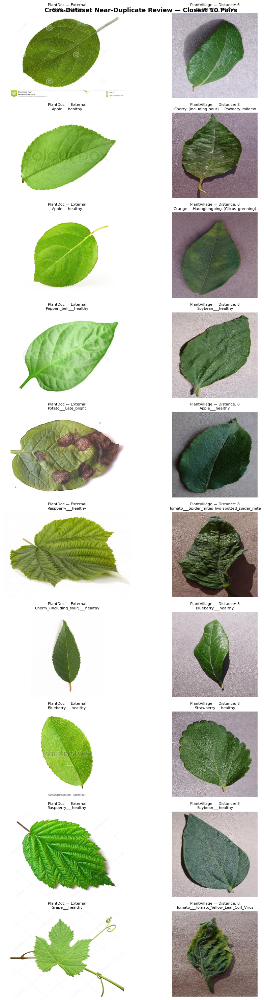

In [ ]:
# Cell 67 — Visualise closest cross-dataset similarity matches

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

combined_similarity_df = pd.concat(
    [plantdoc_similarity_df, fieldplant_similarity_df],
    ignore_index=True
)

flagged_similarity_df = (
    combined_similarity_df[
        combined_similarity_df["flagged_for_review"]
    ]
    .sort_values("phash_distance")
    .reset_index(drop=True)
)

print("FLAGGED CROSS-DATASET IMAGE PAIRS")
print("=" * 60)

print("Total flagged pairs:", len(flagged_similarity_df))
print("Displaying the 10 closest pairs.")

samples = flagged_similarity_df.head(10)

fig, axes = plt.subplots(
    len(samples), 2,
    figsize=(10, len(samples) * 3)
)

for i, (_, row) in enumerate(samples.iterrows()):

    with Image.open(row["external_filepath"]) as img:
        axes[i, 0].imshow(img.convert("RGB"))

    with Image.open(row["plantvillage_filepath"]) as img:
        axes[i, 1].imshow(img.convert("RGB"))

    axes[i, 0].set_title(
        f"{row['dataset']} — External\n"
        f"{row['external_class']}",
        fontsize=8
    )

    axes[i, 1].set_title(
        f"PlantVillage — Distance: {row['phash_distance']}\n"
        f"{row['plantvillage_class']}",
        fontsize=8
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.suptitle(
    "Cross-Dataset Near-Duplicate Review — Closest 10 Pairs",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

REMAINING NEAR-DUPLICATE CANDIDATES
Pairs to review: 19


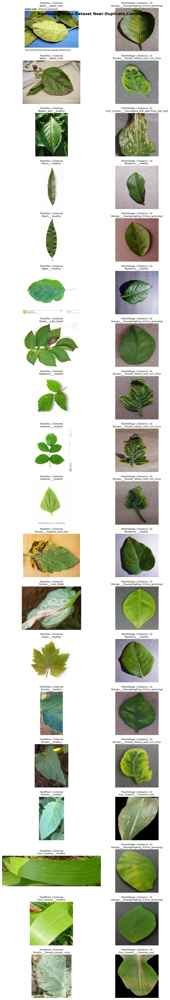

In [ ]:
# Cell 68 — Review remaining flagged image pairs

import matplotlib.pyplot as plt
from PIL import Image

remaining_pairs = flagged_similarity_df.iloc[10:].reset_index(drop=True)

print("REMAINING NEAR-DUPLICATE CANDIDATES")
print("=" * 60)
print("Pairs to review:", len(remaining_pairs))

fig, axes = plt.subplots(
    len(remaining_pairs), 2,
    figsize=(9, len(remaining_pairs) * 2.5),
    squeeze=False
)

for i, (_, row) in enumerate(remaining_pairs.iterrows()):

    with Image.open(row["external_filepath"]) as img:
        axes[i, 0].imshow(img.convert("RGB"))

    with Image.open(row["plantvillage_filepath"]) as img:
        axes[i, 1].imshow(img.convert("RGB"))

    axes[i, 0].set_title(
        f"{row['dataset']} | External\n"
        f"{row['external_class']}",
        fontsize=8
    )

    axes[i, 1].set_title(
        f"PlantVillage | Distance: {row['phash_distance']}\n"
        f"{row['plantvillage_class']}",
        fontsize=8
    )

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.suptitle(
    "Remaining Cross-Dataset Near-Duplicate Candidates",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Cell 69 — Save final cross-dataset similarity audit

from pathlib import Path
import pandas as pd

audit_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/external_dataset_audit"
)
audit_dir.mkdir(parents=True, exist_ok=True)

# Record the visual review of the 29 flagged pairs
visual_review_df = flagged_similarity_df.copy()

visual_review_df["visual_review_status"] = (
    "Reviewed - no apparent duplicate"
)

visual_review_df["review_note"] = (
    "Images appear visually distinct; "
    "no confirmed duplicate identified. "
    "Review is based on displayed image pairs."
)

files_to_save = {
    "plantvillage_phash_inventory.csv": pv_phash_df,
    "plantdoc_phash_inventory.csv": plantdoc_phash_df,
    "fieldplant_phash_inventory.csv": fieldplant_phash_df,
    "plantdoc_similarity_screening.csv": plantdoc_similarity_df,
    "fieldplant_similarity_screening.csv": fieldplant_similarity_df,
    "flagged_pairs_visual_review.csv": visual_review_df
}

print("SAVING FINAL SIMILARITY AUDIT")
print("=" * 60)

for filename, dataframe in files_to_save.items():

    output_path = audit_dir / filename
    dataframe.to_csv(output_path, index=False)

    saved_df = pd.read_csv(output_path)

    assert len(saved_df) == len(dataframe)
    assert list(saved_df.columns) == list(dataframe.columns)

    print(f"PASS: {filename} ({len(saved_df):,} rows)")

print("\nFINAL AUDIT SUMMARY")
print("-" * 60)

print("PlantDoc images screened:", len(plantdoc_similarity_df))
print("FieldPlant crops screened:", len(fieldplant_similarity_df))
print("Flagged pairs reviewed:", len(visual_review_df))

assert len(visual_review_df) == 29

print("\nPASS: Similarity audit saved successfully.")
print("Google Drive location:", audit_dir)

SAVING FINAL SIMILARITY AUDIT
PASS: plantvillage_phash_inventory.csv (54,305 rows)
PASS: plantdoc_phash_inventory.csv (236 rows)
PASS: fieldplant_phash_inventory.csv (504 rows)
PASS: plantdoc_similarity_screening.csv (236 rows)
PASS: fieldplant_similarity_screening.csv (504 rows)
PASS: flagged_pairs_visual_review.csv (29 rows)

FINAL AUDIT SUMMARY
------------------------------------------------------------
PlantDoc images screened: 236
FieldPlant crops screened: 504
Flagged pairs reviewed: 29

PASS: Similarity audit saved successfully.
Google Drive location: /content/drive/MyDrive/AgroVision_FYP2/external_dataset_audit


In [ ]:
# Cell 70 — Final external dataset readiness summary

print("AGROVISION — EXTERNAL DATASET READINESS")
print("=" * 65)

# PlantDoc
pd_images = len(plantdoc_test_inventory_df)
pd_classes = plantdoc_test_inventory_df["plantvillage_class"].nunique()

# FieldPlant
fp_crops = len(fieldplant_crop_inventory_df)
fp_classes = fieldplant_crop_inventory_df["plantvillage_class"].nunique()
fp_sources = fieldplant_crop_inventory_df["source_image_filepath"].nunique()

# Combined class coverage
external_classes = (
    set(plantdoc_test_inventory_df["plantvillage_class"])
    | set(fieldplant_crop_inventory_df["plantvillage_class"])
)

pv_classes = set(plantvillage_classes)

print("\nPLANTDOC")
print("-" * 65)
print("Test images:", pd_images)
print("Mapped test classes:", pd_classes)

print("\nFIELDPLANT")
print("-" * 65)
print("Extracted leaf crops:", fp_crops)
print("Approved classes:", fp_classes)
print("Unique source photographs:", fp_sources)
print("Additional crops from shared sources:", fp_crops - fp_sources)

print("\nCOMBINED EXTERNAL COVERAGE")
print("-" * 65)
print("PlantVillage classes:", len(pv_classes))
print("Classes represented externally:", len(external_classes))
print("Coverage:", f"{len(external_classes) / len(pv_classes):.1%}")
print("Classes without external samples:", len(pv_classes - external_classes))

print("\nFINAL VALIDATION")
print("-" * 65)

assert pd_images == 236
assert pd_classes == 27
assert fp_crops == 504
assert fp_classes == 4
assert external_classes.issubset(pv_classes)
assert len(plantdoc_overlap_df) == 0
assert len(fieldplant_overlap_df) == 0
assert len(visual_review_df) == 29

print("PASS: Dataset counts and class mappings verified.")
print("PASS: Exact overlap checks verified.")
print("PASS: Visual-review records verified.")

print("\nNOTE: Final evaluation must keep PlantDoc and FieldPlant separate.")
print("NOTE: FieldPlant crops retain their source-image identifiers.")
print("NOTE: External samples must not be used for model training or tuning.")

AGROVISION — EXTERNAL DATASET READINESS

PLANTDOC
-----------------------------------------------------------------
Test images: 236
Mapped test classes: 27

FIELDPLANT
-----------------------------------------------------------------
Extracted leaf crops: 504
Approved classes: 4
Unique source photographs: 289
Additional crops from shared sources: 215

COMBINED EXTERNAL COVERAGE
-----------------------------------------------------------------
PlantVillage classes: 38
Classes represented externally: 28
Coverage: 73.7%
Classes without external samples: 10

FINAL VALIDATION
-----------------------------------------------------------------
PASS: Dataset counts and class mappings verified.
PASS: Exact overlap checks verified.
PASS: Visual-review records verified.

NOTE: Final evaluation must keep PlantDoc and FieldPlant separate.
NOTE: FieldPlant crops retain their source-image identifiers.
NOTE: External samples must not be used for model training or tuning.


In [63]:
# Cell 71 — Expanded PlantVillage class inventory

from pathlib import Path
import pandas as pd

pv_dir = Path(plantvillage_color_path)

image_extensions = {".jpg", ".jpeg", ".png"}

records = []

for class_dir in sorted(pv_dir.iterdir()):

    if not class_dir.is_dir():
        continue

    image_files = [
        path for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in image_extensions
    ]

    records.append({
        "class_name": class_dir.name,
        "image_count": len(image_files)
    })

pv_class_distribution_df = pd.DataFrame(records)

pv_class_distribution_df = (
    pv_class_distribution_df
    .sort_values("image_count", ascending=False)
    .reset_index(drop=True)
)

print("EXPANDED PLANTVILLAGE DATASET")
print("=" * 60)

print("Total classes:", len(pv_class_distribution_df))
print("Total images:", pv_class_distribution_df["image_count"].sum())

print("\nCLASS DISTRIBUTION")
print("-" * 60)

display(pv_class_distribution_df)

print("\nVALIDATION")
print("-" * 60)

assert len(pv_class_distribution_df) == 38
assert pv_class_distribution_df["image_count"].sum() == 54305

assert set(pv_class_distribution_df["class_name"]) == set(
    plantvillage_classes
)

print("PASS: All 38 expected PlantVillage classes verified.")

EXPANDED PLANTVILLAGE DATASET
Total classes: 38
Total images: 54305

CLASS DISTRIBUTION
------------------------------------------------------------


,class_name,image_count
0,Orange___Haunglongbing_(Citrus_greening),5507
1,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
2,Soybean___healthy,5090
3,Peach___Bacterial_spot,2297
4,Tomato___Bacterial_spot,2127
5,Tomato___Late_blight,1909
6,Squash___Powdery_mildew,1835
7,Tomato___Septoria_leaf_spot,1771
8,Tomato___Spider_mites Two-spotted_spider_mite,1676
9,Apple___healthy,1645



VALIDATION
------------------------------------------------------------
PASS: All 38 expected PlantVillage classes verified.


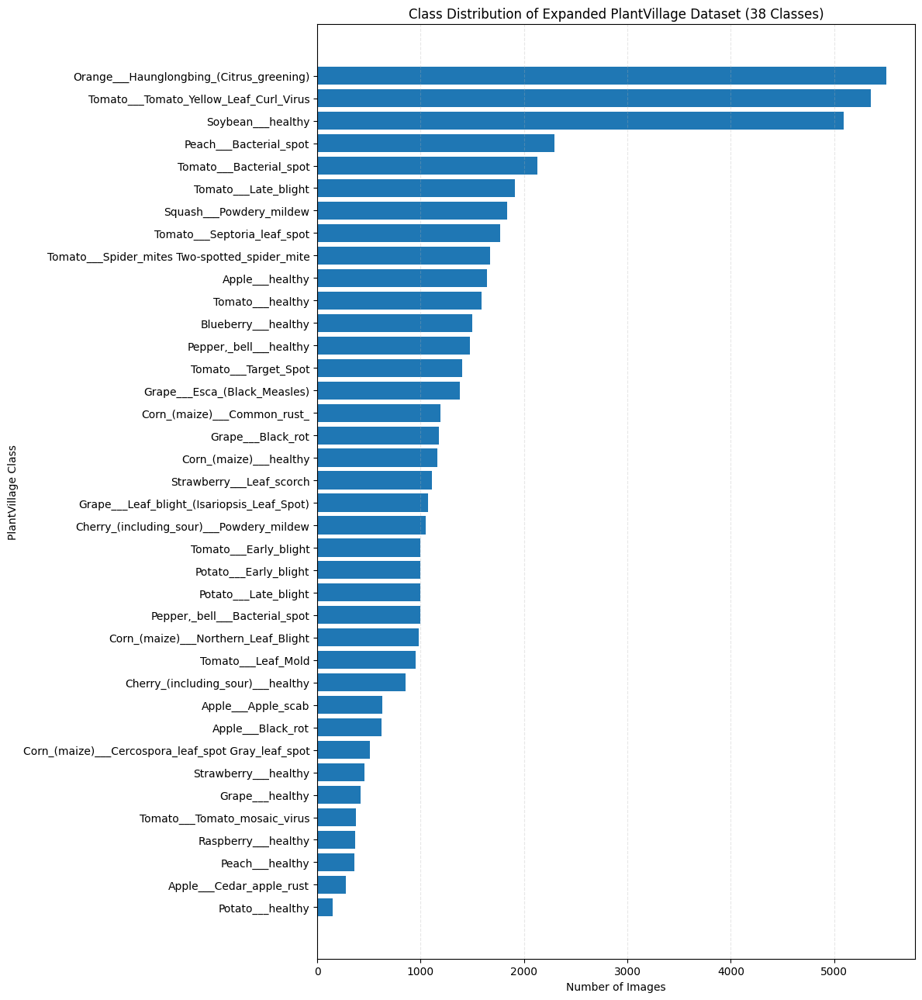

In [64]:
# Cell 72 — Visualise PlantVillage class distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 13))

plt.barh(
    pv_class_distribution_df["class_name"],
    pv_class_distribution_df["image_count"]
)

plt.gca().invert_yaxis()

plt.xlabel("Number of Images")
plt.ylabel("PlantVillage Class")
plt.title("Class Distribution of Expanded PlantVillage Dataset (38 Classes)")

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.show()

In [65]:
# Cell 73 — Expanded PlantVillage image integrity audit

from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd

integrity_records = []

for class_dir in sorted(pv_dir.iterdir()):
    if not class_dir.is_dir():
        continue

    for image_path in sorted(class_dir.iterdir()):
        if image_path.suffix.lower() not in image_extensions:
            continue

        record = {
            "class_name": class_dir.name,
            "filepath": str(image_path),
            "filename": image_path.name,
            "width": None,
            "height": None,
            "colour_mode": None,
            "status": "unreadable"
        }

        try:
            with Image.open(image_path) as img:
                record["width"], record["height"] = img.size
                record["colour_mode"] = img.mode
                img.verify()

            record["status"] = "valid"

        except (OSError, ValueError, UnidentifiedImageError):
            pass

        integrity_records.append(record)

pv_integrity_df = pd.DataFrame(integrity_records)

print("PLANTVILLAGE IMAGE INTEGRITY AUDIT")
print("=" * 60)

print("Total images checked:", len(pv_integrity_df))
print("Valid images:", (pv_integrity_df["status"] == "valid").sum())
print("Unreadable images:", (pv_integrity_df["status"] == "unreadable").sum())

print("\nCOLOUR MODE DISTRIBUTION")
display(pv_integrity_df["colour_mode"].value_counts(dropna=False))

print("\nIMAGE DIMENSION SUMMARY")
display(pv_integrity_df[["width", "height"]].describe())

print("\nUNREADABLE FILES")
display(pv_integrity_df[pv_integrity_df["status"] != "valid"])

assert len(pv_integrity_df) == 54305

print("\nPASS: All expected images were inspected.")

PLANTVILLAGE IMAGE INTEGRITY AUDIT
Total images checked: 54305
Valid images: 54305
Unreadable images: 0

COLOUR MODE DISTRIBUTION


,count
colour_mode,
RGB,54304
RGBA,1



IMAGE DIMENSION SUMMARY


,width,height
count,54305.0,54305.0
mean,256.0,256.0
std,0.0,0.0
min,256.0,256.0
25%,256.0,256.0
50%,256.0,256.0
75%,256.0,256.0
max,256.0,256.0



UNREADABLE FILES


,class_name,filepath,filename,width,height,colour_mode,status



PASS: All expected images were inspected.


In [66]:
# Cell 74 — Save expanded PlantVillage EDA results

from pathlib import Path

pv_output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

pv_output_dir.mkdir(parents=True, exist_ok=True)

distribution_file = pv_output_dir / "class_distribution.csv"
integrity_file = pv_output_dir / "image_integrity.csv"

pv_class_distribution_df.to_csv(
    distribution_file,
    index=False
)

pv_integrity_df.to_csv(
    integrity_file,
    index=False
)

print("PLANTVILLAGE EDA RESULTS SAVED")
print("=" * 60)

print("Class distribution:", distribution_file)
print("Image integrity:", integrity_file)

assert distribution_file.is_file()
assert integrity_file.is_file()

print("\nPASS: Both CSV files saved successfully.")

PLANTVILLAGE EDA RESULTS SAVED
Class distribution: /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/class_distribution.csv
Image integrity: /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/image_integrity.csv

PASS: Both CSV files saved successfully.


In [67]:
# Cell 75 — Locate previously saved PlantVillage duplicate records

from pathlib import Path

project_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2"
)

print("SAVED DUPLICATE / HASH RECORDS")
print("=" * 60)

keywords = ("hash", "duplicate", "perceptual", "phash")

matching_files = sorted(
    path
    for path in project_dir.rglob("*")
    if path.is_file()
    and any(
        keyword in path.name.lower()
        for keyword in keywords
    )
)

for path in matching_files:
    print(path.relative_to(project_dir))

print("\nTotal matching files:", len(matching_files))

SAVED DUPLICATE / HASH RECORDS
external_dataset_audit/fieldplant_hash_inventory.csv
external_dataset_audit/fieldplant_phash_inventory.csv
external_dataset_audit/plantdoc_hash_inventory.csv
external_dataset_audit/plantdoc_phash_inventory.csv
external_dataset_audit/plantvillage_hash_inventory.csv
external_dataset_audit/plantvillage_phash_inventory.csv

Total matching files: 6


In [68]:
# Cell 76 — Inspect saved PlantVillage hash inventories

import pandas as pd
from pathlib import Path

audit_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "external_dataset_audit"
)

pv_hash_df = pd.read_csv(
    audit_dir / "plantvillage_hash_inventory.csv"
)

pv_phash_df = pd.read_csv(
    audit_dir / "plantvillage_phash_inventory.csv"
)

print("PLANTVILLAGE SAVED HASH INVENTORIES")
print("=" * 60)

print("\nSHA-256 INVENTORY")
print("Total records:", len(pv_hash_df))
print("Columns:", pv_hash_df.columns.tolist())
display(pv_hash_df.head(5))

print("\nPERCEPTUAL HASH INVENTORY")
print("Total records:", len(pv_phash_df))
print("Columns:", pv_phash_df.columns.tolist())
display(pv_phash_df.head(5))

print("\nVALIDATION")
print("-" * 60)

assert len(pv_hash_df) == 54305
assert len(pv_phash_df) == 54305

print("PASS: Both inventories contain 54,305 records.")

PLANTVILLAGE SAVED HASH INVENTORIES

SHA-256 INVENTORY
Total records: 54305
Columns: ['filepath', 'plantvillage_class', 'sha256']


,filepath,plantvillage_class,sha256
0,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,cc34c72a9d19c74ab2fe86204143856e370d0c981a9038...
1,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,653e1d01d1df46983ecfc49b171414ae9ab6030f0ba106...
2,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,c3580cb39e6cfd5ff54b95516ead2e2cab9b19b2d3ba54...
3,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,131db5601b6b9bc4246a2f4fe3c9080c59f26d5fba1ea6...
4,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,d55b641a35a204b8f92fe18953c5c7f4f42980406da9d9...



PERCEPTUAL HASH INVENTORY
Total records: 54305
Columns: ['filepath', 'plantvillage_class', 'sha256', 'phash']


,filepath,plantvillage_class,sha256,phash
0,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,cc34c72a9d19c74ab2fe86204143856e370d0c981a9038...,eeb185d21aca690f
1,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,653e1d01d1df46983ecfc49b171414ae9ab6030f0ba106...,b9e184d31a9c1db5
2,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,c3580cb39e6cfd5ff54b95516ead2e2cab9b19b2d3ba54...,96ed92e04b966996
3,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,131db5601b6b9bc4246a2f4fe3c9080c59f26d5fba1ea6...,fcfc005a4b4d7c46
4,/root/.cache/kagglehub/datasets/aftaabahmedsha...,Apple___Apple_scab,d55b641a35a204b8f92fe18953c5c7f4f42980406da9d9...,abfd859095925a9a



VALIDATION
------------------------------------------------------------
PASS: Both inventories contain 54,305 records.


In [69]:
# Cell 77 — Restore PlantVillage paths in saved inventories

from pathlib import Path

pv_dir = Path(plantvillage_color_path)

def restore_pv_path(old_path):
    old_path = Path(old_path)

    # Reconstruct using the original class folder and filename
    return str(pv_dir / old_path.parent.name / old_path.name)


pv_hash_df["filepath"] = (
    pv_hash_df["filepath"].apply(restore_pv_path)
)

pv_phash_df["filepath"] = (
    pv_phash_df["filepath"].apply(restore_pv_path)
)

print("PLANTVILLAGE PATH RECOVERY")
print("=" * 60)

print("\nExample restored path:")
print(pv_hash_df["filepath"].iloc[0])

print("\nVALIDATION")
print("-" * 60)

missing_paths = [
    path for path in pv_hash_df["filepath"]
    if not Path(path).is_file()
]

duplicate_paths = pv_hash_df["filepath"].duplicated().sum()

class_mismatches = sum(
    Path(path).parent.name != class_name
    for path, class_name in zip(
        pv_hash_df["filepath"],
        pv_hash_df["plantvillage_class"]
    )
)

print("Total records:", len(pv_hash_df))
print("Missing files:", len(missing_paths))
print("Duplicate file paths:", duplicate_paths)
print("Class/path mismatches:", class_mismatches)

assert len(missing_paths) == 0
assert duplicate_paths == 0
assert class_mismatches == 0

assert (
    pv_hash_df["filepath"].tolist()
    == pv_phash_df["filepath"].tolist()
)

print("\nPASS: All PlantVillage paths restored successfully.")

PLANTVILLAGE PATH RECOVERY

Example restored path:
/kaggle/input/plantvillage-dataset/color/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG

VALIDATION
------------------------------------------------------------
Total records: 54305
Missing files: 0
Duplicate file paths: 0
Class/path mismatches: 0

PASS: All PlantVillage paths restored successfully.


In [70]:
# Cell 78 — Analyse exact duplicate groups in PlantVillage

print("PLANTVILLAGE EXACT DUPLICATE ANALYSIS")
print("=" * 60)

# Identify all records sharing a SHA-256 hash
pv_duplicate_df = (
    pv_hash_df[
        pv_hash_df.duplicated(
            subset="sha256",
            keep=False
        )
    ]
    .sort_values(["sha256", "plantvillage_class", "filepath"])
    .copy()
)

# Summarise duplicate groups
pv_duplicate_groups_df = (
    pv_duplicate_df
    .groupby("sha256")
    .agg(
        image_count=("filepath", "size"),
        class_count=("plantvillage_class", "nunique"),
        classes=("plantvillage_class", lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
)

total_groups = len(pv_duplicate_groups_df)

excess_copies = (
    pv_duplicate_groups_df["image_count"] - 1
).sum()

cross_class_groups = (
    pv_duplicate_groups_df["class_count"] > 1
).sum()

print("Total images:", len(pv_hash_df))
print("Unique SHA-256 hashes:", pv_hash_df["sha256"].nunique())
print("Duplicate groups:", total_groups)
print("Images in duplicate groups:", len(pv_duplicate_df))
print("Excess duplicate copies:", excess_copies)
print("Cross-class duplicate groups:", cross_class_groups)

print("\nDUPLICATE GROUP SUMMARY")
display(pv_duplicate_groups_df)

print("\nVALIDATION")
print("-" * 60)

assert len(pv_hash_df) == 54305
assert excess_copies == 21
assert cross_class_groups == 0

print("PASS: Exact duplicates verified with no class conflicts.")

PLANTVILLAGE EXACT DUPLICATE ANALYSIS
Total images: 54305
Unique SHA-256 hashes: 54284
Duplicate groups: 21
Images in duplicate groups: 42
Excess duplicate copies: 21
Cross-class duplicate groups: 0

DUPLICATE GROUP SUMMARY


,sha256,image_count,class_count,classes
0,12852b3616bcf0ba39b03b5677e74f50f5f6abf4d38957...,2,1,Tomato___healthy
1,262198126fd6d982126b69261723e13abb36b383138797...,2,1,Apple___healthy
2,2a05a74db3a270ac0ec77c00ebe89a332eed5898194351...,2,1,Tomato___healthy
3,2aeb7479e975df37dfb54aa7b403f57f2ad90b018c3780...,2,1,Tomato___Late_blight
4,32e9ffabaa054c19ae8df95e94fbd7a25105defdea1214...,2,1,Tomato___healthy
5,372bc4a6e18895011eaa18638acf8cdd83db9c5909af02...,2,1,Apple___healthy
6,375eee7b5da77c7afdd73d089574bee3148d04cbe266ee...,2,1,Tomato___Late_blight
7,3a60a7b6f3a287981d21dca37f27e5480cc46d1144688d...,2,1,Tomato___Late_blight
8,4913a3835e692530e507d542caccacc0d0a7b2fd708782...,2,1,Tomato___Late_blight
9,5d486b62abe59b8dea5aef6b63f887bacd12bbc3cb2a15...,2,1,Apple___healthy



VALIDATION
------------------------------------------------------------
PASS: Exact duplicates verified with no class conflicts.


In [71]:
# Cell 79 — Create deduplicated PlantVillage inventory

from pathlib import Path
import pandas as pd

# Sort records to make duplicate selection deterministic
pv_sorted_df = (
    pv_phash_df
    .sort_values(["sha256", "filepath"])
    .reset_index(drop=True)
    .copy()
)

# Identify which records are retained
pv_sorted_df["retain"] = ~pv_sorted_df.duplicated(
    subset="sha256",
    keep="first"
)

# Retained images
pv_clean_inventory_df = (
    pv_sorted_df[pv_sorted_df["retain"]]
    .drop(columns="retain")
    .reset_index(drop=True)
    .copy()
)

# Excluded duplicate copies
pv_excluded_duplicates_df = (
    pv_sorted_df[~pv_sorted_df["retain"]]
    .drop(columns="retain")
    .reset_index(drop=True)
    .copy()
)

pv_excluded_duplicates_df["exclusion_reason"] = (
    "Exact duplicate (SHA-256)"
)

print("PLANTVILLAGE DEDUPLICATION")
print("=" * 60)

print("Original images:", len(pv_phash_df))
print("Retained images:", len(pv_clean_inventory_df))
print("Excluded duplicate copies:", len(pv_excluded_duplicates_df))
print("Remaining classes:", pv_clean_inventory_df["plantvillage_class"].nunique())

print("\nEXCLUSIONS BY CLASS")
display(
    pv_excluded_duplicates_df["plantvillage_class"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="excluded_count")
)

print("\nVALIDATION")
print("-" * 60)

assert len(pv_clean_inventory_df) == 54284
assert len(pv_excluded_duplicates_df) == 21
assert pv_clean_inventory_df["sha256"].is_unique
assert pv_clean_inventory_df["plantvillage_class"].nunique() == 38

print("PASS: Deduplicated inventory created successfully.")

PLANTVILLAGE DEDUPLICATION
Original images: 54305
Retained images: 54284
Excluded duplicate copies: 21
Remaining classes: 38

EXCLUSIONS BY CLASS


,class_name,excluded_count
0,Tomato___Late_blight,8
1,Apple___healthy,7
2,Tomato___healthy,6



VALIDATION
------------------------------------------------------------
PASS: Deduplicated inventory created successfully.


In [72]:
# Cell 80 — Inspect perceptual-hash collisions

print("PLANTVILLAGE PERCEPTUAL-HASH COLLISION CHECK")
print("=" * 60)

# Identify images sharing identical perceptual hashes
pv_phash_collisions_df = (
    pv_clean_inventory_df[
        pv_clean_inventory_df.duplicated(
            subset="phash",
            keep=False
        )
    ]
    .sort_values(["phash", "plantvillage_class", "filepath"])
    .copy()
)

# Summarise collision groups
pv_phash_collision_summary_df = (
    pv_phash_collisions_df
    .groupby("phash")
    .agg(
        image_count=("filepath", "size"),
        unique_sha256=("sha256", "nunique"),
        class_count=("plantvillage_class", "nunique"),
        classes=(
            "plantvillage_class",
            lambda x: ", ".join(sorted(set(x)))
        )
    )
    .reset_index()
)

print("Deduplicated images:", len(pv_clean_inventory_df))
print("Unique perceptual hashes:",
      pv_clean_inventory_df["phash"].nunique())

print("Perceptual-hash collision groups:",
      len(pv_phash_collision_summary_df))

print("Images in collision groups:",
      len(pv_phash_collisions_df))

print(
    "Cross-class collision groups:",
    (pv_phash_collision_summary_df["class_count"] > 1).sum()
)

print("\nCOLLISION GROUP SUMMARY")
display(pv_phash_collision_summary_df)

print("\nVALIDATION")
assert len(pv_clean_inventory_df) == 54284
assert pv_clean_inventory_df["sha256"].is_unique
assert pv_clean_inventory_df["phash"].notna().all()

print("PASS: Perceptual-hash collision screening completed.")

PLANTVILLAGE PERCEPTUAL-HASH COLLISION CHECK
Deduplicated images: 54284
Unique perceptual hashes: 54283
Perceptual-hash collision groups: 1
Images in collision groups: 2
Cross-class collision groups: 0

COLLISION GROUP SUMMARY


,phash,image_count,unique_sha256,class_count,classes
0,8080a02b9abb6fff,2,2,1,Corn_(maize)___healthy



VALIDATION
PASS: Perceptual-hash collision screening completed.


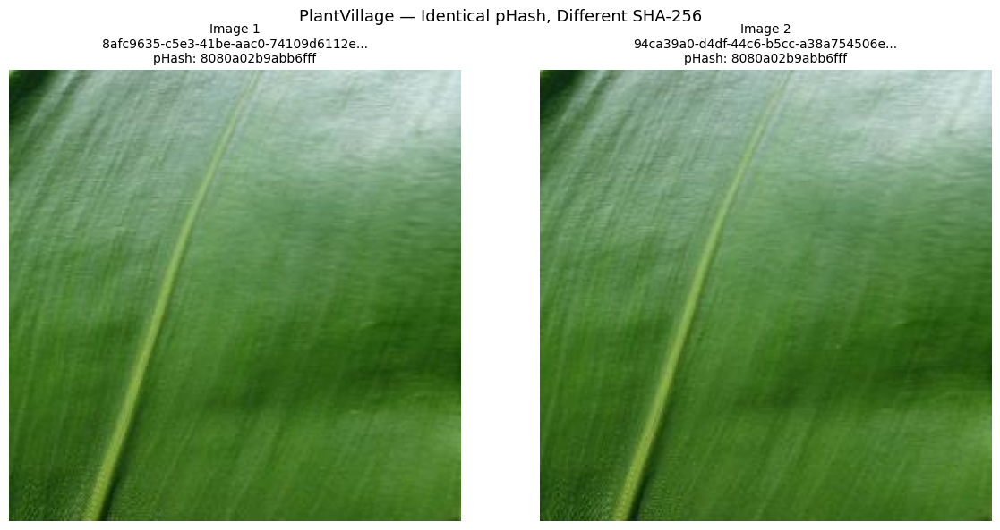


IMAGE DETAILS


,plantvillage_class,filepath,sha256,phash
0,Corn_(maize)___healthy,/kaggle/input/plantvillage-dataset/color/Corn_...,269adda16f0a1295747ebd5df39a844d7d241ad93153b9...,8080a02b9abb6fff
1,Corn_(maize)___healthy,/kaggle/input/plantvillage-dataset/color/Corn_...,fd1970bc26387e9e8f22ae75600b170290e012c961246d...,8080a02b9abb6fff


In [73]:
# Cell 81 — Visual inspection of perceptual-hash collision

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

collision_images = (
    pv_phash_collisions_df
    .sort_values("filepath")
    .reset_index(drop=True)
)

assert len(collision_images) == 2, (
    "Expected exactly two images in the collision group."
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for i, row in collision_images.iterrows():

    image_path = Path(row["filepath"])

    with Image.open(image_path) as img:
        image = img.convert("RGB").copy()

    axes[i].imshow(image)
    axes[i].axis("off")

    axes[i].set_title(
        f"Image {i + 1}\n"
        f"{image_path.name[:35]}...\n"
        f"pHash: {row['phash']}",
        fontsize=10
    )

plt.suptitle(
    "PlantVillage — Identical pHash, Different SHA-256",
    fontsize=13
)

plt.tight_layout()
plt.show()

print("\nIMAGE DETAILS")
display(
    collision_images[
        ["plantvillage_class", "filepath", "sha256", "phash"]
    ]
)

In [74]:
# Cell 82 — Validate perceptual hashes for near-duplicate screening

import pandas as pd

print("PLANTVILLAGE PHASH VALIDATION")
print("=" * 60)

phash_values = (
    pv_clean_inventory_df["phash"]
    .astype(str)
    .str.lower()
    .str.strip()
)

valid_format = phash_values.str.fullmatch(r"[0-9a-f]{16}")

print("Total images:", len(phash_values))
print("Valid 64-bit pHashes:", valid_format.sum())
print("Invalid pHashes:", (~valid_format).sum())

assert valid_format.all(), "Invalid pHash values detected."

# Convert hexadecimal hashes into integers
pv_phash_integers = [
    int(value, 16)
    for value in phash_values
]

print("Unique pHashes:", len(set(pv_phash_integers)))
print("Hash bit length: 64")

print("\nPASS: Perceptual hashes ready for similarity screening.")

PLANTVILLAGE PHASH VALIDATION
Total images: 54284
Valid 64-bit pHashes: 54284
Invalid pHashes: 0
Unique pHashes: 54283
Hash bit length: 64

PASS: Perceptual hashes ready for similarity screening.


In [75]:
# Cell 83 — Efficient near-duplicate candidate screening

from collections import defaultdict
import pandas as pd
import time

print("PLANTVILLAGE NEAR-DUPLICATE SCREENING")
print("=" * 60)

MAX_DISTANCE = 5

# BK-tree implementation for 64-bit perceptual hashes
class BKTree:
    def __init__(self):
        self.root = None

    @staticmethod
    def distance(a, b):
        return (a ^ b).bit_count()

    def add(self, value):
        if self.root is None:
            self.root = [value, {}]
            return

        node = self.root

        while True:
            distance = self.distance(value, node[0])

            if distance == 0:
                return

            if distance not in node[1]:
                node[1][distance] = [value, {}]
                return

            node = node[1][distance]

    def search(self, value, max_distance):
        results = []

        if self.root is None:
            return results

        stack = [self.root]

        while stack:
            node = stack.pop()

            distance = self.distance(value, node[0])

            if distance <= max_distance:
                results.append((node[0], distance))

            lower = distance - max_distance
            upper = distance + max_distance

            for edge_distance, child in node[1].items():
                if lower <= edge_distance <= upper:
                    stack.append(child)

        return results


# Group image indices by perceptual hash
hash_to_indices = defaultdict(list)

for idx, hash_value in enumerate(pv_phash_integers):
    hash_to_indices[hash_value].append(idx)

unique_hashes = list(hash_to_indices.keys())

print("Images:", len(pv_phash_integers))
print("Unique pHashes:", len(unique_hashes))
print("Maximum Hamming distance:", MAX_DISTANCE)

# Build the tree and search unique hash pairs
tree = BKTree()
candidate_records = []

start_time = time.time()

for hash_value in unique_hashes:

    matches = tree.search(hash_value, MAX_DISTANCE)

    for matched_hash, distance in matches:

        for idx_a in hash_to_indices[matched_hash]:
            for idx_b in hash_to_indices[hash_value]:

                candidate_records.append({
                    "index_a": idx_a,
                    "index_b": idx_b,
                    "hamming_distance": distance
                })

    # Add after searching to avoid matching the hash with itself
    tree.add(hash_value)

# Include different images sharing the same pHash
for hash_value, indices in hash_to_indices.items():
    if len(indices) > 1:
        for i in range(len(indices)):
            for j in range(i + 1, len(indices)):
                candidate_records.append({
                    "index_a": indices[i],
                    "index_b": indices[j],
                    "hamming_distance": 0
                })

pv_near_duplicate_candidates_df = pd.DataFrame(
    candidate_records,
    columns=["index_a", "index_b", "hamming_distance"]
)

elapsed = time.time() - start_time

print("\nSCREENING RESULTS")
print("-" * 60)

print("Candidate image pairs:", len(pv_near_duplicate_candidates_df))
print("Execution time (seconds):", round(elapsed, 2))

print("\nHAMMING DISTANCE DISTRIBUTION")

display(
    pv_near_duplicate_candidates_df["hamming_distance"]
    .value_counts()
    .sort_index()
    .rename_axis("hamming_distance")
    .reset_index(name="candidate_pairs")
)

print("\nVALIDATION")
print("-" * 60)

assert len(pv_phash_integers) == 54284

assert (
    pv_near_duplicate_candidates_df["hamming_distance"]
    .between(0, MAX_DISTANCE)
    .all()
)

assert (
    pv_near_duplicate_candidates_df["index_a"]
    != pv_near_duplicate_candidates_df["index_b"]
).all()

print("PASS: Near-duplicate candidate screening completed.")

PLANTVILLAGE NEAR-DUPLICATE SCREENING
Images: 54284
Unique pHashes: 54283
Maximum Hamming distance: 5

SCREENING RESULTS
------------------------------------------------------------
Candidate image pairs: 1455
Execution time (seconds): 102.23

HAMMING DISTANCE DISTRIBUTION


,hamming_distance,candidate_pairs
0,0,1
1,2,97
2,4,1357



VALIDATION
------------------------------------------------------------
PASS: Near-duplicate candidate screening completed.


In [76]:
# Cell 84 — Analyse near-duplicate candidate relationships

import pandas as pd

print("PLANTVILLAGE NEAR-DUPLICATE CANDIDATE ANALYSIS")
print("=" * 60)

# Create a working copy
pv_candidate_details_df = (
    pv_near_duplicate_candidates_df.copy()
)

# Retrieve image metadata for each pair
for suffix, index_col in [
    ("a", "index_a"),
    ("b", "index_b")
]:
    indices = pv_candidate_details_df[index_col]

    pv_candidate_details_df[f"filepath_{suffix}"] = (
        pv_clean_inventory_df.loc[indices, "filepath"]
        .to_numpy()
    )

    pv_candidate_details_df[f"class_{suffix}"] = (
        pv_clean_inventory_df.loc[
            indices, "plantvillage_class"
        ].to_numpy()
    )

    pv_candidate_details_df[f"sha256_{suffix}"] = (
        pv_clean_inventory_df.loc[indices, "sha256"]
        .to_numpy()
    )

# Check whether paired images belong to the same class
pv_candidate_details_df["same_class"] = (
    pv_candidate_details_df["class_a"]
    == pv_candidate_details_df["class_b"]
)

# Count unique images involved in candidate pairs
candidate_indices = set(
    pv_candidate_details_df["index_a"]
).union(
    pv_candidate_details_df["index_b"]
)

print("Total candidate pairs:", len(pv_candidate_details_df))
print("Distinct images involved:", len(candidate_indices))

print(
    "Same-class pairs:",
    pv_candidate_details_df["same_class"].sum()
)

print(
    "Cross-class pairs:",
    (~pv_candidate_details_df["same_class"]).sum()
)

print("\nCANDIDATE PAIRS BY HAMMING DISTANCE AND CLASS")
print("-" * 60)

display(
    pd.crosstab(
        pv_candidate_details_df["hamming_distance"],
        pv_candidate_details_df["same_class"],
        rownames=["Hamming distance"],
        colnames=["Same class"]
    )
)

print("\nTOP CLASSES INVOLVED IN SAME-CLASS PAIRS")
print("-" * 60)

display(
    pv_candidate_details_df[
        pv_candidate_details_df["same_class"]
    ]["class_a"]
    .value_counts()
    .head(15)
    .rename_axis("class_name")
    .reset_index(name="candidate_pairs")
)

print("\nCROSS-CLASS CANDIDATE EXAMPLES")
print("-" * 60)

display(
    pv_candidate_details_df[
        ~pv_candidate_details_df["same_class"]
    ][
        [
            "class_a",
            "class_b",
            "hamming_distance"
        ]
    ].head(20)
)

print("\nVALIDATION")
print("-" * 60)

assert len(pv_candidate_details_df) == 1455

assert (
    pv_candidate_details_df["sha256_a"]
    != pv_candidate_details_df["sha256_b"]
).all()

print("PASS: Candidate relationships analysed.")

PLANTVILLAGE NEAR-DUPLICATE CANDIDATE ANALYSIS
Total candidate pairs: 1455
Distinct images involved: 1712
Same-class pairs: 1145
Cross-class pairs: 310

CANDIDATE PAIRS BY HAMMING DISTANCE AND CLASS
------------------------------------------------------------


Same class,False,True
Hamming distance,,
0,0,1
2,7,90
4,303,1054



TOP CLASSES INVOLVED IN SAME-CLASS PAIRS
------------------------------------------------------------


,class_name,candidate_pairs
0,Soybean___healthy,952
1,Orange___Haunglongbing_(Citrus_greening),51
2,Tomato___Tomato_Yellow_Leaf_Curl_Virus,27
3,Raspberry___healthy,19
4,Cherry_(including_sour)___healthy,17
5,Cherry_(including_sour)___Powdery_mildew,15
6,"Pepper,_bell___healthy",11
7,Blueberry___healthy,8
8,Tomato___healthy,6
9,Tomato___Bacterial_spot,5



CROSS-CLASS CANDIDATE EXAMPLES
------------------------------------------------------------


,class_a,class_b,hamming_distance
1,Raspberry___healthy,Soybean___healthy,4
3,Soybean___healthy,Tomato___Bacterial_spot,4
6,Apple___healthy,Raspberry___healthy,4
14,Raspberry___healthy,Soybean___healthy,4
15,Soybean___healthy,Tomato___Bacterial_spot,4
17,Soybean___healthy,Raspberry___healthy,4
32,Orange___Haunglongbing_(Citrus_greening),Grape___Black_rot,4
37,Soybean___healthy,Tomato___Leaf_Mold,4
40,Raspberry___healthy,Soybean___healthy,2
44,"Pepper,_bell___healthy",Soybean___healthy,4



VALIDATION
------------------------------------------------------------
PASS: Candidate relationships analysed.


In [77]:
# Cell 85 — Summarise and save near-duplicate screening results

from pathlib import Path
import pandas as pd

print("PLANTVILLAGE NEAR-DUPLICATE SCREENING SUMMARY")
print("=" * 60)

total_pairs = len(pv_candidate_details_df)

same_class_pairs = int(
    pv_candidate_details_df["same_class"].sum()
)

cross_class_pairs = total_pairs - same_class_pairs

distinct_images = len(
    set(pv_candidate_details_df["index_a"])
    | set(pv_candidate_details_df["index_b"])
)

print("Total candidate pairs:", total_pairs)
print("Same-class pairs:", same_class_pairs)
print("Cross-class pairs:", cross_class_pairs)
print("Distinct images involved:", distinct_images)

print("\nDISTANCE BREAKDOWN")
display(
    pd.crosstab(
        pv_candidate_details_df["hamming_distance"],
        pv_candidate_details_df["same_class"]
    )
)

# Save results permanently
output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

output_dir.mkdir(parents=True, exist_ok=True)

candidate_file = output_dir / "near_duplicate_candidates.csv"
clean_inventory_file = output_dir / "deduplicated_inventory.csv"
exclusion_file = output_dir / "exact_duplicate_exclusions.csv"

pv_candidate_details_df.to_csv(candidate_file, index=False)
pv_clean_inventory_df.to_csv(clean_inventory_file, index=False)
pv_excluded_duplicates_df.to_csv(exclusion_file, index=False)

print("\nSAVED FILES")
print("-" * 60)

for path in [
    candidate_file,
    clean_inventory_file,
    exclusion_file
]:
    print(path.name, ":", path.is_file())

assert total_pairs == 1455
assert same_class_pairs + cross_class_pairs == total_pairs
assert len(pv_clean_inventory_df) == 54284
assert all(
    path.is_file()
    for path in [
        candidate_file,
        clean_inventory_file,
        exclusion_file
    ]
)

print("\nPASS: Screening results saved successfully.")

PLANTVILLAGE NEAR-DUPLICATE SCREENING SUMMARY
Total candidate pairs: 1455
Same-class pairs: 1145
Cross-class pairs: 310
Distinct images involved: 1712

DISTANCE BREAKDOWN


same_class,False,True
hamming_distance,,
0,0,1
2,7,90
4,303,1054



SAVED FILES
------------------------------------------------------------
near_duplicate_candidates.csv : True
deduplicated_inventory.csv : True
exact_duplicate_exclusions.csv : True

PASS: Screening results saved successfully.


CLOSEST CANDIDATE VISUAL REVIEW
Pairs selected: 12


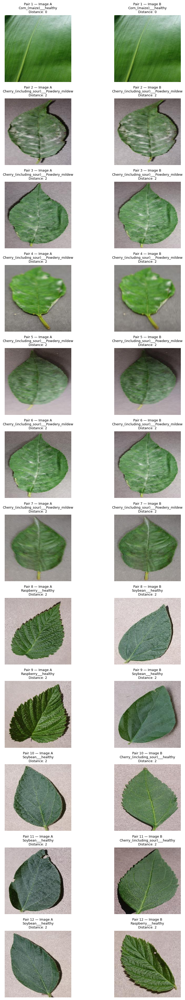


REVIEW PAIR DETAILS


,class_a,class_b,hamming_distance,same_class
0,Corn_(maize)___healthy,Corn_(maize)___healthy,0,True
1,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___Powdery_mildew,2,True
2,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___Powdery_mildew,2,True
3,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___Powdery_mildew,2,True
4,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___Powdery_mildew,2,True
5,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___Powdery_mildew,2,True
6,Cherry_(including_sour)___Powdery_mildew,Cherry_(including_sour)___Powdery_mildew,2,True
7,Raspberry___healthy,Soybean___healthy,2,False
8,Raspberry___healthy,Soybean___healthy,2,False
9,Soybean___healthy,Cherry_(including_sour)___healthy,2,False


In [78]:
# Cell 86 — Visual review of closest near-duplicate candidates

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import pandas as pd

# Select the known distance-0 pair
distance_0 = pv_candidate_details_df[
    pv_candidate_details_df["hamming_distance"] == 0
]

# Select same-class distance-2 pairs
same_class_d2 = pv_candidate_details_df[
    (pv_candidate_details_df["hamming_distance"] == 2)
    & (pv_candidate_details_df["same_class"])
].sort_values(["class_a", "filepath_a", "filepath_b"]).head(6)

# Select cross-class distance-2 pairs
cross_class_d2 = pv_candidate_details_df[
    (pv_candidate_details_df["hamming_distance"] == 2)
    & (~pv_candidate_details_df["same_class"])
].sort_values(["class_a", "class_b", "filepath_a"]).head(5)

review_df = pd.concat(
    [distance_0, same_class_d2, cross_class_d2],
    ignore_index=True
)

print("CLOSEST CANDIDATE VISUAL REVIEW")
print("=" * 60)
print("Pairs selected:", len(review_df))

fig, axes = plt.subplots(
    len(review_df), 2,
    figsize=(10, len(review_df) * 3.2)
)

for i, row in review_df.iterrows():

    for j, suffix in enumerate(["a", "b"]):

        image_path = Path(row[f"filepath_{suffix}"])

        with Image.open(image_path) as img:
            image = img.convert("RGB").copy()

        axes[i, j].imshow(image)
        axes[i, j].axis("off")

        axes[i, j].set_title(
            f"Pair {i + 1} — Image {suffix.upper()}\n"
            f"{row[f'class_{suffix}']}\n"
            f"Distance: {row['hamming_distance']}",
            fontsize=9
        )

plt.tight_layout()
plt.show()

print("\nREVIEW PAIR DETAILS")
display(
    review_df[
        [
            "class_a",
            "class_b",
            "hamming_distance",
            "same_class"
        ]
    ]
)

In [4]:
# Cell 87 — Identify connected groups of closest same-class candidates

from collections import defaultdict, Counter
import pandas as pd

closest_same_class_df = pv_candidate_details_df[
    (pv_candidate_details_df["same_class"])
    & (pv_candidate_details_df["hamming_distance"] <= 2)
].copy()

parent = {}

def find(x):
    parent.setdefault(x, x)

    if parent[x] != x:
        parent[x] = find(parent[x])

    return parent[x]

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a

for row in closest_same_class_df.itertuples():
    union(row.index_a, row.index_b)

groups = defaultdict(list)

for image_index in parent:
    groups[find(image_index)].append(image_index)

group_records = []

for group_id, indices in enumerate(
    sorted(groups.values(), key=lambda x: min(x)),
    start=1
):
    classes = pv_clean_inventory_df.loc[
        indices, "plantvillage_class"
    ].unique()

    group_records.append({
        "group_id": group_id,
        "image_count": len(indices),
        "class_name": classes[0],
        "image_indices": sorted(indices)
    })

pv_close_groups_df = pd.DataFrame(group_records)

print("CLOSEST SAME-CLASS CANDIDATE GROUPS")
print("=" * 60)

print("Candidate pairs:", len(closest_same_class_df))
print("Connected groups:", len(pv_close_groups_df))
print(
    "Distinct images involved:",
    pv_close_groups_df["image_count"].sum()
)

print("\nGROUP SIZE DISTRIBUTION")
display(
    pv_close_groups_df["image_count"]
    .value_counts()
    .sort_index()
    .rename_axis("group_size")
    .reset_index(name="number_of_groups")
)

print("\nLARGEST GROUPS")
display(
    pv_close_groups_df[
        ["group_id", "image_count", "class_name"]
    ]
    .sort_values("image_count", ascending=False)
    .head(15)
)

print("\nVALIDATION")
assert len(closest_same_class_df) == 91
assert all(
    len(indices) >= 2
    for indices in pv_close_groups_df["image_indices"]
)
assert pv_close_groups_df["image_count"].sum() == len(parent)

print("PASS: Candidate groups identified.")

CLOSEST SAME-CLASS CANDIDATE GROUPS
Candidate pairs: 91
Connected groups: 85
Distinct images involved: 176

GROUP SIZE DISTRIBUTION


,group_size,number_of_groups
0,2,81
1,3,3
2,5,1



LARGEST GROUPS


,group_id,image_count,class_name
29,30,5,Soybean___healthy
41,42,3,Soybean___healthy
56,57,3,Soybean___healthy
20,21,3,Cherry_(including_sour)___Powdery_mildew
1,2,2,Soybean___healthy
4,5,2,Orange___Haunglongbing_(Citrus_greening)
5,6,2,Soybean___healthy
7,8,2,Cherry_(including_sour)___Powdery_mildew
6,7,2,Soybean___healthy
9,10,2,Soybean___healthy



VALIDATION
PASS: Candidate groups identified.


In [3]:
# Runtime Recovery — Restore variables required for Cell 87

import pandas as pd
from pathlib import Path

# Location of saved PlantVillage results
pv_output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

# Restore previously saved dataframes
pv_candidate_details_df = pd.read_csv(
    pv_output_dir / "near_duplicate_candidates.csv"
)

pv_clean_inventory_df = pd.read_csv(
    pv_output_dir / "deduplicated_inventory.csv"
)

pv_excluded_duplicates_df = pd.read_csv(
    pv_output_dir / "exact_duplicate_exclusions.csv"
)

print("RUNTIME RECOVERY")
print("=" * 60)

print("Candidate pairs:", len(pv_candidate_details_df))
print("Clean inventory:", len(pv_clean_inventory_df))
print("Exact duplicate exclusions:", len(pv_excluded_duplicates_df))

print("\nVALIDATION")
print("-" * 60)

assert len(pv_candidate_details_df) == 1455
assert len(pv_clean_inventory_df) == 54284
assert len(pv_excluded_duplicates_df) == 21

print("PASS: Required dataframes restored successfully.")

RUNTIME RECOVERY
Candidate pairs: 1455
Clean inventory: 54284
Exact duplicate exclusions: 21

VALIDATION
------------------------------------------------------------
PASS: Required dataframes restored successfully.


Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
LARGER NEAR-DUPLICATE CANDIDATE GROUPS
Groups to review: 4


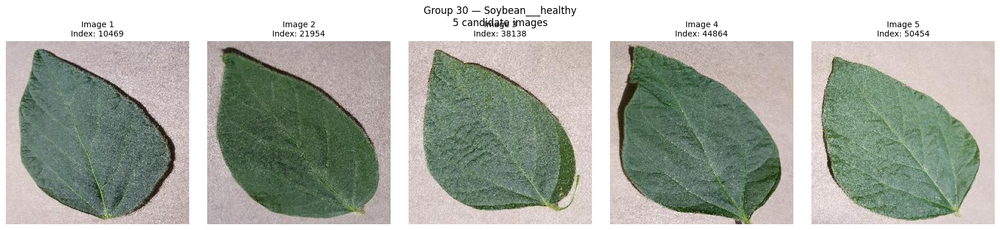

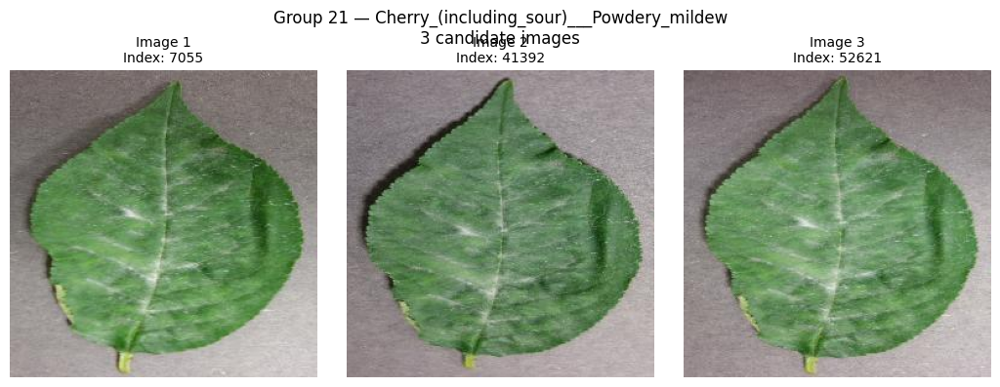

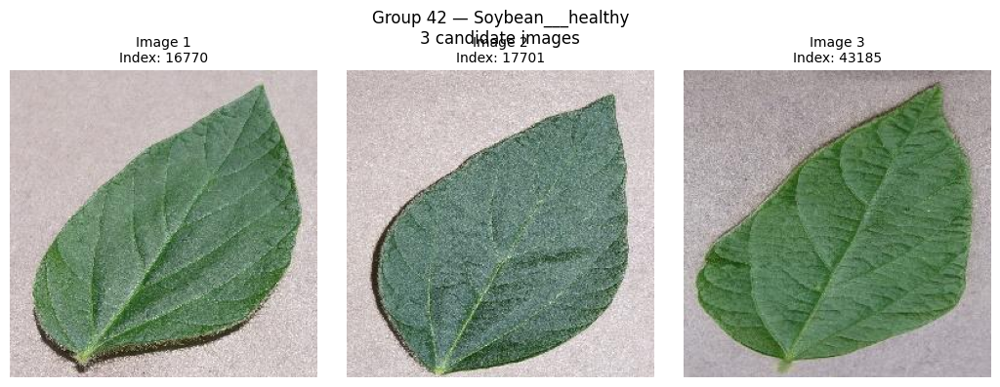

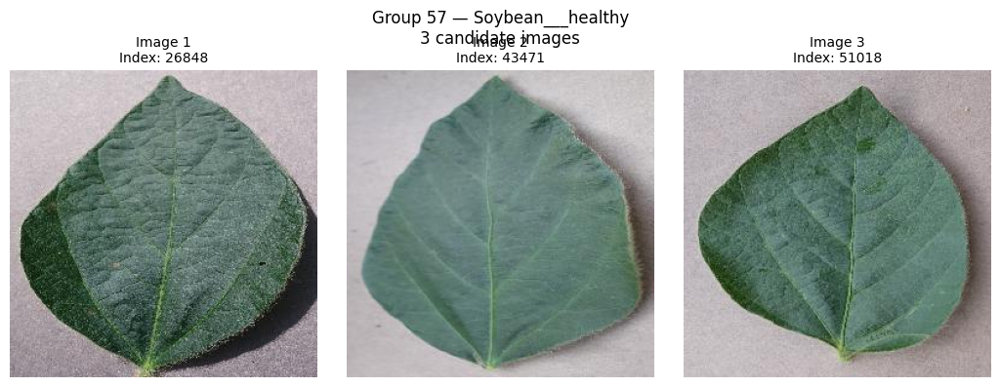

In [5]:
# Cell 88 — Visual inspection of larger near-duplicate candidate groups

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import kagglehub

# Restore current PlantVillage location if necessary
pv_root = Path(
    kagglehub.dataset_download(
        "aftaabahmedshaik/plantvillage-dataset"
    )
)

pv_dir = pv_root / "color"

assert pv_dir.is_dir(), "PlantVillage colour directory not found."

# Select groups containing more than two images
large_groups_df = (
    pv_close_groups_df[
        pv_close_groups_df["image_count"] > 2
    ]
    .sort_values(
        ["image_count", "group_id"],
        ascending=[False, True]
    )
)

print("LARGER NEAR-DUPLICATE CANDIDATE GROUPS")
print("=" * 60)
print("Groups to review:", len(large_groups_df))

for row in large_groups_df.itertuples():

    indices = row.image_indices
    n_images = len(indices)

    fig, axes = plt.subplots(
        1, n_images,
        figsize=(3.5 * n_images, 4)
    )

    for position, image_index in enumerate(indices):

        image_record = pv_clean_inventory_df.iloc[image_index]

        old_path = Path(image_record["filepath"])

        image_path = (
            pv_dir
            / image_record["plantvillage_class"]
            / old_path.name
        )

        assert image_path.is_file(), (
            f"Missing image: {image_path}"
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB").copy()

        axes[position].imshow(image)
        axes[position].axis("off")
        axes[position].set_title(
            f"Image {position + 1}\n"
            f"Index: {image_index}",
            fontsize=10
        )

    fig.suptitle(
        f"Group {row.group_id} — {row.class_name}\n"
        f"{n_images} candidate images",
        fontsize=12
    )

    plt.tight_layout()
    plt.show()

TWO-IMAGE CANDIDATE REVIEW
Total two-image groups: 81
Current batch: 1
Groups in batch: 12


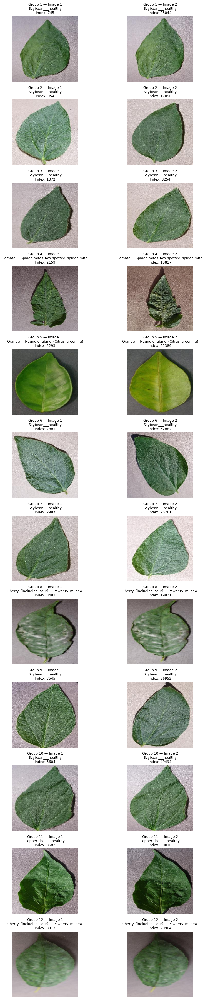

In [6]:
# Cell 89 — Review two-image candidate groups (Batch 1)

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Select groups containing exactly two images
two_image_groups_df = (
    pv_close_groups_df[
        pv_close_groups_df["image_count"] == 2
    ]
    .sort_values("group_id")
    .reset_index(drop=True)
)

BATCH_SIZE = 12
BATCH_NUMBER = 1

start = (BATCH_NUMBER - 1) * BATCH_SIZE
end = start + BATCH_SIZE

batch_df = two_image_groups_df.iloc[start:end]

print("TWO-IMAGE CANDIDATE REVIEW")
print("=" * 60)
print("Total two-image groups:", len(two_image_groups_df))
print("Current batch:", BATCH_NUMBER)
print("Groups in batch:", len(batch_df))

fig, axes = plt.subplots(
    len(batch_df), 2,
    figsize=(10, len(batch_df) * 3)
)

for row_position, group in enumerate(batch_df.itertuples()):

    for image_position, image_index in enumerate(group.image_indices):

        record = pv_clean_inventory_df.iloc[image_index]

        image_path = (
            pv_dir
            / record["plantvillage_class"]
            / Path(record["filepath"]).name
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB").copy()

        axes[row_position, image_position].imshow(image)
        axes[row_position, image_position].axis("off")

        axes[row_position, image_position].set_title(
            f"Group {group.group_id} — Image {image_position + 1}\n"
            f"{group.class_name}\n"
            f"Index: {image_index}",
            fontsize=9
        )

plt.tight_layout()
plt.show()

In [7]:
# Cell 90 — Create near-duplicate visual review log

import pandas as pd

review_decisions = {
    1: ("probable_duplicate", "Same leaf features and framing"),
    2: ("distinct", "Different leaf structures"),
    3: ("distinct", "Different leaf structures"),
    4: ("distinct", "Visibly different leaf appearance"),
    5: ("uncertain", "Similar outline; source relationship unclear"),
    6: ("distinct", "Different vein patterns"),
    7: ("distinct", "Different leaf appearance"),
    8: ("probable_duplicate", "Matching leaf and disease patterns"),
    9: ("distinct", "Different leaf structures"),
    10: ("probable_duplicate", "Matching leaf structure and framing"),
    11: ("probable_duplicate", "Matching leaf folds and shadows"),
    12: ("probable_duplicate", "Matching leaf and background"),

    # Groups inspected in Cell 88
    21: ("same_source_group", "Three visually near-identical cherry images"),
    30: ("distinct", "Five visually different soybean leaves"),
    42: ("distinct", "Three visually different soybean leaves"),
    57: ("distinct", "Three visually different soybean leaves"),
}

review_records = []

for group_id, (decision, notes) in review_decisions.items():

    group = pv_close_groups_df.loc[
        pv_close_groups_df["group_id"] == group_id
    ].iloc[0]

    review_records.append({
        "group_id": group_id,
        "class_name": group["class_name"],
        "image_count": group["image_count"],
        "decision": decision,
        "review_notes": notes
    })

pv_visual_review_log_df = pd.DataFrame(
    review_records
).sort_values("group_id").reset_index(drop=True)

print("PLANTVILLAGE VISUAL REVIEW LOG")
print("=" * 60)

print("Groups reviewed:", len(pv_visual_review_log_df))

print("\nDECISION DISTRIBUTION")
display(
    pv_visual_review_log_df["decision"].value_counts()
)

print("\nREVIEW RECORDS")
display(pv_visual_review_log_df)

assert pv_visual_review_log_df["group_id"].is_unique
assert len(pv_visual_review_log_df) == 16

print("\nPASS: Visual review decisions recorded.")

PLANTVILLAGE VISUAL REVIEW LOG
Groups reviewed: 16

DECISION DISTRIBUTION


,count
decision,
distinct,9
probable_duplicate,5
uncertain,1
same_source_group,1



REVIEW RECORDS


,group_id,class_name,image_count,decision,review_notes
0,1,Soybean___healthy,2,probable_duplicate,Same leaf features and framing
1,2,Soybean___healthy,2,distinct,Different leaf structures
2,3,Soybean___healthy,2,distinct,Different leaf structures
3,4,Tomato___Spider_mites Two-spotted_spider_mite,2,distinct,Visibly different leaf appearance
4,5,Orange___Haunglongbing_(Citrus_greening),2,uncertain,Similar outline; source relationship unclear
5,6,Soybean___healthy,2,distinct,Different vein patterns
6,7,Soybean___healthy,2,distinct,Different leaf appearance
7,8,Cherry_(including_sour)___Powdery_mildew,2,probable_duplicate,Matching leaf and disease patterns
8,9,Soybean___healthy,2,distinct,Different leaf structures
9,10,Soybean___healthy,2,probable_duplicate,Matching leaf structure and framing



PASS: Visual review decisions recorded.


In [8]:
# Cell 91 — Save visual review decisions and group membership

from pathlib import Path
import pandas as pd

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

output_dir.mkdir(parents=True, exist_ok=True)

review_log_file = output_dir / "visual_review_log.csv"
membership_file = output_dir / "visual_review_group_members.csv"

# Create image-level membership records
membership_records = []

for group in pv_visual_review_log_df.itertuples():

    matching_group = pv_close_groups_df.loc[
        pv_close_groups_df["group_id"] == group.group_id
    ].iloc[0]

    for image_index in matching_group["image_indices"]:

        image_record = pv_clean_inventory_df.iloc[image_index]

        membership_records.append({
            "group_id": group.group_id,
            "image_index": image_index,
            "plantvillage_class": image_record["plantvillage_class"],
            "filepath": image_record["filepath"],
            "sha256": image_record["sha256"],
            "phash": image_record["phash"],
            "review_decision": group.decision
        })

pv_review_members_df = pd.DataFrame(membership_records)

# Save records
pv_visual_review_log_df.to_csv(review_log_file, index=False)
pv_review_members_df.to_csv(membership_file, index=False)

print("PLANTVILLAGE VISUAL REVIEW RECORDS")
print("=" * 60)

print("Reviewed groups:", len(pv_visual_review_log_df))
print("Image membership records:", len(pv_review_members_df))

print("\nSAVED FILES")
print("Review log:", review_log_file)
print("Group membership:", membership_file)

print("\nVALIDATION")

assert review_log_file.is_file()
assert membership_file.is_file()

assert pv_review_members_df["sha256"].notna().all()

assert (
    pv_review_members_df.groupby("group_id").size()
    .sort_index()
    .equals(
        pv_visual_review_log_df
        .set_index("group_id")["image_count"]
        .sort_index()
        .rename(None)
    )
)

print("PASS: Review records saved successfully.")

PLANTVILLAGE VISUAL REVIEW RECORDS
Reviewed groups: 16
Image membership records: 38

SAVED FILES
Review log: /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/visual_review_log.csv
Group membership: /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/visual_review_group_members.csv

VALIDATION
PASS: Review records saved successfully.


In [9]:
# Cell 92 — Validate review records against clean inventory

print("PLANTVILLAGE REVIEW-TO-INVENTORY VALIDATION")
print("=" * 60)

clean_hashes = set(pv_clean_inventory_df["sha256"])
review_hashes = set(pv_review_members_df["sha256"])

missing_hashes = review_hashes - clean_hashes

duplicate_memberships = (
    pv_review_members_df["sha256"].duplicated().sum()
)

print("Clean inventory images:", len(pv_clean_inventory_df))
print("Reviewed image records:", len(pv_review_members_df))
print("Unique reviewed images:", len(review_hashes))
print("Missing inventory matches:", len(missing_hashes))
print("Duplicate review memberships:", duplicate_memberships)

print("\nREVIEW DECISIONS")
display(
    pv_review_members_df.groupby("review_decision")
    .agg(
        image_records=("sha256", "size"),
        unique_images=("sha256", "nunique"),
        groups=("group_id", "nunique")
    )
)

print("\nVALIDATION")
assert len(missing_hashes) == 0
assert duplicate_memberships == 0
assert pv_clean_inventory_df["sha256"].is_unique

print("PASS: Reviewed images match the clean inventory.")

PLANTVILLAGE REVIEW-TO-INVENTORY VALIDATION
Clean inventory images: 54284
Reviewed image records: 38
Unique reviewed images: 38
Missing inventory matches: 0
Duplicate review memberships: 0

REVIEW DECISIONS


,image_records,unique_images,groups
review_decision,,,
distinct,23,23,9
probable_duplicate,10,10,5
same_source_group,3,3,1
uncertain,2,2,1



VALIDATION
PASS: Reviewed images match the clean inventory.


In [10]:
# Cell 93 — Construct leakage-mitigation grouping constraints

import pandas as pd

print("PLANTVILLAGE SPLIT GROUP PREPARATION")
print("=" * 60)

# Start with one group per unique image
pv_split_inventory_df = pv_clean_inventory_df.copy()

pv_split_inventory_df["split_group_id"] = (
    "individual_" + pv_split_inventory_df["sha256"]
)

# Select groups visually assessed as related photographs
related_decisions = {
    "probable_duplicate",
    "same_source_group"
}

related_groups = pv_visual_review_log_df[
    pv_visual_review_log_df["decision"].isin(
        related_decisions
    )
]

# Assign shared group IDs to related images
for group in related_groups.itertuples():

    member_hashes = pv_review_members_df.loc[
        pv_review_members_df["group_id"] == group.group_id,
        "sha256"
    ].tolist()

    # Stable identifier based on the member hashes
    representative_hash = min(member_hashes)

    shared_group_id = "related_" + representative_hash

    pv_split_inventory_df.loc[
        pv_split_inventory_df["sha256"].isin(member_hashes),
        "split_group_id"
    ] = shared_group_id

print("Images:", len(pv_split_inventory_df))
print(
    "Unique split groups:",
    pv_split_inventory_df["split_group_id"].nunique()
)

print(
    "Visually related groups:",
    len(related_groups)
)

print("\nGROUP SIZE DISTRIBUTION")
display(
    pv_split_inventory_df.groupby("split_group_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("group_size")
    .reset_index(name="number_of_groups")
)

print("\nVALIDATION")
print("-" * 60)

assert len(pv_split_inventory_df) == 54284
assert pv_split_inventory_df["sha256"].is_unique
assert pv_split_inventory_df["split_group_id"].notna().all()

# Ensure every group contains only one class
assert (
    pv_split_inventory_df.groupby("split_group_id")[
        "plantvillage_class"
    ].nunique().max()
    == 1
)

print("PASS: Split grouping constraints prepared.")

PLANTVILLAGE SPLIT GROUP PREPARATION
Images: 54284
Unique split groups: 54277
Visually related groups: 6

GROUP SIZE DISTRIBUTION


,group_size,number_of_groups
0,1,54271
1,2,5
2,3,1



VALIDATION
------------------------------------------------------------
PASS: Split grouping constraints prepared.


In [11]:
# Cell 94 — Save PlantVillage split grouping inventory

from pathlib import Path
import pandas as pd

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

output_dir.mkdir(parents=True, exist_ok=True)

grouping_file = output_dir / "split_grouping_inventory.csv"

pv_split_inventory_df.to_csv(
    grouping_file,
    index=False
)

print("PLANTVILLAGE SPLIT GROUPING INVENTORY")
print("=" * 60)

print("Saved file:", grouping_file)

# Reload to verify saved content
saved_df = pd.read_csv(grouping_file)

print("\nVALIDATION")
print("-" * 60)

print("Saved image records:", len(saved_df))
print("Saved split groups:", saved_df["split_group_id"].nunique())
print("Classes represented:", saved_df["plantvillage_class"].nunique())

assert len(saved_df) == 54284
assert saved_df["split_group_id"].nunique() == 54277
assert saved_df["plantvillage_class"].nunique() == 38
assert saved_df["sha256"].is_unique

print("\nPASS: Grouping inventory saved and verified.")

PLANTVILLAGE SPLIT GROUPING INVENTORY
Saved file: /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/split_grouping_inventory.csv

VALIDATION
------------------------------------------------------------
Saved image records: 54284
Saved split groups: 54277
Classes represented: 38

PASS: Grouping inventory saved and verified.


In [12]:
# Cell 95 — Generate leakage-mitigated PlantVillage splits

import numpy as np
import pandas as pd
from pathlib import Path

SEED = 42
RATIOS = {"train": 0.70, "validation": 0.15, "test": 0.15}

rng = np.random.default_rng(SEED)

df = pv_split_inventory_df.copy()

# Group-level inventory
groups = (
    df.groupby(["plantvillage_class", "split_group_id"])
    .size()
    .reset_index(name="group_size")
)

assignments = []

for class_name, class_groups in groups.groupby(
    "plantvillage_class", sort=True
):
    class_groups = class_groups.sample(
        frac=1,
        random_state=SEED
    ).copy()

    total = int(class_groups["group_size"].sum())

    targets = {
        split: total * ratio
        for split, ratio in RATIOS.items()
    }

    counts = {split: 0 for split in RATIOS}

    for row in class_groups.itertuples():

        # Allocate to the split with the greatest remaining
        # proportional need, keeping each group intact.
        split = max(
            RATIOS,
            key=lambda s: (
                targets[s] - counts[s]
            ) / targets[s]
        )

        assignments.append({
            "split_group_id": row.split_group_id,
            "split": split
        })

        counts[split] += row.group_size

assignment_df = pd.DataFrame(assignments)

pv_final_split_df = df.merge(
    assignment_df,
    on="split_group_id",
    how="left",
    validate="many_to_one"
)

# Validation
assert len(pv_final_split_df) == 54284
assert pv_final_split_df["split"].notna().all()
assert pv_final_split_df["sha256"].is_unique

assert (
    pv_final_split_df.groupby("split_group_id")[
        "split"
    ].nunique().max() == 1
)

assert (
    pv_final_split_df.groupby("plantvillage_class")[
        "split"
    ].nunique().min() == 3
)

print("PLANTVILLAGE FINAL SPLIT SUMMARY")
print("=" * 60)

summary = (
    pv_final_split_df["split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .rename_axis("split")
    .reset_index(name="images")
)

summary["percentage"] = (
    summary["images"] / len(pv_final_split_df) * 100
).round(2)

display(summary)

print("\nCLASS DISTRIBUTION BY SPLIT")

class_split_table = pd.crosstab(
    pv_final_split_df["plantvillage_class"],
    pv_final_split_df["split"]
)

display(class_split_table)

# Save to Google Drive
output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

output_dir.mkdir(parents=True, exist_ok=True)

pv_final_split_df.to_csv(
    output_dir / "final_split_manifest.csv",
    index=False
)

class_split_table.to_csv(
    output_dir / "class_split_distribution.csv"
)

summary.to_csv(
    output_dir / "split_summary.csv",
    index=False
)

print("\nVALIDATION")
print("Unique images:", pv_final_split_df["sha256"].nunique())
print("Group leakage: 0")
print("Classes represented in all splits: 38")
print("Saved split manifests to Google Drive.")
print("\nPASS: Dataset splitting completed.")

PLANTVILLAGE FINAL SPLIT SUMMARY


,split,images,percentage
0,train,37978,69.96
1,validation,8155,15.02
2,test,8151,15.02



CLASS DISTRIBUTION BY SPLIT


split,test,train,validation
plantvillage_class,,,
Apple___Apple_scab,95,440,95
Apple___Black_rot,93,435,93
Apple___Cedar_apple_rust,41,192,42
Apple___healthy,246,1146,246
Blueberry___healthy,226,1050,226
Cherry_(including_sour)___Powdery_mildew,158,736,158
Cherry_(including_sour)___healthy,128,598,128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,77,359,77
Corn_(maize)___Common_rust_,179,834,179



VALIDATION
Unique images: 54284
Group leakage: 0
Classes represented in all splits: 38
Saved split manifests to Google Drive.

PASS: Dataset splitting completed.


In [13]:
# Cell 96 — Final split integrity audit

import pandas as pd
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

manifest = pd.read_csv(output_dir / "final_split_manifest.csv")
grouping = pd.read_csv(output_dir / "split_grouping_inventory.csv")

print("FINAL SPLIT INTEGRITY AUDIT")
print("=" * 60)

# Check image inventory matches the original grouping inventory
assert len(manifest) == len(grouping) == 54284
assert set(manifest["sha256"]) == set(grouping["sha256"])

# No image appears in multiple splits
assert manifest["sha256"].is_unique

# No identified related-image group crosses splits
group_leakage = (
    manifest.groupby("split_group_id")["split"]
    .nunique()
    .gt(1)
    .sum()
)

# Every class appears in all three splits
class_counts = pd.crosstab(
    manifest["plantvillage_class"],
    manifest["split"]
)

assert (class_counts > 0).all().all()
assert len(class_counts) == 38
assert group_leakage == 0

# Check actual class-level proportions
class_proportions = class_counts.div(
    class_counts.sum(axis=1), axis=0
)

target = {
    "train": 0.70,
    "validation": 0.15,
    "test": 0.15
}

max_deviation = max(
    (class_proportions[split] - ratio).abs().max()
    for split, ratio in target.items()
)

print("Total images:", len(manifest))
print("Classes:", len(class_counts))
print("Duplicate SHA-256 records:", manifest["sha256"].duplicated().sum())
print("Identified groups crossing splits:", group_leakage)
print("Maximum class-level proportion deviation:",
      f"{max_deviation * 100:.2f} percentage points")

assert max_deviation < 0.02

print("\nPASS: Saved split manifests passed integrity checks.")

FINAL SPLIT INTEGRITY AUDIT
Total images: 54284
Classes: 38
Duplicate SHA-256 records: 0
Identified groups crossing splits: 0
Maximum class-level proportion deviation: 0.27 percentage points

PASS: Saved split manifests passed integrity checks.


TASK 2.9 - PREPROCESSING, AUGMENTATION, CLASS IMBALANCE STRATEGY

In [14]:
# Cell 97 — Save AgroVision preprocessing and augmentation plan

import json
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

output_dir.mkdir(parents=True, exist_ok=True)

preprocessing_plan = {
    "project": "AgroVision FYP2",
    "random_seed": 42,
    "input_image_size": [160, 160],
    "colour_mode": "RGB",
    "image_conversion": "Convert RGBA or other modes to RGB",
    "resizing": "Resize images to 160x160 during loading",
    "model_specific_preprocessing": (
        "tf.keras.applications.resnet50.preprocess_input"
    ),
    "preprocessing_application": (
        "Apply exactly once; avoid incompatible double normalisation"
    ),
    "augmentation": {
        "training_only": True,
        "random_flip": "horizontal_and_vertical",
        "random_rotation_factor": 0.05,
        "random_zoom_factor": 0.10,
        "random_contrast_factor": 0.10
    },
    "validation_augmentation": False,
    "test_augmentation": False,
    "class_imbalance_strategy": (
        "Compute class weights from training subset only"
    ),
    "split_ratios": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    },
    "status": "Planned configuration; model training not started"
}

config_path = output_dir / "preprocessing_augmentation_plan.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(preprocessing_plan, f, indent=4)

with open(config_path, "r", encoding="utf-8") as f:
    verified_plan = json.load(f)

assert verified_plan == preprocessing_plan

print("PREPROCESSING AND AUGMENTATION PLAN")
print("=" * 60)

print("Input size:", preprocessing_plan["input_image_size"])
print("Colour mode:", preprocessing_plan["colour_mode"])
print("Augmentation: Training only")
print("Class weighting: Training only")
print("Model training: Not started")

print("\nSaved:", config_path)
print("\nPASS: Configuration saved and verified.")

PREPROCESSING AND AUGMENTATION PLAN
Input size: [160, 160]
Colour mode: RGB
Augmentation: Training only
Class weighting: Training only
Model training: Not started

Saved: /content/drive/MyDrive/AgroVision_FYP2/plantvillage_preparation/preprocessing_augmentation_plan.json

PASS: Configuration saved and verified.


In [15]:
# Cell 98 — Calculate and save training-only class weights

import json
import numpy as np
import pandas as pd
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/AgroVision_FYP2/"
    "plantvillage_preparation"
)

manifest = pd.read_csv(output_dir / "final_split_manifest.csv")

train_df = manifest.loc[
    manifest["split"] == "train"
].copy()

# Deterministic alphabetical class-to-index mapping
class_names = sorted(manifest["plantvillage_class"].unique())

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

train_counts = (
    train_df["plantvillage_class"]
    .value_counts()
    .reindex(class_names)
)

assert train_counts.notna().all()
assert (train_counts > 0).all()

num_train = len(train_df)
num_classes = len(class_names)

class_weights = {
    class_to_index[class_name]: float(
        num_train / (num_classes * train_counts[class_name])
    )
    for class_name in class_names
}

weights_df = pd.DataFrame({
    "class_index": range(num_classes),
    "class_name": class_names,
    "training_images": train_counts.to_numpy(),
    "class_weight": [
        class_weights[i] for i in range(num_classes)
    ]
})

# Save all mappings for reproducibility
weights_df.to_csv(
    output_dir / "training_class_weights.csv",
    index=False
)

with open(
    output_dir / "class_to_index.json", "w", encoding="utf-8"
) as f:
    json.dump(class_to_index, f, indent=4)

with open(
    output_dir / "class_weights.json", "w", encoding="utf-8"
) as f:
    json.dump(class_weights, f, indent=4)

print("TRAINING-ONLY CLASS WEIGHTS")
print("=" * 60)

print("Training images:", num_train)
print("Classes:", num_classes)

print("\nHIGHEST CLASS WEIGHTS")
display(
    weights_df.sort_values(
        "class_weight", ascending=False
    ).head(5)
)

print("\nLOWEST CLASS WEIGHTS")
display(
    weights_df.sort_values(
        "class_weight", ascending=True
    ).head(5)
)

# Validation
assert num_train == 37978
assert num_classes == 38
assert len(class_weights) == 38
assert np.isfinite(weights_df["class_weight"]).all()
assert (weights_df["class_weight"] > 0).all()

weighted_mean = np.average(
    weights_df["class_weight"],
    weights=weights_df["training_images"]
)

assert np.isclose(weighted_mean, 1.0)

print("\nWeighted mean class weight:", round(weighted_mean, 6))
print("Saved class weights and label mappings to Google Drive.")
print("\nPASS: Training-only class weights calculated.")

TRAINING-ONLY CLASS WEIGHTS
Training images: 37978
Classes: 38

HIGHEST CLASS WEIGHTS


,class_index,class_name,training_images,class_weight
22,22,Potato___healthy,106,9.428500
2,2,Apple___Cedar_apple_rust,192,5.205318
17,17,Peach___healthy,252,3.965957
23,23,Raspberry___healthy,259,3.858769
36,36,Tomato___Tomato_mosaic_virus,261,3.829199



LOWEST CLASS WEIGHTS


,class_index,class_name,training_images,class_weight
15,15,Orange___Haunglongbing_(Citrus_greening),3855,0.259253
35,35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,3749,0.266583
24,24,Soybean___healthy,3562,0.280579
16,16,Peach___Bacterial_spot,1607,0.621917
28,28,Tomato___Bacterial_spot,1489,0.671203



Weighted mean class weight: 1.0
Saved class weights and label mappings to Google Drive.

PASS: Training-only class weights calculated.


In [17]:
# Cell 99 — Final Phase 2 deliverables verification

from pathlib import Path
import pandas as pd
import json

base = Path("/content/drive/MyDrive/AgroVision_FYP2")
pv = base / "plantvillage_preparation"

required_files = {
    "PlantVillage clean inventory": pv / "deduplicated_inventory.csv",
    "Exact duplicate exclusions": pv / "exact_duplicate_exclusions.csv",
    "Near-duplicate candidates": pv / "near_duplicate_candidates.csv",
    "Visual review log": pv / "visual_review_log.csv",
    "Split grouping inventory": pv / "split_grouping_inventory.csv",
    "Final split manifest": pv / "final_split_manifest.csv",
    "Class split distribution": pv / "class_split_distribution.csv",
    "Split summary": pv / "split_summary.csv",
    "Preprocessing plan": pv / "preprocessing_augmentation_plan.json",
    "Training class weights": pv / "training_class_weights.csv",
    "Class-to-index mapping": pv / "class_to_index.json",
    "Class weights JSON": pv / "class_weights.json",
    "PlantDoc test inventory": (
        base / "plantdoc_preparation" / "plantdoc_test_inventory.csv"
    ),
    "FieldPlant crop inventory": (
        base / "fieldplant_preparation" / "fieldplant_crop_inventory.csv"
    )
}

checks = pd.DataFrame([
    {
        "deliverable": name,
        "exists": path.is_file(),
        "file_size_bytes": path.stat().st_size if path.is_file() else 0
    }
    for name, path in required_files.items()
])

display(checks)

missing = checks.loc[~checks["exists"], "deliverable"].tolist()
assert not missing, f"Missing deliverables: {missing}"

# Reload saved data for independent verification
manifest = pd.read_csv(pv / "final_split_manifest.csv")
weights = pd.read_csv(pv / "training_class_weights.csv")
plantdoc = pd.read_csv(
    base / "plantdoc_preparation" / "plantdoc_test_inventory.csv"
)
fieldplant = pd.read_csv(
    base / "fieldplant_preparation" / "fieldplant_crop_inventory.csv"
)

with open(pv / "class_to_index.json", encoding="utf-8") as f:
    class_mapping = json.load(f)

with open(pv / "preprocessing_augmentation_plan.json", encoding="utf-8") as f:
    preprocessing_plan = json.load(f)

assert len(manifest) == 54284
assert manifest["sha256"].is_unique
assert manifest["plantvillage_class"].nunique() == 38

assert manifest["split"].value_counts().to_dict() == {
    "train": 37978,
    "validation": 8155,
    "test": 8151
}

assert len(weights) == len(class_mapping) == 38
assert len(plantdoc) == 236
assert len(fieldplant) == 504

assert preprocessing_plan["random_seed"] == 42
assert preprocessing_plan["input_image_size"] == [160, 160]

print("\n" + "=" * 60)
print("FINAL PHASE 2 SUMMARY")
print("=" * 60)
print("PlantVillage retained images: 54,284")
print("Training images:             37,978")
print("Validation images:            8,155")
print("Controlled test images:       8,151")
print("PlantDoc external images:        236")
print("FieldPlant external crops:       504")
print("Class mappings:                  38")
print("Missing deliverables:             0")
print("\nPASS: Essential Phase 2 deliverables verified.")

,deliverable,exists,file_size_bytes
0,PlantVillage clean inventory,True,12815060
1,Exact duplicate exclusions,True,5186
2,Near-duplicate candidates,True,617526
3,Visual review log,True,1277
4,Split grouping inventory,True,16940620
5,Final split manifest,True,17298954
6,Class split distribution,True,1478
7,Split summary,True,80
8,Preprocessing plan,True,990
9,Training class weights,True,2024



FINAL PHASE 2 SUMMARY
PlantVillage retained images: 54,284
Training images:             37,978
Validation images:            8,155
Controlled test images:       8,151
PlantDoc external images:        236
FieldPlant external crops:       504
Class mappings:                  38
Missing deliverables:             0

PASS: Essential Phase 2 deliverables verified.
